---
title: "Neutron Reproduction Factors"
subtitle: "Selected nuclear fuels, evaluated with JEFF-4.0 (2025) nuclear data"
author: "Johann van Rooyen"
date: today

# ===========================================================================
#  EXECUTION
#  Quarto reuses the *stored* outputs of an .ipynb by default; `enabled: true`
#  forces the notebook to be executed as part of every render.
# ===========================================================================
jupyter: python3
execute:
  enabled: true          # (4) always run the notebook when rendering
  cache: false           # no stale results from a previous run
  freeze: false          # never fall back to frozen computations

# ===========================================================================
#  OPTIONS SHARED BY HTML, PDF AND DOCX
# ===========================================================================
toc: true
toc-depth: 3
number-sections: true

# --- Code rendering ---
highlight-style: tango
code-line-numbers: true

# --- Captions, tables and figures ---
fig-align: center
fig-cap-location: bottom
tbl-cap-location: top
fig-width: 8
fig-height: 5
fig-dpi: 300
df-print: kable

# --- Document metadata ---
keywords:
  - reactor physics
  - neutron reproduction factor
  - nuclear fuels

# ===========================================================================
#  OUTPUT FORMATS
#  HTML and PDF: body text ~14 pt, code ~11 pt.
#  DOCX: body text 16 pt, tables 12 pt, code 10 pt - set in the reference
#  document (see Rendering_Template_read/SKILLS.md).
#  Output location ("Rendered_Quarto_write") is set by --output-dir in
#  Render_with_Quarto.cmd, because output-dir is not a document-level key.
# ===========================================================================
format:

  # ------------------------------- HTML ----------------------------------
  html:
    # (3) One single file: theme CSS, JavaScript, fonts and every graph are
    #     inlined into the .html itself - nothing is loaded from disk.
    embed-resources: true
    self-contained-math: true
    fig-format: svg              # vector graphs: crisp at any zoom, small file

    # Code is never re-wrapped: every line is shown exactly as written, and
    # a block that is still too wide gets its own horizontal scrollbar.
    code-overflow: scroll

    # HTML has no page size - the "page" is the browser window - so the only
    # width that matters is the content column.  The longest code line in
    # this notebook is 141 characters, which needs ~1300 px at 11 pt
    # monospace (incl. the line-number gutter), hence body-width: 1400px.
    grid:
      sidebar-width: 250px
      body-width: 1400px
      margin-width: 200px
      gutter-width: 1.5rem

    theme: cosmo
    fontsize: 14pt               # body text ~14 pt
    linestretch: 1.4
    toc-location: left
    code-copy: true
    anchor-sections: true

    # Body 14 pt / code 11 pt.  The rules are injected after the Bootstrap
    # theme, and !important overrides Bootstrap's relative (em-based) code
    # sizing, which would otherwise shrink code to ~0.875 x 14 pt.
    include-in-header:
      - text: |
          <style>
            body, p, li, dd, dt, td, th, blockquote,
            .figure-caption, .table-caption, figcaption { font-size: 14pt !important; }
            pre, code, kbd, samp, tt,
            pre code, pre.sourceCode, div.sourceCode, div.sourceCode pre, code span,
            .cell-output pre, .cell-output code, .cell-output-stdout pre,
            .code-annotation-code { font-size: 11pt !important; }
            /* No re-wrapping anywhere: source code AND cell output keep their
               original line breaks; a block wider than the column scrolls. */
            pre, pre.sourceCode, div.sourceCode pre,
            .cell-output pre, .cell-output-stdout pre, .cell-output-stderr pre,
            .cell-output-display pre {
              white-space: pre !important;
              word-wrap: normal !important;
              overflow-wrap: normal !important;
              word-break: normal !important;
              overflow-x: auto !important;
            }
            pre code, pre.sourceCode code, div.sourceCode pre code, code.sourceCode {
              white-space: pre !important;
              word-break: normal !important;
            }
            h1 code, h2 code, h3 code, h4 code { font-size: inherit !important; }
          </style>

  # ---------------------------- PDF (via Typst) ---------------------------
  # The PDF is typeset by Typst, which ships inside Quarto - no LaTeX
  # installation is needed.  Rendered with `--to typst`; the output file is
  # Neutron_Reproduction_Factor_Fuels.pdf.
  typst:
    papersize: a3                  # same page size as the DOCX reference doc
    margin:
      x: 20mm                      # same margins as the DOCX reference doc
      y: 20mm
    fontsize: 14pt                 # body text 14 pt
    mainfont: "DejaVu Serif"       # same typefaces as the DOCX and the graphs
    codefont: "DejaVu Sans Mono"
    section-numbering: "1.1.1"     # same numbering style as the HTML
    page-numbering: "1"
    keep-typ: false
    # 11 pt code.  The absolute size in this show-set rule replaces Typst's
    # default raw-text scaling (0.8 em), so code blocks, cell output and
    # inline code all come out at exactly 11 pt.  Long lines wrap at the
    # page margin (paper cannot scroll).
    # Body text is justified, but inside the shaded code / output boxes
    # justification is switched off - otherwise a wrapped code line has its
    # spaces stretched and the columns of the code no longer line up.
    # (Highlighted code is a shaded `block` of inline raw tokens, so a
    # `raw.where(block: true)` rule would not reach it.)
    include-in-header:
      - text: |
          #show raw: set text(size: 11pt)
          #show block: it => if it.at("fill", default: none) != none { set par(justify: false); it } else { it }

  # -------------------------------- DOCX ----------------------------------
  docx:
    # (5) Styling template: Pandoc's docx writer takes page geometry and font
    #     sizes from a reference document, NOT from YAML keys.  This one is
    #     A3 portrait, 20 mm margins, body text 16 pt (document default),
    #     table text 12 pt ("Table" table style), code 10 pt ("Source Code"
    #     paragraph + "Verbatim Char" character styles).
    reference-doc: Rendering_Template_read/reference_for_rendering.docx

---


# Introduction {#sec-intro}

This notebook accompanies an introductory course on the **four-factor formula** for
the infinite multiplication factor,

$$
k_\infty = \eta\, f\, p\, \varepsilon ,
$$

as it is taught to nuclear reactor operators. It concentrates on the one factor that
is fixed by the nuclear fuel itself: the **neutron reproduction factor** $\eta$.

When a nucleus of a nuclear fuel absorbs a neutron, one of two things happens: the
nucleus **fissions** and releases on average $\bar{\nu}$ new neutrons, or it simply
**captures** the neutron and gets rid of the excitation energy by emitting γ-rays.
The neutron reproduction factor $\eta$ counts the net result: the average number of
fission neutrons emitted per neutron *absorbed* in the fuel. For a single nuclide and
a neutron of energy $E$,

$$
\eta(E) = \frac{\bar{\nu}(E)\,\sigma_\mathrm{f}(E)}{\sigma_\mathrm{a}(E)}
        = \frac{\bar{\nu}(E)\,\sigma_\mathrm{f}(E)}{\sigma_\mathrm{f}(E)+\sigma_\gamma(E)}
        = \frac{\bar{\nu}(E)}{1+\alpha(E)},
\qquad
\alpha(E) = \frac{\sigma_\gamma(E)}{\sigma_\mathrm{f}(E)},
$$ {#eq-eta-E}

where $\sigma_\mathrm{f}$ is the (n,f) fission cross section, $\sigma_\gamma$ the
(n,γ) radiative-capture cross section, $\sigma_\mathrm{a}=\sigma_\mathrm{f}+\sigma_\gamma$
the absorption cross section and $\alpha$ the capture-to-fission ratio. For the
actinides other absorption channels, such as (n,p) or (n,α), are negligible.

@eq-eta-E shows that $\eta$ is $\bar{\nu}$ "taxed" by capture: every capture is a
neutron lost without producing a fission.

This notebook

1. reads evaluated JEFF-4.0 pointwise cross sections $\sigma_\mathrm{f}(E)$,
   $\sigma_\gamma(E)$ and fission-neutron yields $\bar{\nu}(E)$ for ten isotopes of
   uranium and plutonium, $^{238}\mathrm{Pu}$ included, and checks the data,
2. builds and plots $\eta(E)$ from $10^{-5}$ eV to 20 MeV,
3. averages $\eta$ over a thermal reactor spectrum and over the fission spectrum.
   Every integral is split into one sub-integral per decade of energy, evaluated with
   an exact quadrature rule, and every result is given with its 1σ numerical error,
4. calculates the thermal $\eta$ that enters the four-factor formula - for pure
   nuclides and for low-enriched uranium - works through a $k_\infty$ example and shows
   how $\eta$ changes with the moderator temperature, and
5. explains why a sphere of $^{238}\mathrm{Pu}$ metal can become critical with
   comparative ease (@sec-pu238).

# Theory: the four- and six-factor formulae {#sec-theory}

## The neutron life cycle

A chain reaction is self-sustaining when every generation of neutrons produces, on
average, exactly as many neutrons in the next generation. This is expressed by the
**effective multiplication factor**

$$
k_\mathrm{eff} = \frac{\text{number of neutrons in generation } i+1}{\text{number of neutrons in generation } i},
$$ {#eq-keff}

with $k_\mathrm{eff}<1$ subcritical, $k_\mathrm{eff}=1$ critical and
$k_\mathrm{eff}>1$ supercritical.

Follow one generation of $N$ fast neutrons, born in fission, through a thermal
reactor:

1. **Fast fission, $\varepsilon$.** A few fast neutrons cause fission in
   $^{238}\mathrm{U}$ (and other fissionable nuclides) before they slow down:
   $N \rightarrow \varepsilon N$ fast neutrons, with $\varepsilon$ slightly above 1.
2. **Fast non-leakage, $P_\mathrm{FNL}$.** Some fast neutrons leak out of the core
   while slowing down.
3. **Resonance escape, $p$.** While slowing down through the resonance region
   (about 1 eV to 10 keV) some neutrons are captured in the large capture
   resonances of $^{238}\mathrm{U}$; the fraction $p$ escapes capture and becomes thermal.
4. **Thermal non-leakage, $P_\mathrm{TNL}$.** Some thermal neutrons diffuse out of
   the core.
5. **Thermal utilisation, $f$.** Of all thermal neutrons absorbed in the core, only
   the fraction $f$ is absorbed in the fuel; the rest is absorbed in moderator,
   coolant, cladding, structural material, control rods, soluble boron and
   fission-product poisons.
6. **Reproduction, $\eta$.** Every thermal neutron absorbed in the fuel produces
   $\eta$ new fast neutrons - and the cycle starts again.

## The six-factor and four-factor formulae

The product of the six factors is the **six-factor formula**

$$
k_\mathrm{eff} = \eta\, f\, p\, \varepsilon\, P_\mathrm{FNL}\, P_\mathrm{TNL} ,
$$ {#eq-six-factor}

and for an infinitely large core, where nothing leaks out
($P_\mathrm{FNL}=P_\mathrm{TNL}=1$), the **four-factor formula**

$$
k_\infty = \eta\, f\, p\, \varepsilon .
$$ {#eq-four-factor}

The non-leakage probabilities depend on the size and shape of the core through the
geometric buckling $B^2$. In modified one-group diffusion theory
$P_\mathrm{FNL}\approx \exp\left(-B^2\tau\right)$ and
$P_\mathrm{TNL}\approx 1/\left(1+L^2B^2\right)$, where $\tau$ is the Fermi age
(the slowing-down area) and $L$ the thermal diffusion length.

| Factor | Physical meaning | Determined by | Indicative value, large LWR core |
|:--|:--|:--|:--|
| $\eta$ | fission neutrons per thermal neutron absorbed in fuel | fuel nuclides, spectrum | 1.8 - 2.0 |
| $f$ | fraction of thermal absorptions that occur in fuel | fuel / moderator / absorber amounts | 0.7 - 0.95 |
| $p$ | probability to escape resonance capture | fuel-to-moderator ratio, lattice geometry | 0.6 - 0.9 |
| $\varepsilon$ | gain from fast fission | fuel lattice | 1.02 - 1.08 |
| $P_\mathrm{FNL}$ | fast neutrons that do not leak out | core size and reflector | 0.95 - 0.98 |
| $P_\mathrm{TNL}$ | thermal neutrons that do not leak out | core size and reflector | 0.98 - 0.995 |

: The six factors of the neutron life cycle; the values are indicative ranges only. {#tbl-six-factors}

## Reactivity {#sec-reactivity}

Operators rarely work with $k$ itself, but with the **reactivity**

$$
\rho = \frac{k - 1}{k},
$$ {#eq-reactivity}

usually expressed in pcm ($1\,\mathrm{pcm} = 10^{-5}$). Because $k$ is a *product*
of factors, small *relative* changes of the factors simply add up:

$$
\frac{\Delta k}{k} \approx \frac{\Delta\eta}{\eta} + \frac{\Delta f}{f}
                         + \frac{\Delta p}{p} + \frac{\Delta\varepsilon}{\varepsilon},
$$ {#eq-dk-over-k}

and near criticality $\Delta\rho \approx \Delta k/k$. A useful rule of thumb follows:
**near criticality, a 1 % change of any one factor is worth about 1000 pcm**
(demonstrated in @sec-k-example).

## What the operator changes {#sec-operator}

| Action or phenomenon | Factor mainly affected | Effect on $k$ |
|:--|:--|:--|
| Boration / dilution of the coolant (soluble boron) | $f$ | boration lowers $k$, dilution raises it |
| Control-rod insertion | $f$ (and leakage) | lowers $k$ |
| Fuel temperature rise (Doppler broadening of the $^{238}\mathrm{U}$ resonances) | $p$ | lowers $k$ promptly: negative fuel temperature coefficient |
| Moderator temperature rise (lower water density, warmer thermal neutrons) | $p$ and leakage; $f$ rises if much boron is dissolved; $\eta$ of $^{239}\mathrm{Pu}$ falls | usually lowers $k$: negative moderator temperature coefficient |
| Xenon-135 and samarium-149 build-up | $f$ | lowers $k$ |
| Fuel burnup ($^{235}\mathrm{U}$ consumed, plutonium and fission products built up) | $\eta$ and $f$ | lowers $k$ over the cycle |

: How operating actions and phenomena act on the factors of the four-factor formula. {#tbl-operator}

## Why $\eta$ is special

* $\eta$ is the only factor that is fixed by the **nuclear properties of the fuel**
  (and the neutron spectrum). All other factors are set by the **design** and the
  **operating state**: moderator-to-fuel ratio, lattice geometry, materials, boron,
  control rods and temperatures.
* Because $f$, $p$ and the non-leakage probabilities can never exceed 1 and
  $\varepsilon$ is only slightly larger than 1, $\eta$ sets an upper bound:
  $k_\infty \le \eta\,\varepsilon$. A fuel with $\eta<1$ can never sustain a thermal
  chain reaction, however clever the design.
* In the four-factor formula $\eta$ refers to **thermal** neutrons: absorption in the
  resonances of $^{238}\mathrm{U}$ is already counted in $p$, and fission by fast
  neutrons in $\varepsilon$. The $\eta$ of the four-factor formula is therefore the
  reproduction factor of the thermal group ($E<0.625$ eV), calculated in @sec-k-inf.
* $\bar{\nu}$ counts neutrons per **fission**, $\eta$ counts neutrons per
  **absorption**. $^{239}\mathrm{Pu}$ has a much larger $\bar{\nu}$ than
  $^{235}\mathrm{U}$ at thermal energies (2.87 versus 2.44), but it also captures
  many more thermal neutrons ($\alpha\approx0.36$ versus 0.17). Its thermal $\eta$
  (2.11) is therefore hardly better than that of $^{235}\mathrm{U}$ (2.08) and clearly
  worse than that of $^{233}\mathrm{U}$ (2.30, with $\alpha\approx0.085$). These
  values are calculated from the JEFF-4.0 data in @sec-thermal-point.

## $\eta$ of a fuel mixture {#sec-eta-mixture}

Real fuel contains several nuclides $i$ with atom densities $N_i$. Production and
absorption rates add up, so

$$
\eta_\mathrm{fuel} = \frac{\sum_i N_i\,\bar{\nu}_i\,\sigma_{\mathrm{f},i}}{\sum_i N_i\,\sigma_{\mathrm{a},i}} .
$$ {#eq-eta-mixture}

For uranium with a $^{235}\mathrm{U}$ atom fraction $e$, and neglecting the tiny
thermal fission cross section of $^{238}\mathrm{U}$,

$$
\eta_\mathrm{U}(e) \approx \frac{\bar{\nu}^{235}\,\sigma_\mathrm{f}^{235}}
{\sigma_\mathrm{a}^{235} + \dfrac{1-e}{e}\,\sigma_\mathrm{a}^{238}} .
$$ {#eq-eta-enriched}

The $^{238}\mathrm{U}$ term in the denominator "dilutes" the fuel: natural uranium
has a thermal $\eta$ of only about 1.33, uranium with 4 % $^{235}\mathrm{U}$ about 1.89
(@sec-leu). With $\eta\approx1.33$ the product $f\,p\,\varepsilon$ must exceed about
0.75 - which is why natural-uranium reactors need excellent moderators such as heavy
water or graphite.

## Breeding: why $\eta$ must exceed 2 {#sec-breeding}

Consider the fate of the $\eta$ neutrons produced per neutron absorbed in fissile
fuel. One of them must be absorbed in fissile fuel again to keep the chain going. To
**replace** the fissile nucleus that was just destroyed, a second neutron must be
captured in fertile material: $^{238}\mathrm{U}(\mathrm{n},\gamma)$ leads to
$^{239}\mathrm{Pu}$, and $^{232}\mathrm{Th}(\mathrm{n},\gamma)$ leads to
$^{233}\mathrm{U}$. The remainder, $L$ per absorption, is lost by leakage and by
parasitic capture in coolant, structure, control material and fission products.
Neglecting the small bonus from fast fission in fertile material, the
**conversion ratio** (fissile atoms produced per fissile atom destroyed) is
approximately

$$
C \approx \eta - 1 - L ,
$$ {#eq-conversion-ratio}

and **breeding** ($C>1$; $C$ is then called the breeding ratio) requires

$$
\eta > 2 + L .
$$ {#eq-breeding}

Since the losses $L$ are never zero, $\eta$ must exceed 2 by a clear margin. In a
thermal spectrum only $^{233}\mathrm{U}$ (thermal $\eta\approx2.3$) leaves such a
margin - demonstrated with the thorium / $^{233}\mathrm{U}$ fuel of the Shippingport
Light Water Breeder Reactor (1977 - 1982). In a fast spectrum the $\eta$ of
$^{239}\mathrm{Pu}$ rises to about 3 (@tbl-eta), the basis of the fast breeder
reactor.

## Averaging $\eta$ over a neutron spectrum {#sec-averaging}

In a reactor the neutrons have a whole distribution of energies, described by the
neutron fluence rate per unit energy $\varphi(E)$, in
$\mathrm{MeV^{-1}\,cm^{-2}\,s^{-1}}$. The physically meaningful spectrum-averaged
reproduction factor is a **ratio of reaction rates**: the production rate of fission
neutrons divided by the absorption rate,

$$
\langle\eta\rangle =
\frac{\displaystyle\int \bar{\nu}(E)\,\sigma_\mathrm{f}(E)\,\varphi(E)\,\mathrm{d}E}
     {\displaystyle\int \sigma_\mathrm{a}(E)\,\varphi(E)\,\mathrm{d}E}
=
\frac{\displaystyle\int \eta(E)\,\sigma_\mathrm{a}(E)\,\varphi(E)\,\mathrm{d}E}
     {\displaystyle\int \sigma_\mathrm{a}(E)\,\varphi(E)\,\mathrm{d}E} .
$$ {#eq-eta-rr}

The second form shows that $\eta(E)$ must be weighted with the **absorption rate**
$\sigma_\mathrm{a}(E)\,\varphi(E)$. A tempting simplification is the plain
flux-weighted mean

$$
\langle\eta\rangle_\varphi =
\frac{\displaystyle\int \eta(E)\,\varphi(E)\,\mathrm{d}E}
     {\displaystyle\int \varphi(E)\,\mathrm{d}E} ,
$$ {#eq-eta-flux}

which weights $\eta(E)$ by *where the neutrons are* instead of by *where they are
absorbed*. The two agree when $\eta(E)$ varies little over the spectrum - as for the
fissile nuclides in a thermal spectrum - but can differ enormously otherwise. For
$^{238}\mathrm{U}$ in a thermal spectrum almost every absorption is a thermal or
resonance capture, so @eq-eta-rr gives nearly zero; @eq-eta-flux, however, gives full
weight to the few percent of fast flux in which $\eta(E)$ of $^{238}\mathrm{U}$
exceeds 2. Both averages are calculated in @sec-results; @eq-eta-rr is the one that
belongs in @eq-four-factor, @eq-six-factor and @eq-breeding.

## Fissile and fissionable nuclides {#sec-fissile}

When a target nucleus $^{A}\mathrm{X}$ absorbs a neutron of kinetic energy
$E_\mathrm{n}$, it forms the compound nucleus $^{A+1}\mathrm{X}^*$ with excitation energy

$$
E^* = S_\mathrm{n} + \frac{A}{A+1}\,E_\mathrm{n},
$$ {#eq-excitation}

where $S_\mathrm{n}$ is the neutron separation energy of the compound nucleus.
Fission proceeds readily once $E^*$ exceeds the fission barrier, which is about
6 MeV for all the compound nuclei considered here. Nuclear pairing makes the
difference: a target with an **odd** number of neutrons forms an even-$N$ compound
nucleus and gains the pairing energy as well, so that $S_\mathrm{n}$ alone exceeds
the barrier and even neutrons of zero kinetic energy cause fission.

| Target | Compound nucleus | $S_\mathrm{n}$ (MeV) | Class |
|:--|:--|--:|:--|
| $^{233}\mathrm{U}$ | $^{234}\mathrm{U}^*$ | 6.84 | fissile |
| $^{235}\mathrm{U}$ | $^{236}\mathrm{U}^*$ | 6.55 | fissile |
| $^{239}\mathrm{Pu}$ | $^{240}\mathrm{Pu}^*$ | 6.53 | fissile |
| $^{241}\mathrm{Pu}$ | $^{242}\mathrm{Pu}^*$ | 6.31 | fissile |
| $^{238}\mathrm{Pu}$ | $^{239}\mathrm{Pu}^*$ | 5.65 | fissionable, strong sub-threshold fission |
| $^{240}\mathrm{Pu}$ | $^{241}\mathrm{Pu}^*$ | 5.24 | fissionable, fertile |
| $^{238}\mathrm{U}$ | $^{239}\mathrm{U}^*$ | 4.81 | fissionable (threshold about 1 MeV), fertile |

: Neutron separation energy of the compound nucleus formed by neutron absorption. {#tbl-sn}

Even-$N$ targets need extra kinetic energy to fission: they have a **fission
threshold** and are called *fissionable*; those that turn into fissile nuclides by
neutron capture ($^{238}\mathrm{U}$, $^{240}\mathrm{Pu}$, $^{232}\mathrm{Th}$) are also
called *fertile*. The smaller the gap between $S_\mathrm{n}$ and the barrier, the
lower the effective threshold - a point that turns out to be the key to
$^{238}\mathrm{Pu}$ (@sec-pu238).

# Python set-up {#sec-setup}

## Packages and settings

All warnings are switched on (see the comments in the next cell), so that a numerical
problem, or a feature that will be removed from a future version of NumPy, SciPy,
pandas or Matplotlib, is reported instead of passing silently.

> **Working in VS Code.** The notebook is written for VS Code with the Jupyter and
> Quarto extensions. Quarto cross-references (such as @eq-eta-E) and the computed
> values inside the markdown tables appear as plain text in the notebook view; they
> are filled in when the notebook is rendered with `Render_with_Quarto.cmd`. All
> results are also printed by the code cells.

In [1]:
import os
import math
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from   scipy.interpolate import PchipInterpolator   # shape-preserving cubic interpolation

from IPython.display import display

# --- Warnings are switched ON -------------------------------------------------
# 'default' shows every warning once per code location - including
# DeprecationWarning and PendingDeprecationWarning, which Python normally hides.
# They announce features that will stop working in future versions of NumPy,
# SciPy, pandas or Matplotlib.
warnings.simplefilter('default')

# Two warnings are purely cosmetic and outside our control.  They are silenced
# individually, by their exact message, so that nothing else is hidden:
#  * openpyxl: the xlsx files carry no default cell style (Excel formatting only)
warnings.filterwarnings('ignore', message='Workbook contains no default style',
                        category=UserWarning)
#  * matplotlib-inline still uses an old traitlets mechanism (inside the library)
warnings.filterwarnings('ignore', message='.*_figure_formats_changed is deprecated',
                        category=DeprecationWarning)

import pint
from pint import UnitRegistry
u = pint.UnitRegistry()
u.setup_matplotlib(True)
Q_ = u.Quantity

In [2]:
# Set default parameters:
plt.rc('lines',  linewidth=5)
plt.rc('figure', figsize=(12,9))
plt.rc('axes',   titlesize=30)
plt.rc('axes',   labelsize=26)
plt.rc('legend', fontsize=20)
plt.rc('xtick',  labelsize=22)
plt.rc('ytick',  labelsize=22)
plt.rc('lines',  markersize=14)

# MatPlotLib settings:
%matplotlib inline

# The inline backend is configured programmatically rather than with %config,
# because IPython's line-magic variable expansion treats {...} as a format
# field: `%config InlineBackend.figure_formats = {'svg'}` raises
# "NameError: name 'svg' is not defined".  Assigning to the singleton config
# object is the equivalent, quoting-safe form.
#
#  * `figure_formats` (a set) supersedes the deprecated singular
#    `figure_format` trait.
#  * The inline backend crops with bbox_inches='tight' by default (still the
#    trait default in matplotlib-inline 0.2.x), which overrides the
#    constrained-layout padding and makes the notebook preview differ from the
#    saved SVG/PDF files.  Disable the crop so display and file output agree.
from matplotlib_inline.config import InlineBackend

_inline_cfg = InlineBackend.instance()
_inline_cfg.figure_formats      = {'svg'}
_inline_cfg.print_figure_kwargs = {'bbox_inches': None}

# Matplotlib's print_figure() resolves bbox_inches=None through
# rcParams['savefig.bbox'] (mpl._val_or_rc), so pin that rcParam to make
# "no crop" explicit rather than merely relying on the current default.
plt.rcParams['savefig.bbox'] = None

# Use the 'constrained' layout engine globally (the modern successor to
# tight_layout: it solves the layout at draw time and honours colorbars,
# suptitles and legends placed outside the axes).
plt.rcParams['figure.constrained_layout.use'] = True
plt.rcParams['figure.constrained_layout.w_pad'] = 0.15   # inches, left+right outer pad (default ~0.042)
plt.rcParams['figure.constrained_layout.h_pad'] = 0.15   # inches, top+bottom outer pad (default ~0.042)
plt.rcParams['figure.constrained_layout.wspace'] = 0.02  # fraction of subplot width  between axes
plt.rcParams['figure.constrained_layout.hspace'] = 0.02  # fraction of subplot height between axes

# 'dejavuserif' already selects the DejaVu Serif math faces.  The
# mathtext.rm / .it / .bf rcParams are consulted ONLY when
# mathtext.fontset == 'custom', so setting them alongside 'dejavuserif' would
# have no effect and is therefore omitted.
mpl.rcParams['font.family']      =  ['DejaVu Serif']
mpl.rcParams['mathtext.fontset'] =  'dejavuserif'

labelpad_x        = 12
labelpad_y        = 8
position_title_y  = 1.025

# Line widths:
lw_grid_major = 1.25
lw_grid_minor = 0.75
#
lw_hlines = 2.0
lw_vlines = 2.0

# Colours:
color_grid_major  =  'xkcd:charcoal'
color_grid_minor  =  'xkcd:grey'

color_hlines      =  'xkcd:Cherry'
color_vlines      =  'xkcd:Rouge'


## Input and output folders

Input data are read from the sub-folder `Data_read`; graphs are written to
`GraphBank_write` in three formats: SVG and PDF (vector) and PNG (1200 dpi).

In [3]:
# Folder convention:  *_read  = input only (never written by this notebook)
#                     *_write = output written by this notebook
# Paths for i/o:
path_cwd_abs         =  os.getcwd()
#
path_xs_inp_rel      =  r'Data_read/xs_nf_ng/'          # Neutron-induced fission and neutron capture cross-sections
path_yfn_inp_rel     =  r'Data_read/yield_fn/'          # Yield of fission neutrons
path_nspec_inp_rel   =  r'Data_read/NeutronSpectra/'    # Neutron spectra for various fission reactors
path_graphs_out_rel  =  r'GraphBank_write/'             # Output graphs
#
path_xs_inp_abs      =  os.path.join(path_cwd_abs, path_xs_inp_rel)
path_nspec_inp_abs   =  os.path.join(path_cwd_abs, path_nspec_inp_rel)
path_yfn_inp_abs     =  os.path.join(path_cwd_abs, path_yfn_inp_rel)
path_graphs_out_abs  =  os.path.join(path_cwd_abs, path_graphs_out_rel)

# Data source files (os.path.join rather than string concatenation, so the
# separator is correct regardless of whether the *_rel paths end in a slash):
spreadsheet_xs_nf    =  os.path.join(path_xs_inp_abs,    'xs_nf_actinides.xlsx')
spreadsheet_xs_nγ    =  os.path.join(path_xs_inp_abs,    'xs_ng_actinides.xlsx')
spreadsheet_nspec    =  os.path.join(path_nspec_inp_abs, 'neutron_spectrum_fission_reactors.xlsx')
spreadsheet_yfn      =  os.path.join(path_yfn_inp_abs,   'yield_fission_neutrons.xlsx')

## Line styles and line widths

In [4]:
# LineStyles
# High
ls1 = 'solid'
lw1 = 5
# Medium
ls2 = (0, (3, 1, 3, 1))
lw2 = 4
# Low
ls3 = (0, (2, 1, 1, 1))
lw3 = 3

lw_grid_major = 1.00
lw_grid_minor = 0.75

## Colour scheme

In [5]:
# Set consistent colour scheme:

color_n = 'xkcd:grassy green'

color_vlines      =  'xkcd:Rouge'
color_grid_major  =  'xkcd:Charcoal'
color_grid_minor  =  'xkcd:Grey'
color_vspans      =  'xkcd:Pale Green'

color_u232        =  'xkcd:cerise'
color_u233        =  'xkcd:electric blue'
color_u234        =  'xkcd:dark cyan'
color_u235        =  'xkcd:violet blue'
color_u236        =  'xkcd:ultramarine'
color_u238        =  'xkcd:sapphire'
color_pu238       =  'xkcd:light royal blue'
color_pu239       =  'xkcd:rouge'
color_pu240       =  'xkcd:emerald'
color_pu241       =  'xkcd:burgundy'

## Uniform graph format

The helper `add_to_plot()` gives every graph the same look (title, axis labels,
legend, scales, grid) and saves it to `GraphBank_write`.

In [6]:
# Add standardised features to plots:
def add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name):
    fig.patch.set_linewidth(3)
    fig.patch.set_edgecolor('xkcd:black')
    axes.set_title(title,   y=position_title_y)
    axes.set_xlabel(xlabel, labelpad=labelpad_x)
    axes.set_ylabel(ylabel, labelpad=labelpad_y)
    axes.legend(loc='best', ncol=ncol_legend, framealpha=0.95)
    axes.set_xscale(xscale)
    axes.set_yscale(yscale)
    axes.set_xlim(xlims)
    axes.set_ylim(ylims)

    # Minor ticks are deliberately suppressed: an 11-decade logarithmic energy
    # axis would otherwise be swamped by minor grid lines.  Since there are then
    # no minor tick locations, a which='minor' grid can never be drawn, so only
    # the major grid is requested (drawing both axes in one call).
    # To turn minor grids on, swap minorticks_off() for minorticks_on() and add:
    #   axes.grid(visible=True, which='minor', axis='both',
    #             color=color_grid_minor, linestyle='dotted',
    #             linewidth=lw_grid_minor, alpha=0.6)
    axes.minorticks_off()
    axes.grid(visible=True, which='major', axis='both', color=color_grid_major,
              linestyle='dashed', linewidth=lw_grid_major, alpha=0.8)

    if fig.get_layout_engine() is None:
        fig.set_layout_engine('constrained')

    # Vector output (svg, pdf) plus a 1200 dpi raster (png).  dpi='figure' is
    # Matplotlib's default and leaves the vector files unchanged.  Two
    # deliberate omissions:
    #  * no bbox_inches='tight' - it would re-crop the canvas and defeat the
    #    constrained-layout padding chosen in rcParams.
    #  * no transparent=True - it forces the figure *and* axes patches to
    #    'none', which contradicts facecolor='white' and would reintroduce the
    #    very display-vs-file mismatch this configuration avoids.
    for fmt, dpi in (('svg', 'figure'), ('pdf', 'figure'), ('png', 1200)):
        fig.savefig(os.path.join(path_graphs_out_abs, f'{file_name}.{fmt}'),
                    format=fmt, dpi=dpi, facecolor='white', edgecolor='black')

    # plt.show() takes no figure argument; the inline backend's signature is
    # show(close=None, block=None), so plt.show(fig) would silently bind the
    # figure to `close`.  display() renders this specific figure.
    display(fig)
    plt.close(fig)
    return


# Nuclear data {#sec-data}

The nuclear data are pointwise tables from the evaluated nuclear data library
JEFF-4.0, stored in Excel workbooks with one sheet per nuclide. Energies are in MeV,
cross sections in barn ($1\,\mathrm{b} = 10^{-24}\,\mathrm{cm^2}$). Ten isotopes of
uranium and plutonium are included - $^{232}\mathrm{U}$ to $^{238}\mathrm{U}$ and
$^{238}\mathrm{Pu}$ to $^{241}\mathrm{Pu}$ - plus the fertile $^{232}\mathrm{Th}$.

## Fission cross sections $\sigma_\mathrm{f}(E)$

$\sigma_\mathrm{f}(E)$ is the probability, expressed as an effective target area,
that a neutron of energy $E$ causes fission. $^{232}\mathrm{Th}$ is read as well; it
is the fertile parent of $^{233}\mathrm{U}$.

In [7]:
# Each sheet holds one nuclide: column 0 = incident-neutron energy (MeV),
# column 1 = the tabulated quantity.  Row 0 is skipped; row 1 (header=[1])
# holds the column names used below.
cols_read = [ 0, 1 ]

df_xs_nf_th232 = pd.read_excel(spreadsheet_xs_nf,
                            sheet_name='Th232',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)
# print(df_xs_nf_th232.head(20))
# print(df_xs_nf_th232.tail(20))

df_xs_nf_u232  = pd.read_excel(spreadsheet_xs_nf,
                            sheet_name='U232',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_xs_nf_u233  = pd.read_excel(spreadsheet_xs_nf,
                            sheet_name='U233',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_xs_nf_u234  = pd.read_excel(spreadsheet_xs_nf,
                            sheet_name='U234',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_xs_nf_u235  = pd.read_excel(spreadsheet_xs_nf,
                            sheet_name='U235',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)
 
df_xs_nf_u236  = pd.read_excel(spreadsheet_xs_nf,
                            sheet_name='U236',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_xs_nf_u238  = pd.read_excel(spreadsheet_xs_nf,
                            sheet_name='U238',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_xs_nf_pu238 = pd.read_excel(spreadsheet_xs_nf,
                            sheet_name='Pu238',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_xs_nf_pu239 = pd.read_excel(spreadsheet_xs_nf,
                            sheet_name='Pu239',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_xs_nf_pu240 = pd.read_excel(spreadsheet_xs_nf,
                            sheet_name='Pu240',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_xs_nf_pu241 = pd.read_excel(spreadsheet_xs_nf,
                            sheet_name='Pu241',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

eng_nf_th232_vec  =  df_xs_nf_th232['eng_MeV'].to_numpy()
xs_nf_th232_vec   =  df_xs_nf_th232['xs_nf_barn'].to_numpy()
#
eng_nf_u232_vec   =  df_xs_nf_u232['eng_MeV'].to_numpy()
xs_nf_u232_vec    =  df_xs_nf_u232['xs_nf_barn'].to_numpy()
#
eng_nf_u233_vec   =  df_xs_nf_u233['eng_MeV'].to_numpy()
xs_nf_u233_vec    =  df_xs_nf_u233['xs_nf_barn'].to_numpy()
#
eng_nf_u234_vec   =  df_xs_nf_u234['eng_MeV'].to_numpy()
xs_nf_u234_vec    =  df_xs_nf_u234['xs_nf_barn'].to_numpy()
#
eng_nf_u235_vec   =  df_xs_nf_u235['eng_MeV'].to_numpy()
xs_nf_u235_vec    =  df_xs_nf_u235['xs_nf_barn'].to_numpy()
#
eng_nf_u236_vec   =  df_xs_nf_u236['eng_MeV'].to_numpy()
xs_nf_u236_vec    =  df_xs_nf_u236['xs_nf_barn'].to_numpy()
#
eng_nf_u238_vec   =  df_xs_nf_u238['eng_MeV'].to_numpy()
xs_nf_u238_vec    =  df_xs_nf_u238['xs_nf_barn'].to_numpy()
#
eng_nf_pu238_vec  =  df_xs_nf_pu238['eng_MeV'].to_numpy()
xs_nf_pu238_vec   =  df_xs_nf_pu238['xs_nf_barn'].to_numpy()

eng_nf_pu239_vec  =  df_xs_nf_pu239['eng_MeV'].to_numpy()
xs_nf_pu239_vec   =  df_xs_nf_pu239['xs_nf_barn'].to_numpy()
#
eng_nf_pu240_vec  =  df_xs_nf_pu240['eng_MeV'].to_numpy()
xs_nf_pu240_vec   =  df_xs_nf_pu240['xs_nf_barn'].to_numpy()
#
eng_nf_pu241_vec  =  df_xs_nf_pu241['eng_MeV'].to_numpy()
xs_nf_pu241_vec   =  df_xs_nf_pu241['xs_nf_barn'].to_numpy()

## Radiative-capture cross sections $\sigma_\gamma(E)$

$\sigma_\gamma(E)$ describes the (n,γ) reaction, in which the neutron is absorbed
without fission. For fissile nuclides it is the neutron "tax" in @eq-eta-E; for
fertile nuclides it is the breeding reaction.

In [8]:
# Each sheet holds one nuclide: column 0 = incident-neutron energy (MeV),
# column 1 = the tabulated quantity.  Row 0 is skipped; row 1 (header=[1])
# holds the column names used below.
cols_read = [ 0, 1 ]

df_xs_nγ_th232 = pd.read_excel(spreadsheet_xs_nγ,
                         sheet_name='Th232',
                         dtype=np.float64,
                         usecols=cols_read,
                         header=[1],
                         index_col=None,
                         nrows=None)

df_xs_nγ_u232 = pd.read_excel(spreadsheet_xs_nγ,
                        sheet_name='U232',
                        dtype=np.float64,
                        usecols=cols_read,
                        header=[1],
                        index_col=None,
                        nrows=None)

df_xs_nγ_u233 = pd.read_excel(spreadsheet_xs_nγ,
                        sheet_name='U233',
                        dtype=np.float64,
                        usecols=cols_read,
                        header=[1],
                        index_col=None,
                        nrows=None)

df_xs_nγ_u234 = pd.read_excel(spreadsheet_xs_nγ,
                        sheet_name='U234',
                        dtype=np.float64,
                        usecols=cols_read,
                        header=[1],
                        index_col=None,
                        nrows=None)

df_xs_nγ_u235 = pd.read_excel(spreadsheet_xs_nγ,
                        sheet_name='U235',
                        dtype=np.float64,
                        usecols=cols_read,
                        header=[1],
                        index_col=None,
                        nrows=None)

df_xs_nγ_u236 = pd.read_excel(spreadsheet_xs_nγ,
                        sheet_name='U236',
                        dtype=np.float64,
                        usecols=cols_read,
                        header=[1],
                        index_col=None,
                        nrows=None)

df_xs_nγ_u238 = pd.read_excel(spreadsheet_xs_nγ,
                        sheet_name='U238',
                        dtype=np.float64,
                        usecols=cols_read,
                        header=[1],
                        index_col=None,
                        nrows=None)

df_xs_nγ_pu238 = pd.read_excel(spreadsheet_xs_nγ,
                         sheet_name='Pu238',
                         dtype=np.float64,
                         usecols=cols_read,
                         header=[1],
                         index_col=None,
                         nrows=None)

df_xs_nγ_pu239 = pd.read_excel(spreadsheet_xs_nγ,
                         sheet_name='Pu239',
                         dtype=np.float64,
                         usecols=cols_read,
                         header=[1],
                         index_col=None,
                         nrows=None)

df_xs_nγ_pu240 = pd.read_excel(spreadsheet_xs_nγ,
                         sheet_name='Pu240',
                         dtype=np.float64,
                         usecols=cols_read,
                         header=[1],
                         index_col=None,
                         nrows=None)

df_xs_nγ_pu241 = pd.read_excel(spreadsheet_xs_nγ,
                         sheet_name='Pu241',
                         dtype=np.float64,
                         usecols=cols_read,
                         header=[1],
                         index_col=None,
                         nrows=None)


# Make NumPy arrays from Pandas DataFrames:
eng_nγ_th232_vec  =  df_xs_nγ_th232['eng_MeV'].to_numpy()
xs_nγ_th232_vec   =  df_xs_nγ_th232['xs_ng_barn'].to_numpy()

eng_nγ_u232_vec   =  df_xs_nγ_u232['eng_MeV'].to_numpy()
xs_nγ_u232_vec    =  df_xs_nγ_u232['xs_ng_barn'].to_numpy()

eng_nγ_u233_vec   =  df_xs_nγ_u233['eng_MeV'].to_numpy()
xs_nγ_u233_vec    =  df_xs_nγ_u233['xs_ng_barn'].to_numpy()

eng_nγ_u234_vec   =  df_xs_nγ_u234['eng_MeV'].to_numpy()
xs_nγ_u234_vec    =  df_xs_nγ_u234['xs_ng_barn'].to_numpy()

eng_nγ_u235_vec   =  df_xs_nγ_u235['eng_MeV'].to_numpy()
xs_nγ_u235_vec    =  df_xs_nγ_u235['xs_ng_barn'].to_numpy()

eng_nγ_u236_vec   =  df_xs_nγ_u236['eng_MeV'].to_numpy()
xs_nγ_u236_vec    =  df_xs_nγ_u236['xs_ng_barn'].to_numpy()

eng_nγ_u238_vec   =  df_xs_nγ_u238['eng_MeV'].to_numpy()
xs_nγ_u238_vec    =  df_xs_nγ_u238['xs_ng_barn'].to_numpy()

eng_nγ_pu238_vec  =  df_xs_nγ_pu238['eng_MeV'].to_numpy()
xs_nγ_pu238_vec   =  df_xs_nγ_pu238['xs_ng_barn'].to_numpy()

eng_nγ_pu239_vec  =  df_xs_nγ_pu239['eng_MeV'].to_numpy()
xs_nγ_pu239_vec   =  df_xs_nγ_pu239['xs_ng_barn'].to_numpy()

eng_nγ_pu240_vec  =  df_xs_nγ_pu240['eng_MeV'].to_numpy()
xs_nγ_pu240_vec   =  df_xs_nγ_pu240['xs_ng_barn'].to_numpy()

eng_nγ_pu241_vec  =  df_xs_nγ_pu241['eng_MeV'].to_numpy()
xs_nγ_pu241_vec   =  df_xs_nγ_pu241['xs_ng_barn'].to_numpy()

## Fission-neutron yields $\bar{\nu}(E)$

$\bar{\nu}(E)$ is the average **total** number of neutrons emitted per fission:
prompt neutrons (emitted within about $10^{-14}$ s) plus delayed neutrons (emitted
seconds to minutes later by fission products). The delayed neutrons are less than
1 % of the total, but they are what makes a reactor controllable.

In [9]:
# Each sheet holds one nuclide: column 0 = incident-neutron energy (MeV),
# column 1 = the tabulated quantity.  Row 0 is skipped; row 1 (header=[1])
# holds the column names used below.
cols_read = [0, 1]

df_yield_fn_u232  = pd.read_excel(spreadsheet_yfn,
                            sheet_name='U232',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_yield_fn_u233  = pd.read_excel(spreadsheet_yfn,
                            sheet_name='U233',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_yield_fn_u234  = pd.read_excel(spreadsheet_yfn,
                            sheet_name='U234',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_yield_fn_u235  = pd.read_excel(spreadsheet_yfn,
                            sheet_name='U235',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_yield_fn_u236  = pd.read_excel(spreadsheet_yfn,
                            sheet_name='U236',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_yield_fn_u238  = pd.read_excel(spreadsheet_yfn,
                            sheet_name='U238',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_yield_fn_pu238 = pd.read_excel(spreadsheet_yfn,
                            sheet_name='Pu238',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_yield_fn_pu239 = pd.read_excel(spreadsheet_yfn,
                            sheet_name='Pu239',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_yield_fn_pu240 = pd.read_excel(spreadsheet_yfn,
                            sheet_name='Pu240',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)

df_yield_fn_pu241 = pd.read_excel(spreadsheet_yfn,
                            sheet_name='Pu241',
                            dtype=np.float64,
                            usecols=cols_read,
                            header=[1],
                            index_col=None,
                            nrows=None)


# Make NumPy arrays from Pandas DataFrames:
eng_yield_fn_u232_vec   =  df_yield_fn_u232['eng_MeV'].to_numpy()
yield_fn_u232_vec       =  df_yield_fn_u232['yield_fn'].to_numpy()

eng_yield_fn_u233_vec   =  df_yield_fn_u233['eng_MeV'].to_numpy()
yield_fn_u233_vec       =  df_yield_fn_u233['yield_fn'].to_numpy()

eng_yield_fn_u234_vec   =  df_yield_fn_u234['eng_MeV'].to_numpy()
yield_fn_u234_vec       =  df_yield_fn_u234['yield_fn'].to_numpy()

eng_yield_fn_u235_vec   =  df_yield_fn_u235['eng_MeV'].to_numpy()
yield_fn_u235_vec       =  df_yield_fn_u235['yield_fn'].to_numpy()

eng_yield_fn_u236_vec   =  df_yield_fn_u236['eng_MeV'].to_numpy()
yield_fn_u236_vec       =  df_yield_fn_u236['yield_fn'].to_numpy()

eng_yield_fn_u238_vec   =  df_yield_fn_u238['eng_MeV'].to_numpy()
yield_fn_u238_vec       =  df_yield_fn_u238['yield_fn'].to_numpy()

eng_yield_fn_pu238_vec  =  df_yield_fn_pu238['eng_MeV'].to_numpy()
yield_fn_pu238_vec      =  df_yield_fn_pu238['yield_fn'].to_numpy()

eng_yield_fn_pu239_vec  =  df_yield_fn_pu239['eng_MeV'].to_numpy()
yield_fn_pu239_vec      =  df_yield_fn_pu239['yield_fn'].to_numpy()

eng_yield_fn_pu240_vec  =  df_yield_fn_pu240['eng_MeV'].to_numpy()
yield_fn_pu240_vec      =  df_yield_fn_pu240['yield_fn'].to_numpy()

eng_yield_fn_pu241_vec  =  df_yield_fn_pu241['eng_MeV'].to_numpy()
yield_fn_pu241_vec      =  df_yield_fn_pu241['yield_fn'].to_numpy()

## Neutron spectrum $\varphi(E)$ of the selected reactor

The neutron fluence rate per unit energy, $\varphi(E)$, of the selected reactor is
read from the sheet `PWR_LI` of the spectrum workbook. It is a strongly thermalised
spectrum (@sec-results).

In [10]:
# The spectrum workbook contains several spectra; 'component' selects the sheet.
component = 'PWR_LI'

df_fluence_rate_n = pd.read_excel(spreadsheet_nspec,
                                  sheet_name=component,
                                  dtype=np.float64,
                                  usecols=cols_read,
                                  header=[1],
                                  index_col=None,
                                  nrows=None)

# Make NumPy arrays from Pandas DataFrames:
eng_φ_vec  =  df_fluence_rate_n['eng_MeV'].to_numpy()
φ_vec      =  df_fluence_rate_n['fluence_rate'].to_numpy()

## Energy grid for the graphs

All energy-dependent functions are plotted on one fine grid of $G$ points, equally
spaced in $\log E$, from $E_\mathrm{min}=10^{-5}$ eV to $E_\mathrm{max}=20$ MeV.

The upper limit of exactly 20 MeV - for the graphs and for every integral
(@sec-integration) - has two reasons. Physically, practically no fission neutrons are
born above about 19 MeV (@sec-fission-spectrum). And 20 MeV is the upper end of the
evaluated data: the tables of $^{238}\mathrm{Pu}$, the capture cross section and
$\bar{\nu}$ of $^{241}\mathrm{Pu}$, and $\bar{\nu}$ of $^{232}\mathrm{U}$ end there.
Beyond the last tabulated point an interpolating polynomial is *extrapolated* and
invents values: for $^{238}\mathrm{Pu}$, $\eta$ would climb to about 7 at 30 MeV.

In [11]:
# 1.0E-11 MeV = 1.0E-05 eV (well below thermal energies) up to exactly 20 MeV:
# the evaluated data end at 20 MeV, and practically no fission neutrons are born
# above about 19 MeV.  The tiny offset of E_min keeps the grid inside the
# tabulated range.
# Neutron energy range and its partition:
E_min = 1.000001E-11
E_max = 20.0

E_min_log = np.log10(E_min)
E_max_log = np.log10(E_max)

# Number of points of the fine energy grid used for the graphs:
G      = 99999
E_fine = np.logspace(E_min_log, E_max_log, num=G)

## Quality check of the data {#sec-data-check}

Before any calculation every data table is checked: the energies must increase
strictly, the values must not be negative, and the table must cover the full energy
range from $E_\mathrm{min}$ to $E_\mathrm{max}$. A failed check is reported as a
warning. When a new nuclide is added to the workbooks, this cell is the first test.

In [12]:
# Every table: (energies in MeV, tabulated values)
data_tables = {
    'σ_f  Th-232':   (eng_nf_th232_vec, xs_nf_th232_vec),
    'σ_γ  Th-232':   (eng_nγ_th232_vec, xs_nγ_th232_vec),
    'σ_f  U-232':    (eng_nf_u232_vec, xs_nf_u232_vec),
    'σ_γ  U-232':    (eng_nγ_u232_vec, xs_nγ_u232_vec),
    'ν̄    U-232':   (eng_yield_fn_u232_vec, yield_fn_u232_vec),
    'σ_f  U-233':    (eng_nf_u233_vec, xs_nf_u233_vec),
    'σ_γ  U-233':    (eng_nγ_u233_vec, xs_nγ_u233_vec),
    'ν̄    U-233':   (eng_yield_fn_u233_vec, yield_fn_u233_vec),
    'σ_f  U-234':    (eng_nf_u234_vec, xs_nf_u234_vec),
    'σ_γ  U-234':    (eng_nγ_u234_vec, xs_nγ_u234_vec),
    'ν̄    U-234':   (eng_yield_fn_u234_vec, yield_fn_u234_vec),
    'σ_f  U-235':    (eng_nf_u235_vec, xs_nf_u235_vec),
    'σ_γ  U-235':    (eng_nγ_u235_vec, xs_nγ_u235_vec),
    'ν̄    U-235':   (eng_yield_fn_u235_vec, yield_fn_u235_vec),
    'σ_f  U-236':    (eng_nf_u236_vec, xs_nf_u236_vec),
    'σ_γ  U-236':    (eng_nγ_u236_vec, xs_nγ_u236_vec),
    'ν̄    U-236':   (eng_yield_fn_u236_vec, yield_fn_u236_vec),
    'σ_f  U-238':    (eng_nf_u238_vec, xs_nf_u238_vec),
    'σ_γ  U-238':    (eng_nγ_u238_vec, xs_nγ_u238_vec),
    'ν̄    U-238':   (eng_yield_fn_u238_vec, yield_fn_u238_vec),
    'σ_f  Pu-238':   (eng_nf_pu238_vec, xs_nf_pu238_vec),
    'σ_γ  Pu-238':   (eng_nγ_pu238_vec, xs_nγ_pu238_vec),
    'ν̄    Pu-238':  (eng_yield_fn_pu238_vec, yield_fn_pu238_vec),
    'σ_f  Pu-239':   (eng_nf_pu239_vec, xs_nf_pu239_vec),
    'σ_γ  Pu-239':   (eng_nγ_pu239_vec, xs_nγ_pu239_vec),
    'ν̄    Pu-239':  (eng_yield_fn_pu239_vec, yield_fn_pu239_vec),
    'σ_f  Pu-240':   (eng_nf_pu240_vec, xs_nf_pu240_vec),
    'σ_γ  Pu-240':   (eng_nγ_pu240_vec, xs_nγ_pu240_vec),
    'ν̄    Pu-240':  (eng_yield_fn_pu240_vec, yield_fn_pu240_vec),
    'σ_f  Pu-241':   (eng_nf_pu241_vec, xs_nf_pu241_vec),
    'σ_γ  Pu-241':   (eng_nγ_pu241_vec, xs_nγ_pu241_vec),
    'ν̄    Pu-241':  (eng_yield_fn_pu241_vec, yield_fn_pu241_vec),
    'φ    spectrum': (eng_φ_vec, φ_vec),
}

n_failed = 0
for name, (E, values) in data_tables.items():
    increasing   = np.all(np.diff(E) > 0)                         # energies strictly increasing
    non_negative = np.all(values >= 0)                            # no negative values
    covers_range = (np.min(E) <= E_min) and (np.max(E) >= E_max)  # no extrapolation needed
    if not (increasing and non_negative and covers_range):
        n_failed += 1
        warnings.warn(f'Data check failed for {name}: increasing={increasing}, '
                      f'non-negative={non_negative}, covers {E_min:.1e} - {E_max:.1f} MeV={covers_range} '
                      f'(table: {np.min(E):.2e} - {np.max(E):.2e} MeV)')

print(f'{len(data_tables)} data tables checked, {n_failed} failed.')

33 data tables checked, 0 failed.


## Continuous functions by PCHIP interpolation

The tables are turned into continuous functions with a **PCHIP** interpolant
(piecewise cubic Hermite interpolating polynomial). Unlike an ordinary cubic spline,
PCHIP preserves the shape of the data: between two tabulated points it never
overshoots, so a cross section next to a sharp resonance can never become negative
or develop artificial wiggles. (Evaluated pointwise data are constructed for linear
interpolation; PCHIP reproduces the tabulated points exactly and is smooth in between.)

### Fission cross sections

In [13]:
# σ_nf_<nuclide>(E): fission cross section in barn, E in MeV
x = eng_nf_th232_vec
y = np.real(xs_nf_th232_vec)
σ_nf_th232 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nf_u232_vec
y = xs_nf_u232_vec
σ_nf_u232 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nf_u233_vec
y = xs_nf_u233_vec
σ_nf_u233 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nf_u234_vec
y = xs_nf_u234_vec
σ_nf_u234 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nf_u235_vec
y = xs_nf_u235_vec
σ_nf_u235 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nf_u236_vec
y = xs_nf_u236_vec
σ_nf_u236 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nf_u238_vec
y = xs_nf_u238_vec
σ_nf_u238 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nf_pu238_vec
y = xs_nf_pu238_vec
σ_nf_pu238 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nf_pu239_vec
y = xs_nf_pu239_vec
σ_nf_pu239 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nf_pu240_vec
y = xs_nf_pu240_vec
σ_nf_pu240 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nf_pu241_vec
y = xs_nf_pu241_vec
σ_nf_pu241 = PchipInterpolator(x, y, extrapolate=None)

### Radiative-capture cross sections

In [14]:
# σ_nγ_<nuclide>(E): radiative-capture cross section in barn, E in MeV
x = eng_nγ_th232_vec
y = xs_nγ_th232_vec
σ_nγ_th232 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nγ_u232_vec
y = xs_nγ_u232_vec
σ_nγ_u232 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nγ_u233_vec
y = xs_nγ_u233_vec
σ_nγ_u233 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nγ_u234_vec
y = xs_nγ_u234_vec
σ_nγ_u234 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nγ_u235_vec
y = xs_nγ_u235_vec
σ_nγ_u235 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nγ_u236_vec
y = xs_nγ_u236_vec
σ_nγ_u236 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nγ_u238_vec
y = xs_nγ_u238_vec
σ_nγ_u238 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nγ_pu238_vec
y = xs_nγ_pu238_vec
σ_nγ_pu238 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nγ_pu239_vec
y = xs_nγ_pu239_vec
σ_nγ_pu239 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nγ_pu240_vec
y = xs_nγ_pu240_vec
σ_nγ_pu240 = PchipInterpolator(x, y, extrapolate=None)

x = eng_nγ_pu241_vec
y = xs_nγ_pu241_vec
σ_nγ_pu241 = PchipInterpolator(x, y, extrapolate=None)

### Fission-neutron yields

In [15]:
# yield_fn_<nuclide>(E): average total number of neutrons per fission, ν̄(E)
x = eng_yield_fn_u232_vec
y = yield_fn_u232_vec
yield_fn_u232 = PchipInterpolator(x, y, extrapolate=None)

x = eng_yield_fn_u233_vec
y = yield_fn_u233_vec
yield_fn_u233 = PchipInterpolator(x, y, extrapolate=None)

x = eng_yield_fn_u234_vec
y = yield_fn_u234_vec
yield_fn_u234 = PchipInterpolator(x, y, extrapolate=None)

x = eng_yield_fn_u235_vec
y = yield_fn_u235_vec
yield_fn_u235 = PchipInterpolator(x, y, extrapolate=None)

x = eng_yield_fn_u236_vec
y = yield_fn_u236_vec
yield_fn_u236 = PchipInterpolator(x, y, extrapolate=None)

x = eng_yield_fn_u238_vec
y = yield_fn_u238_vec
yield_fn_u238 = PchipInterpolator(x, y, extrapolate=None)

x = eng_yield_fn_pu238_vec
y = yield_fn_pu238_vec
yield_fn_pu238 = PchipInterpolator(x, y, extrapolate=None)

x = eng_yield_fn_pu239_vec
y = yield_fn_pu239_vec
yield_fn_pu239 = PchipInterpolator(x, y, extrapolate=None)

x = eng_yield_fn_pu240_vec
y = yield_fn_pu240_vec
yield_fn_pu240 = PchipInterpolator(x, y, extrapolate=None)

x = eng_yield_fn_pu241_vec
y = yield_fn_pu241_vec
yield_fn_pu241 = PchipInterpolator(x, y, extrapolate=None)

# Fission-neutron yields $\bar{\nu}(E)$ {#sec-nu}

## The three principal fissile nuclides

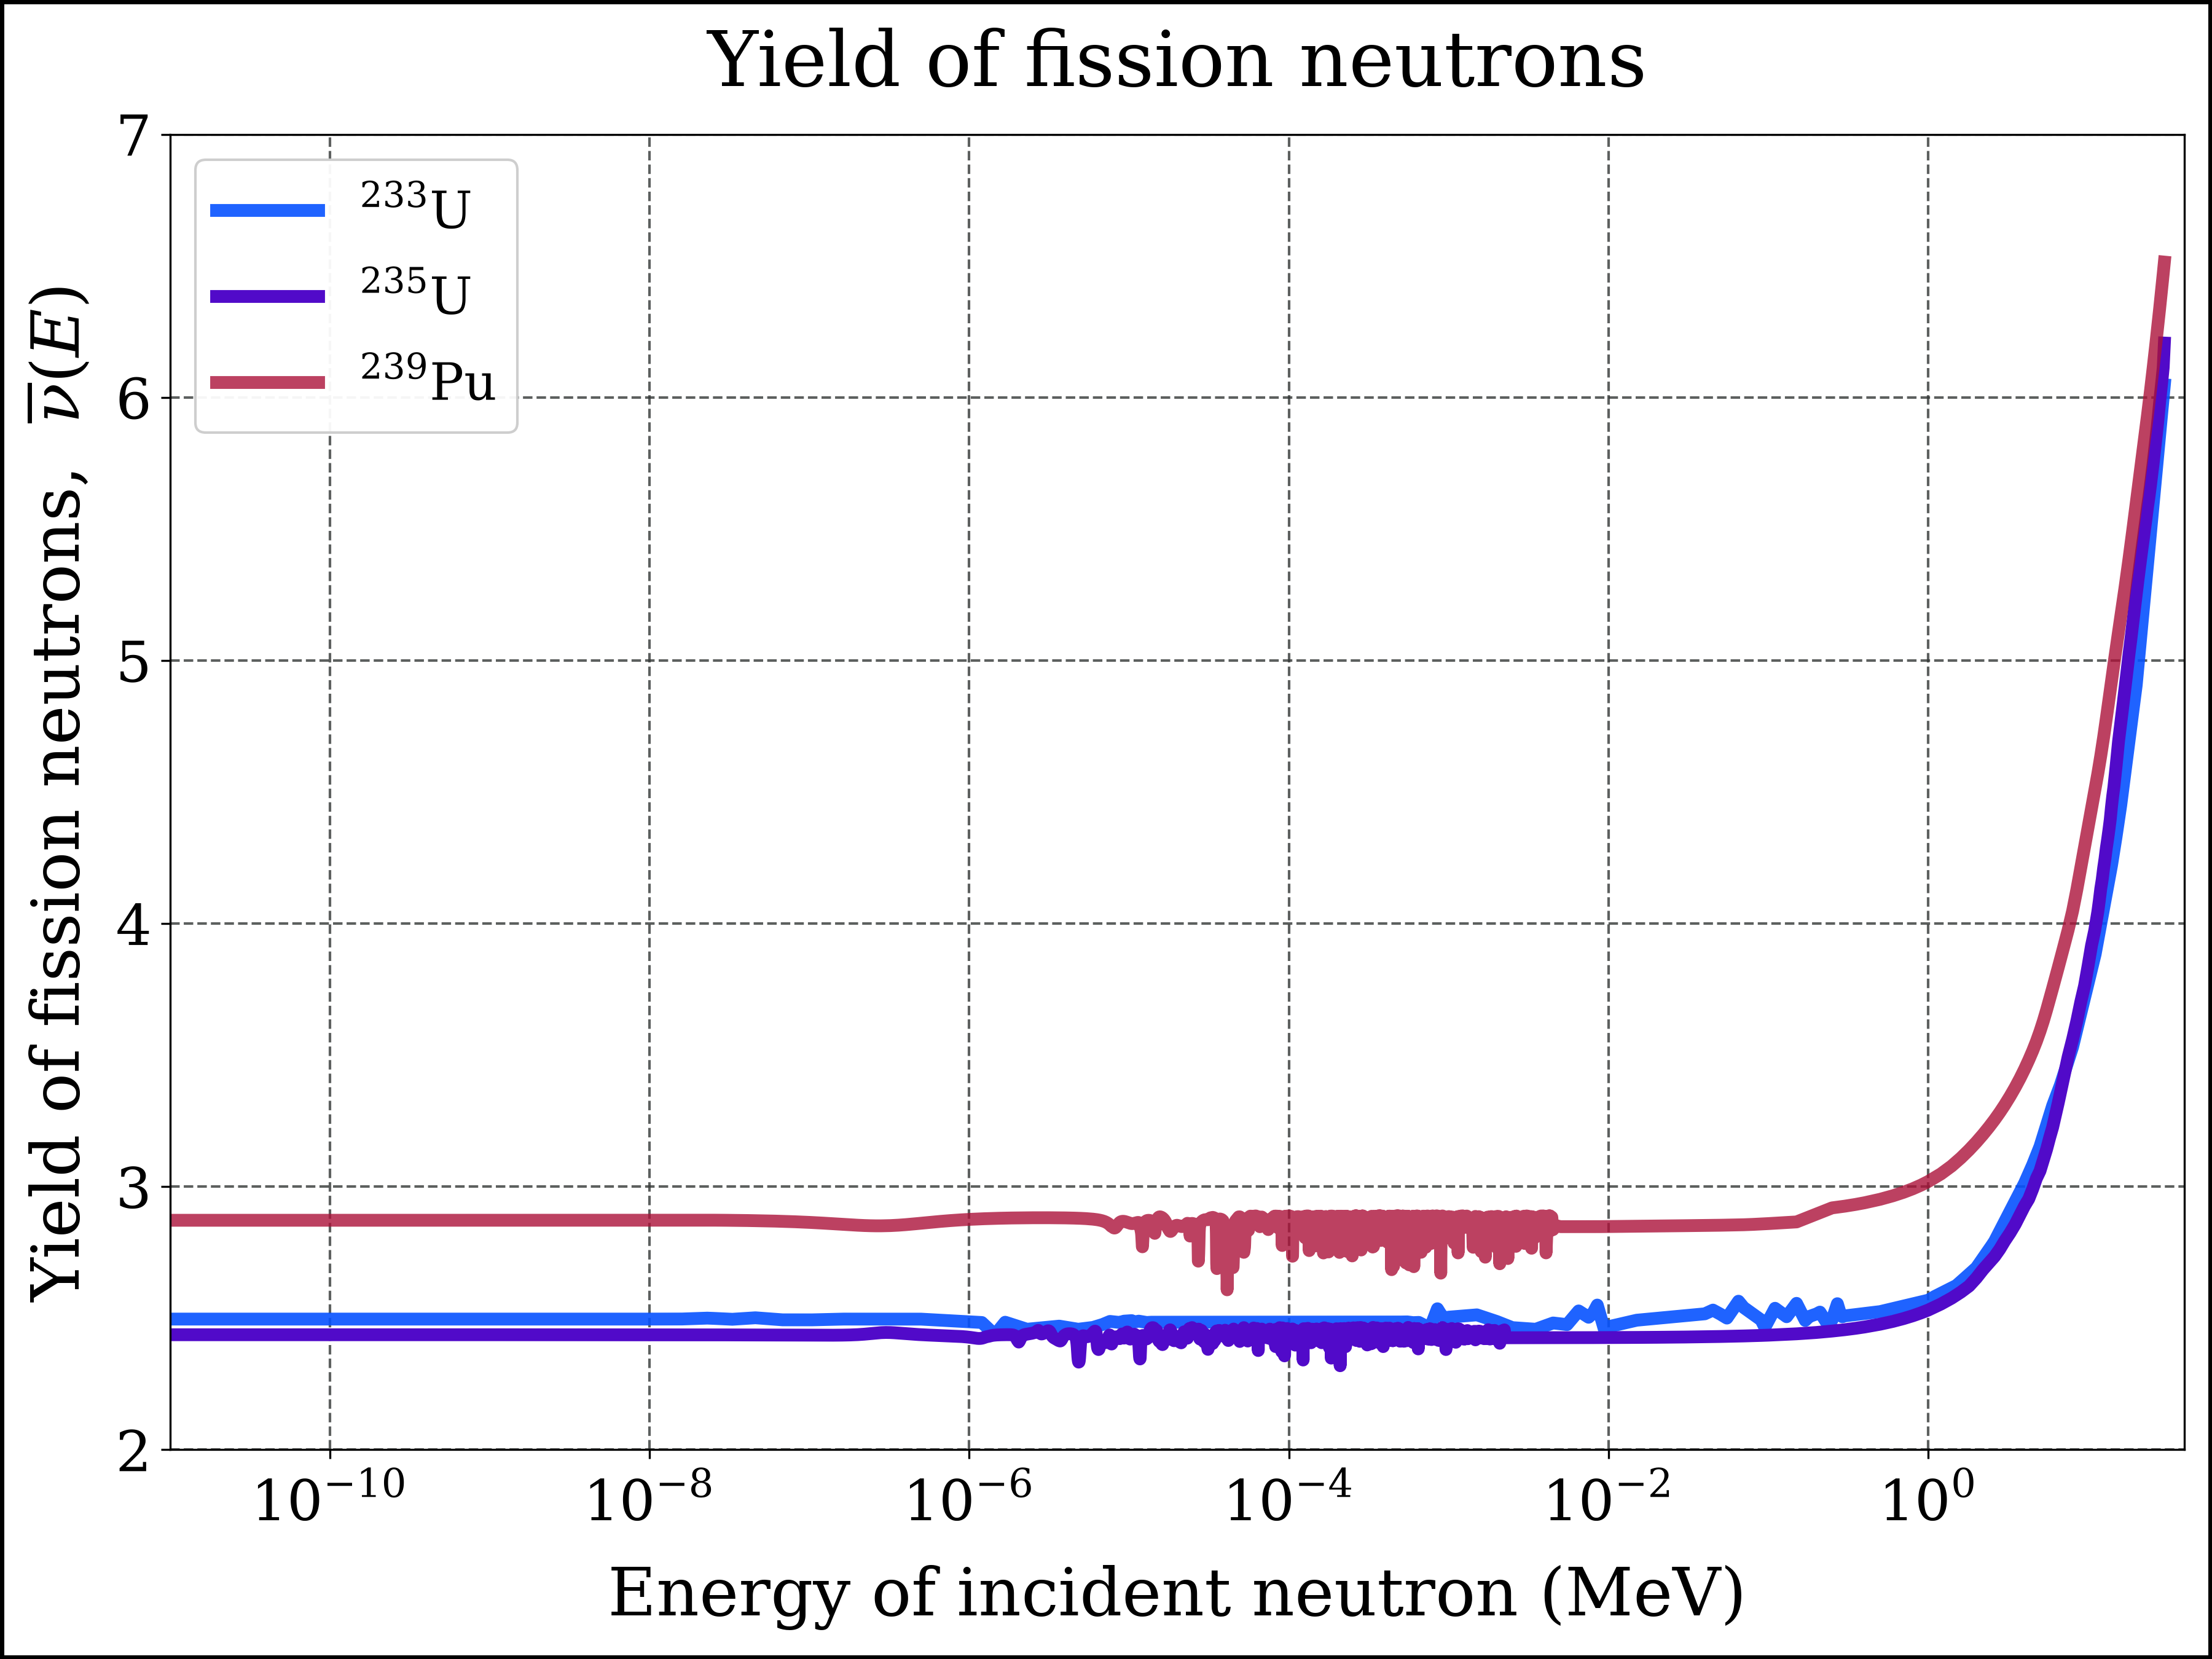

In [16]:
#| echo: true
#| label: fig-yield-fission-neutrons-mainfuel-loge
#| fig-cap: 'Average total fission neutron yield for the principal fuel isotopes - logarithmic energy scale'

fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
#
x = eng_yield_fn_u233_vec
y = yield_fn_u233_vec
axes.plot(x, y, label=r'$\mathrm{^{233}U}$',
          color=color_u233, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.9)
#
x = eng_yield_fn_u235_vec
y = yield_fn_u235_vec
axes.plot(x, y, label=r'$\mathrm{^{235}U}$',
          color=color_u235, linestyle=ls1, linewidth=lw1, marker=None)
#
x = eng_yield_fn_pu239_vec
y = yield_fn_pu239_vec
axes.plot(x, y, label=r'$\mathrm{^{239}Pu}$',
          color=color_pu239, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.8)
#
title            =  'Yield of fission neutrons'
xlabel           =  'Energy of incident neutron (MeV)'
ylabel           =  r'Yield of fission neutrons,  $\overline{\nu}(E)$'
xlims            =  [E_min, 40]
ylims            =  [2, 7]
xscale           = 'log'
yscale           =  'linear'
ncol_legend      =  1
file_name        =  'yield_fn_u233_u235_pu239_logE'
#
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

@fig-yield-fission-neutrons-mainfuel-loge shows that $\bar{\nu}$ is almost constant
from thermal energies up to about 100 keV. It is largest for $^{239}\mathrm{Pu}$
(2.87 at 0.0253 eV) and smaller for $^{233}\mathrm{U}$ (2.50) and $^{235}\mathrm{U}$
(2.44). Fission of plutonium releases a few MeV more energy than fission of uranium,
and part of this surplus appears as excitation of the fission fragments, which they
shed by emitting additional neutrons.

On a linear energy axis (@fig-yield-fission-neutrons-mainfuel-line) $\bar{\nu}$
rises almost linearly with the incident-neutron energy, by roughly 0.13 - 0.15
neutrons per MeV: the additional excitation energy brought in by the neutron mainly
heats the fission fragments, which cool down by "evaporating" more neutrons.

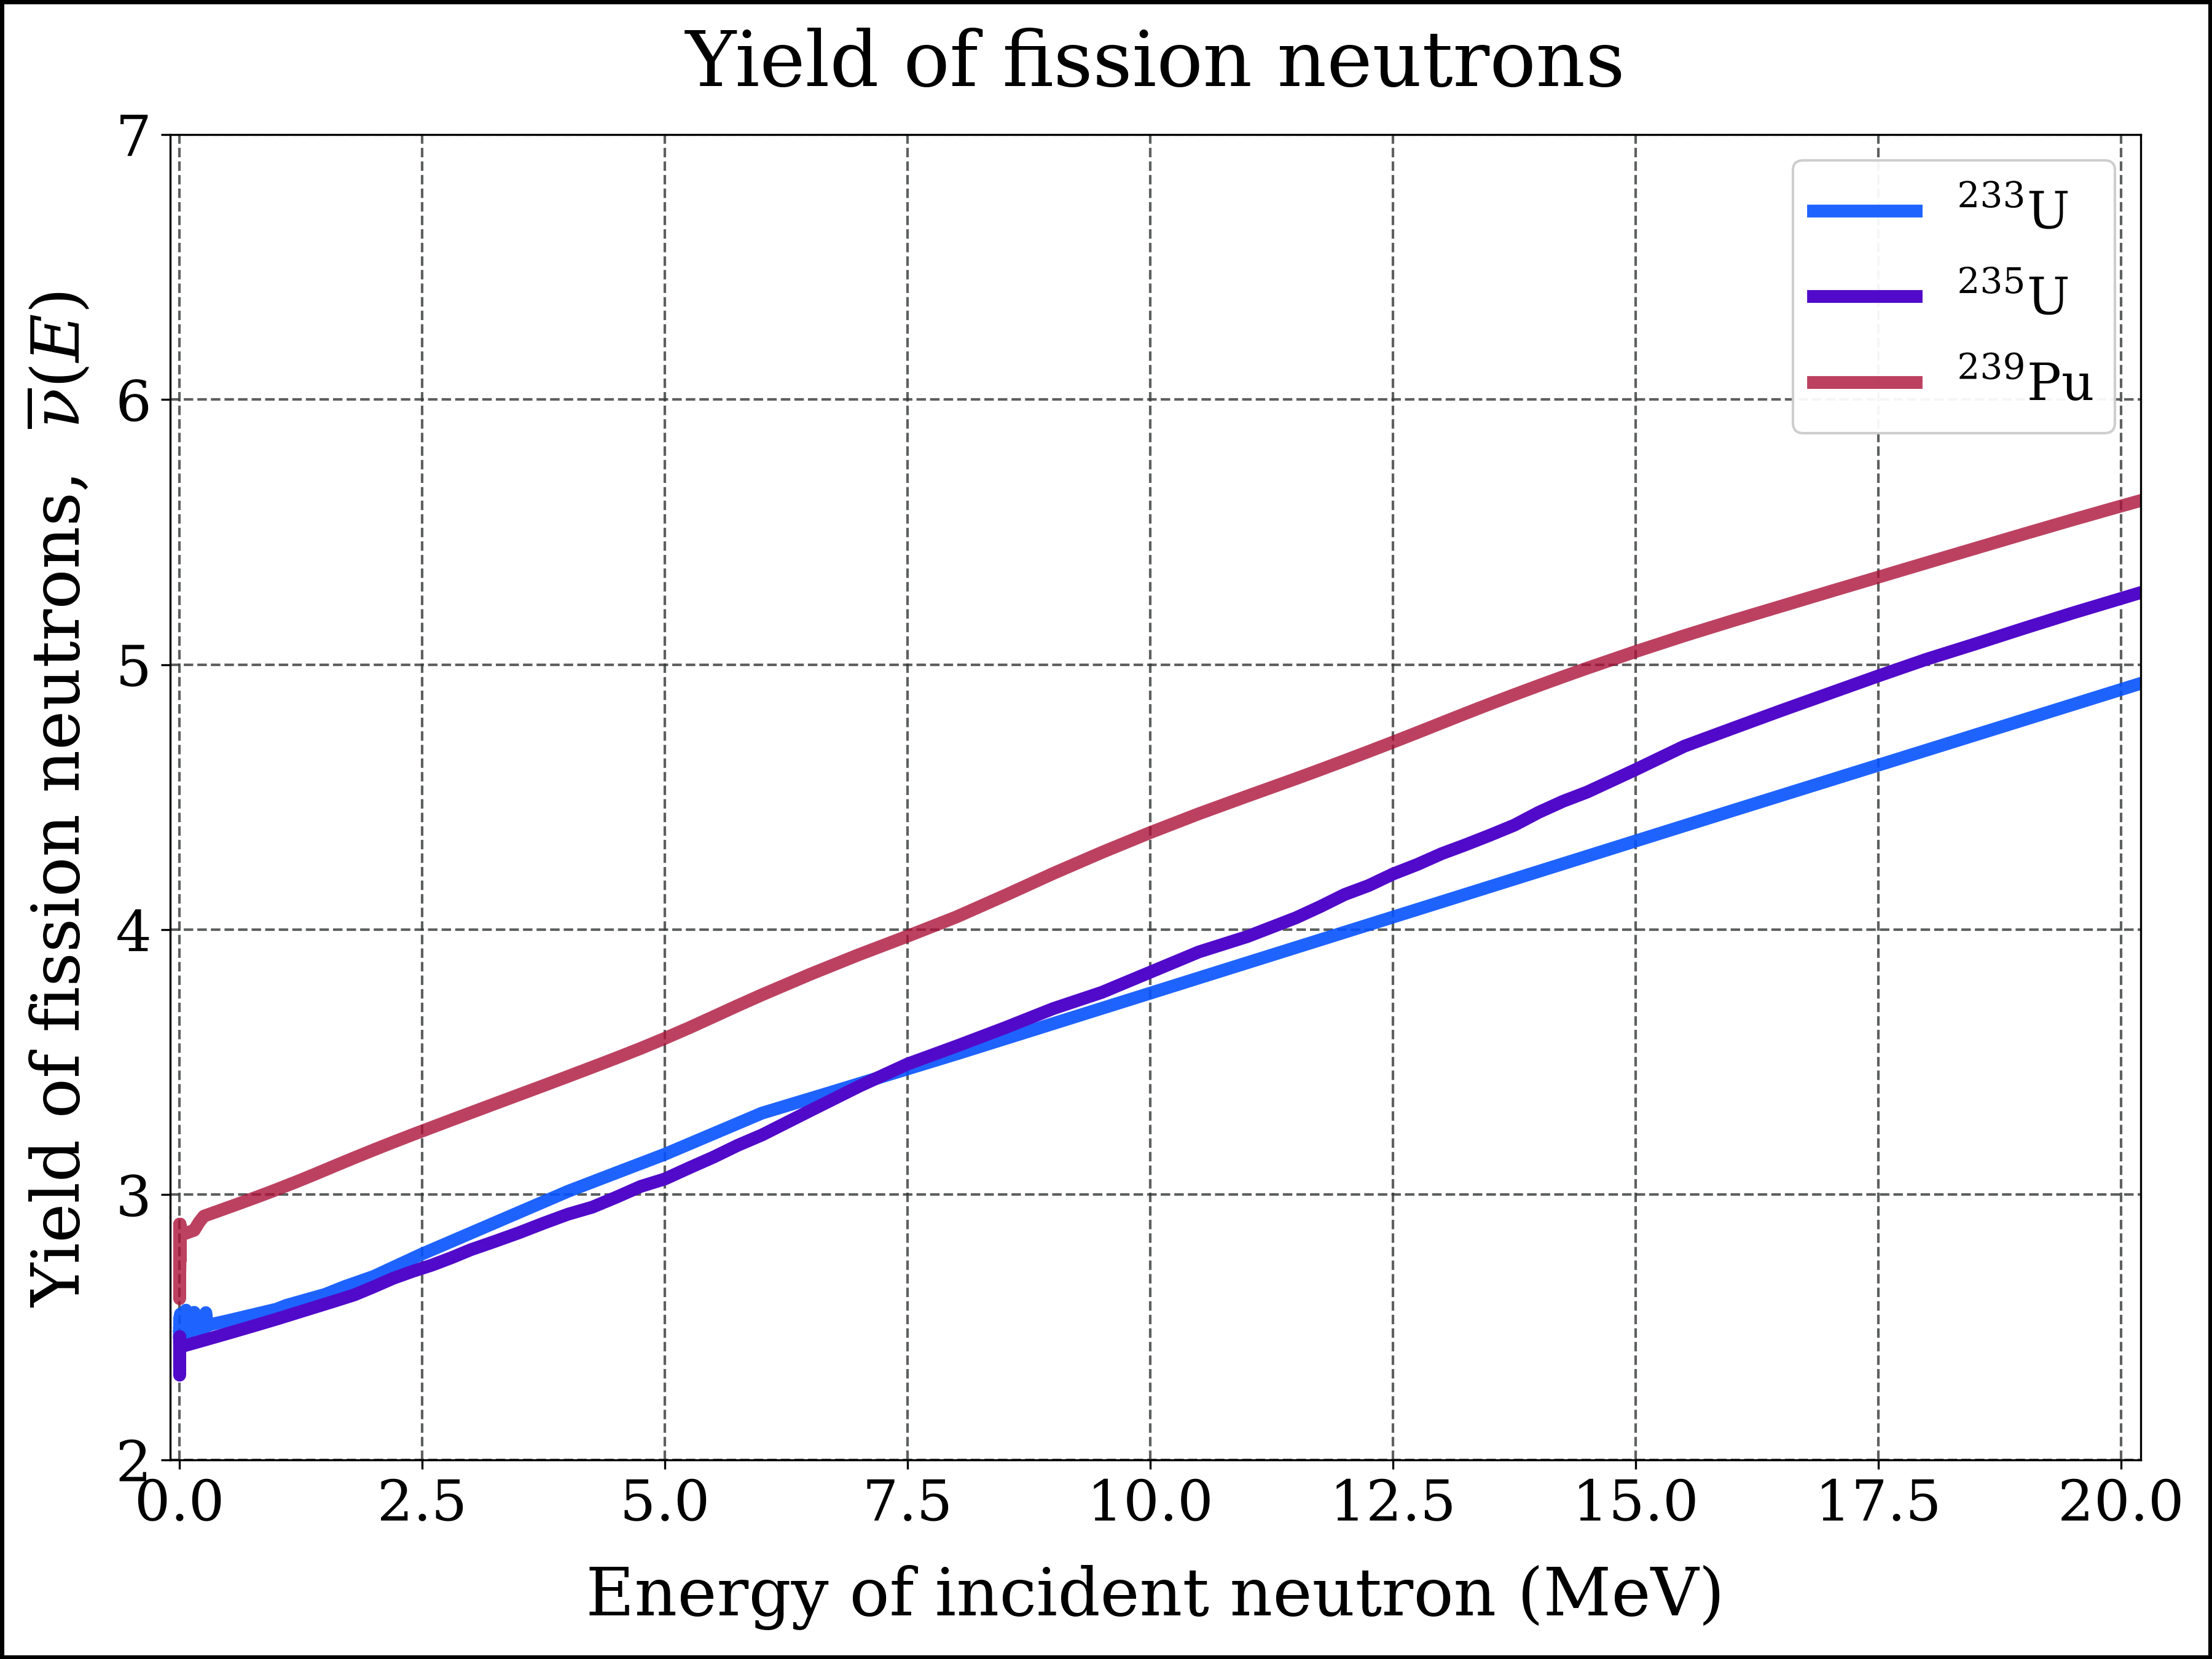

In [17]:
#| echo: true
#| label: fig-yield-fission-neutrons-mainfuel-line
#| fig-cap: 'Average total fission neutron yield for the fuel isotopes U-233, U-235, and Pu-239 - linear energy scale'

fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
#
x = eng_yield_fn_u233_vec
y = yield_fn_u233_vec
axes.plot(x, y, label=r'$\mathrm{^{233}U}$',
          color=color_u233, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.9)
#
x = eng_yield_fn_u235_vec
y = yield_fn_u235_vec
axes.plot(x, y, label=r'$\mathrm{^{235}U}$',
          color=color_u235, linestyle=ls1, linewidth=lw1, marker=None)
#
x = eng_yield_fn_pu239_vec
y = yield_fn_pu239_vec
axes.plot(x, y, label=r'$\mathrm{^{239}Pu}$',
          color=color_pu239, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.8)
#
xlims            =  [-0.1, 20.2]
xscale           =  'linear'
yscale           =  'linear'
file_name        =  'yield_fn_u233_u235_pu239_linE'
#
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

## Fissionable isotopes of uranium

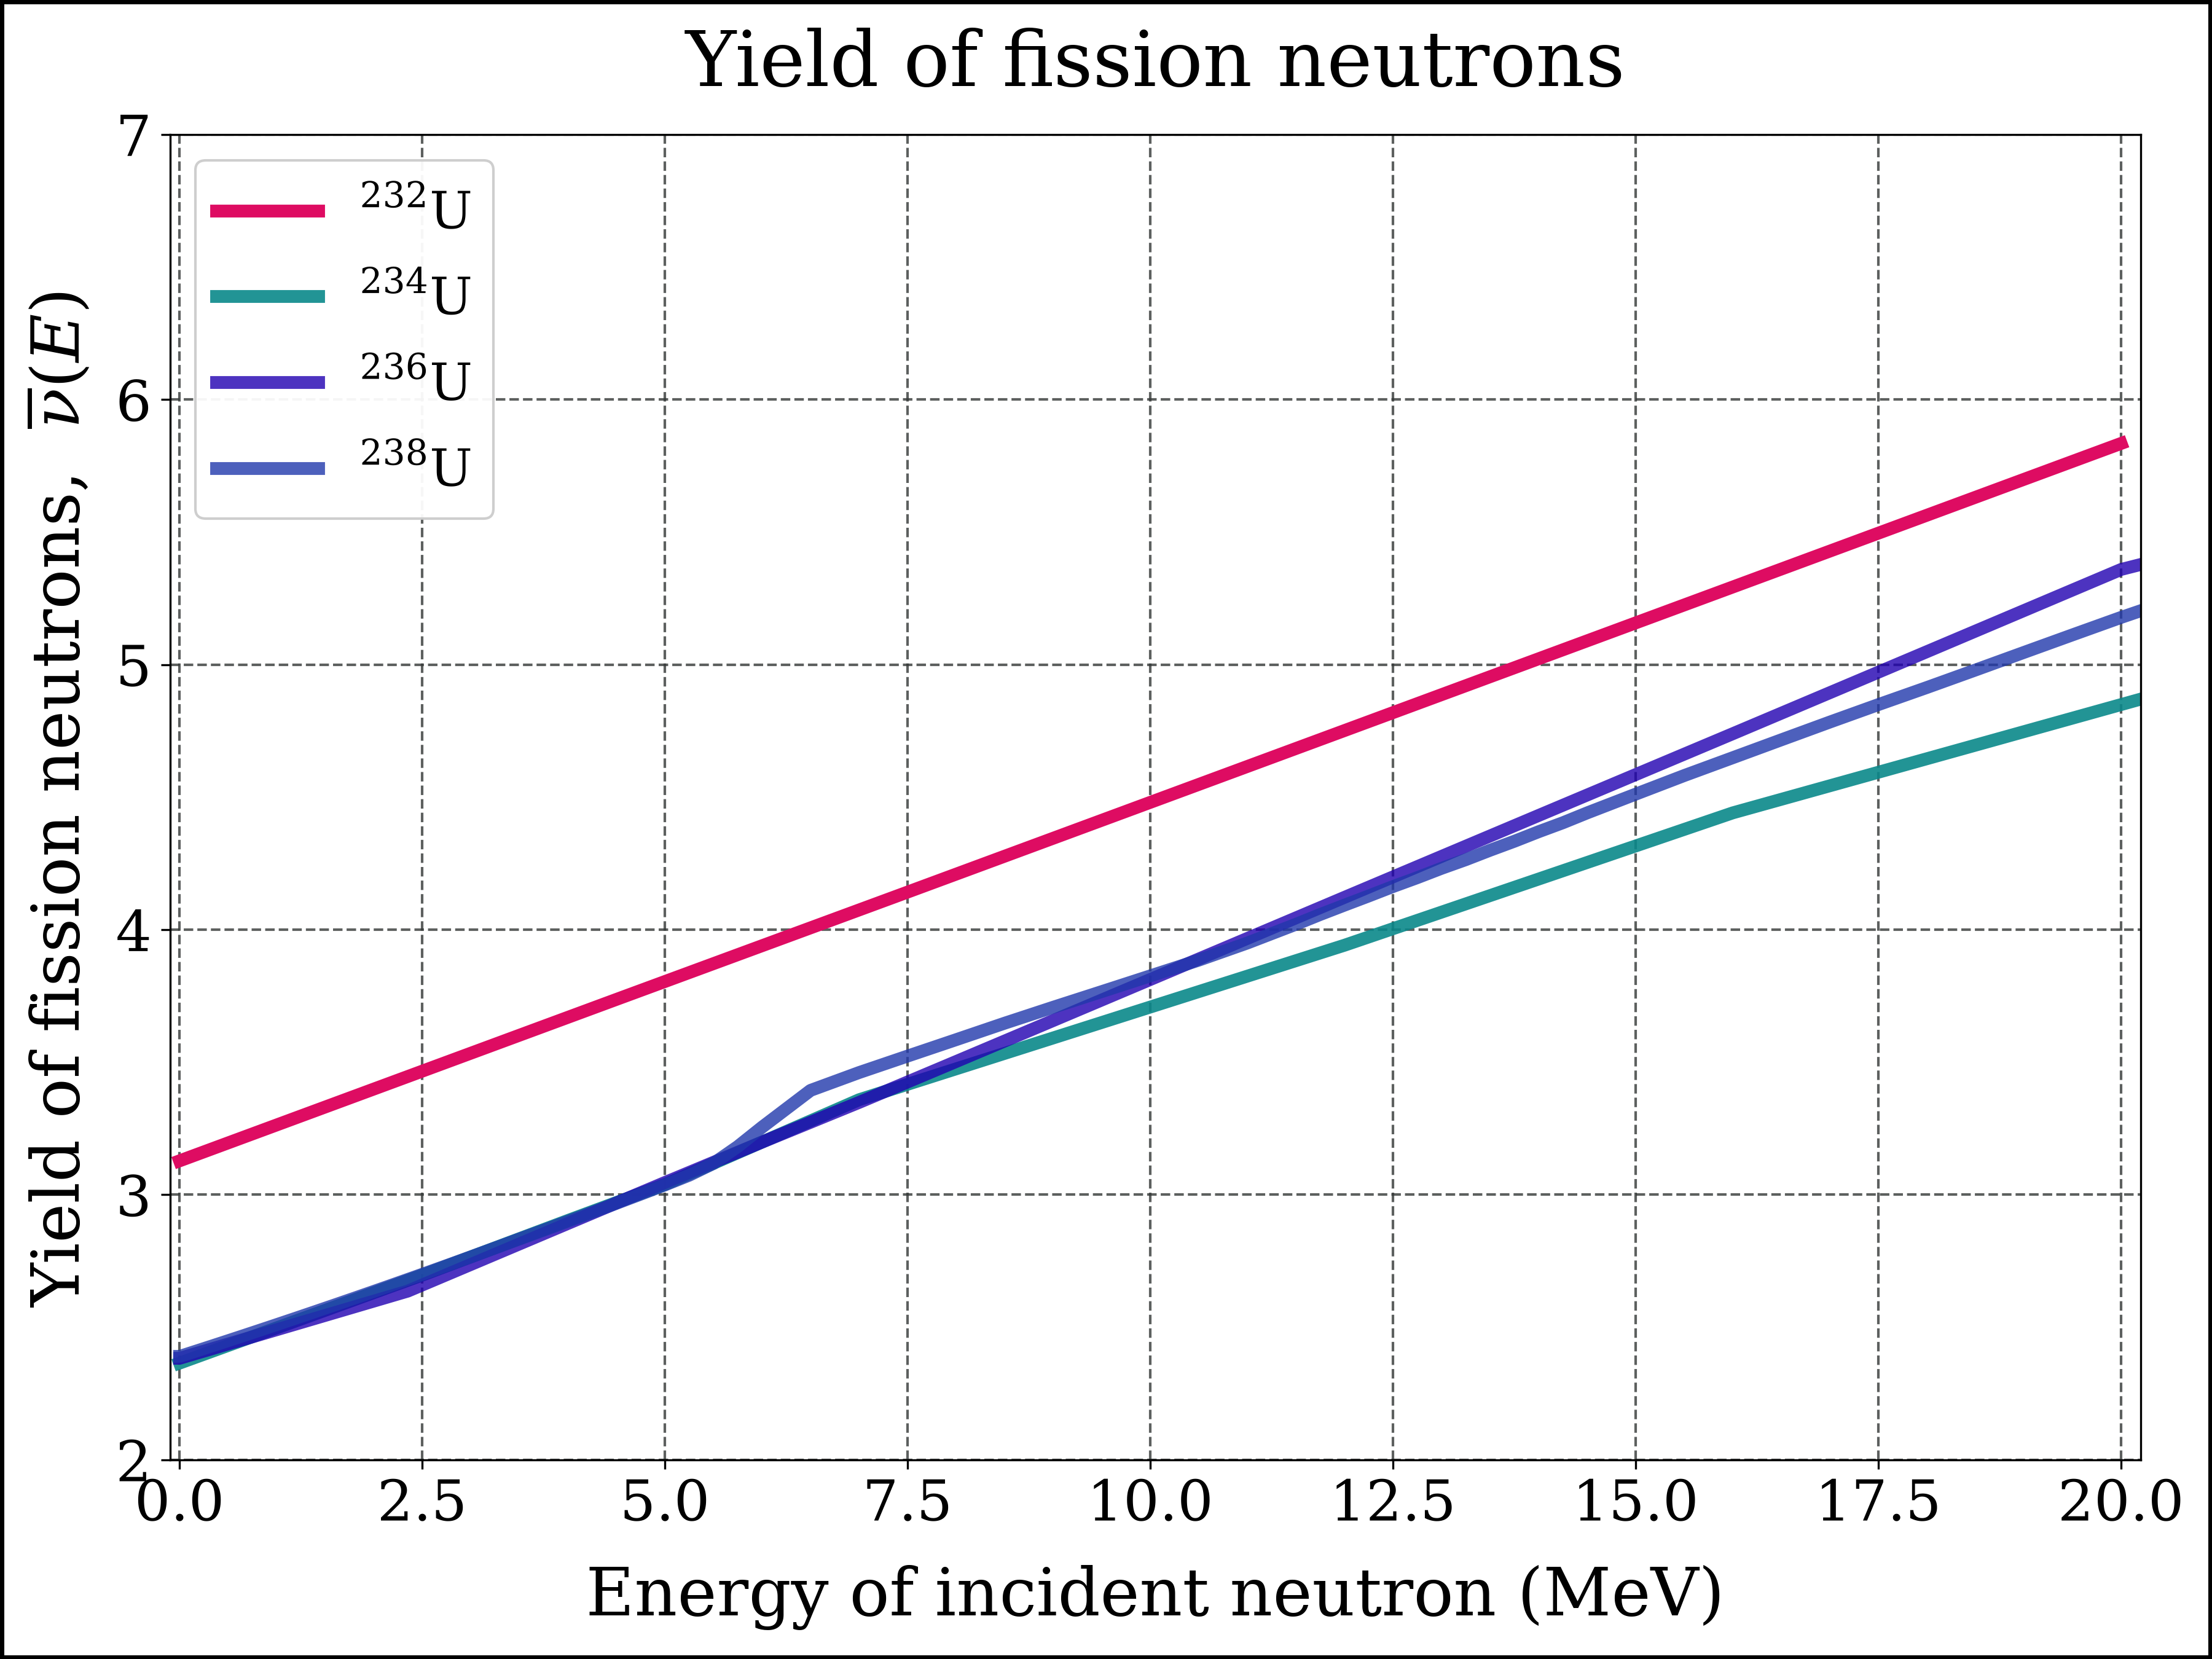

In [18]:
#| echo: true
#| label: fig-yield-fission-neutrons-fissionable-uranium-line
#| fig-cap: 'Average total fission neutron yield for fissionable isotopes of uranium'

fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
#
x = eng_yield_fn_u232_vec
y = yield_fn_u232_vec
axes.plot(x, y, label=r'$\mathrm{^{232}U}$',
          color=color_u232, linestyle=ls1, linewidth=lw1, marker=None)
#
x = eng_yield_fn_u234_vec
y = yield_fn_u234_vec
axes.plot(x, y, label=r'$\mathrm{^{234}U}$',
          color=color_u234, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.9)
#
x = eng_yield_fn_u236_vec
y = yield_fn_u236_vec
axes.plot(x, y, label=r'$\mathrm{^{236}U}$',
          color=color_u236, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.8)
#
x = eng_yield_fn_u238_vec
y = yield_fn_u238_vec
axes.plot(x, y, label=r'$\mathrm{^{238}U}$',
          color=color_u238, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.8)
#
xlims            =  [-0.1, 20.2]
ylims            =  [2, 7]
xscale           =  'linear'
yscale           =  'linear'
file_name        =  'yield_fn_u232_u234_u236_u238_logE'
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

## Fission-neutron yields of $^{238}\mathrm{Pu}$, $^{240}\mathrm{Pu}$ and $^{241}\mathrm{Pu}$

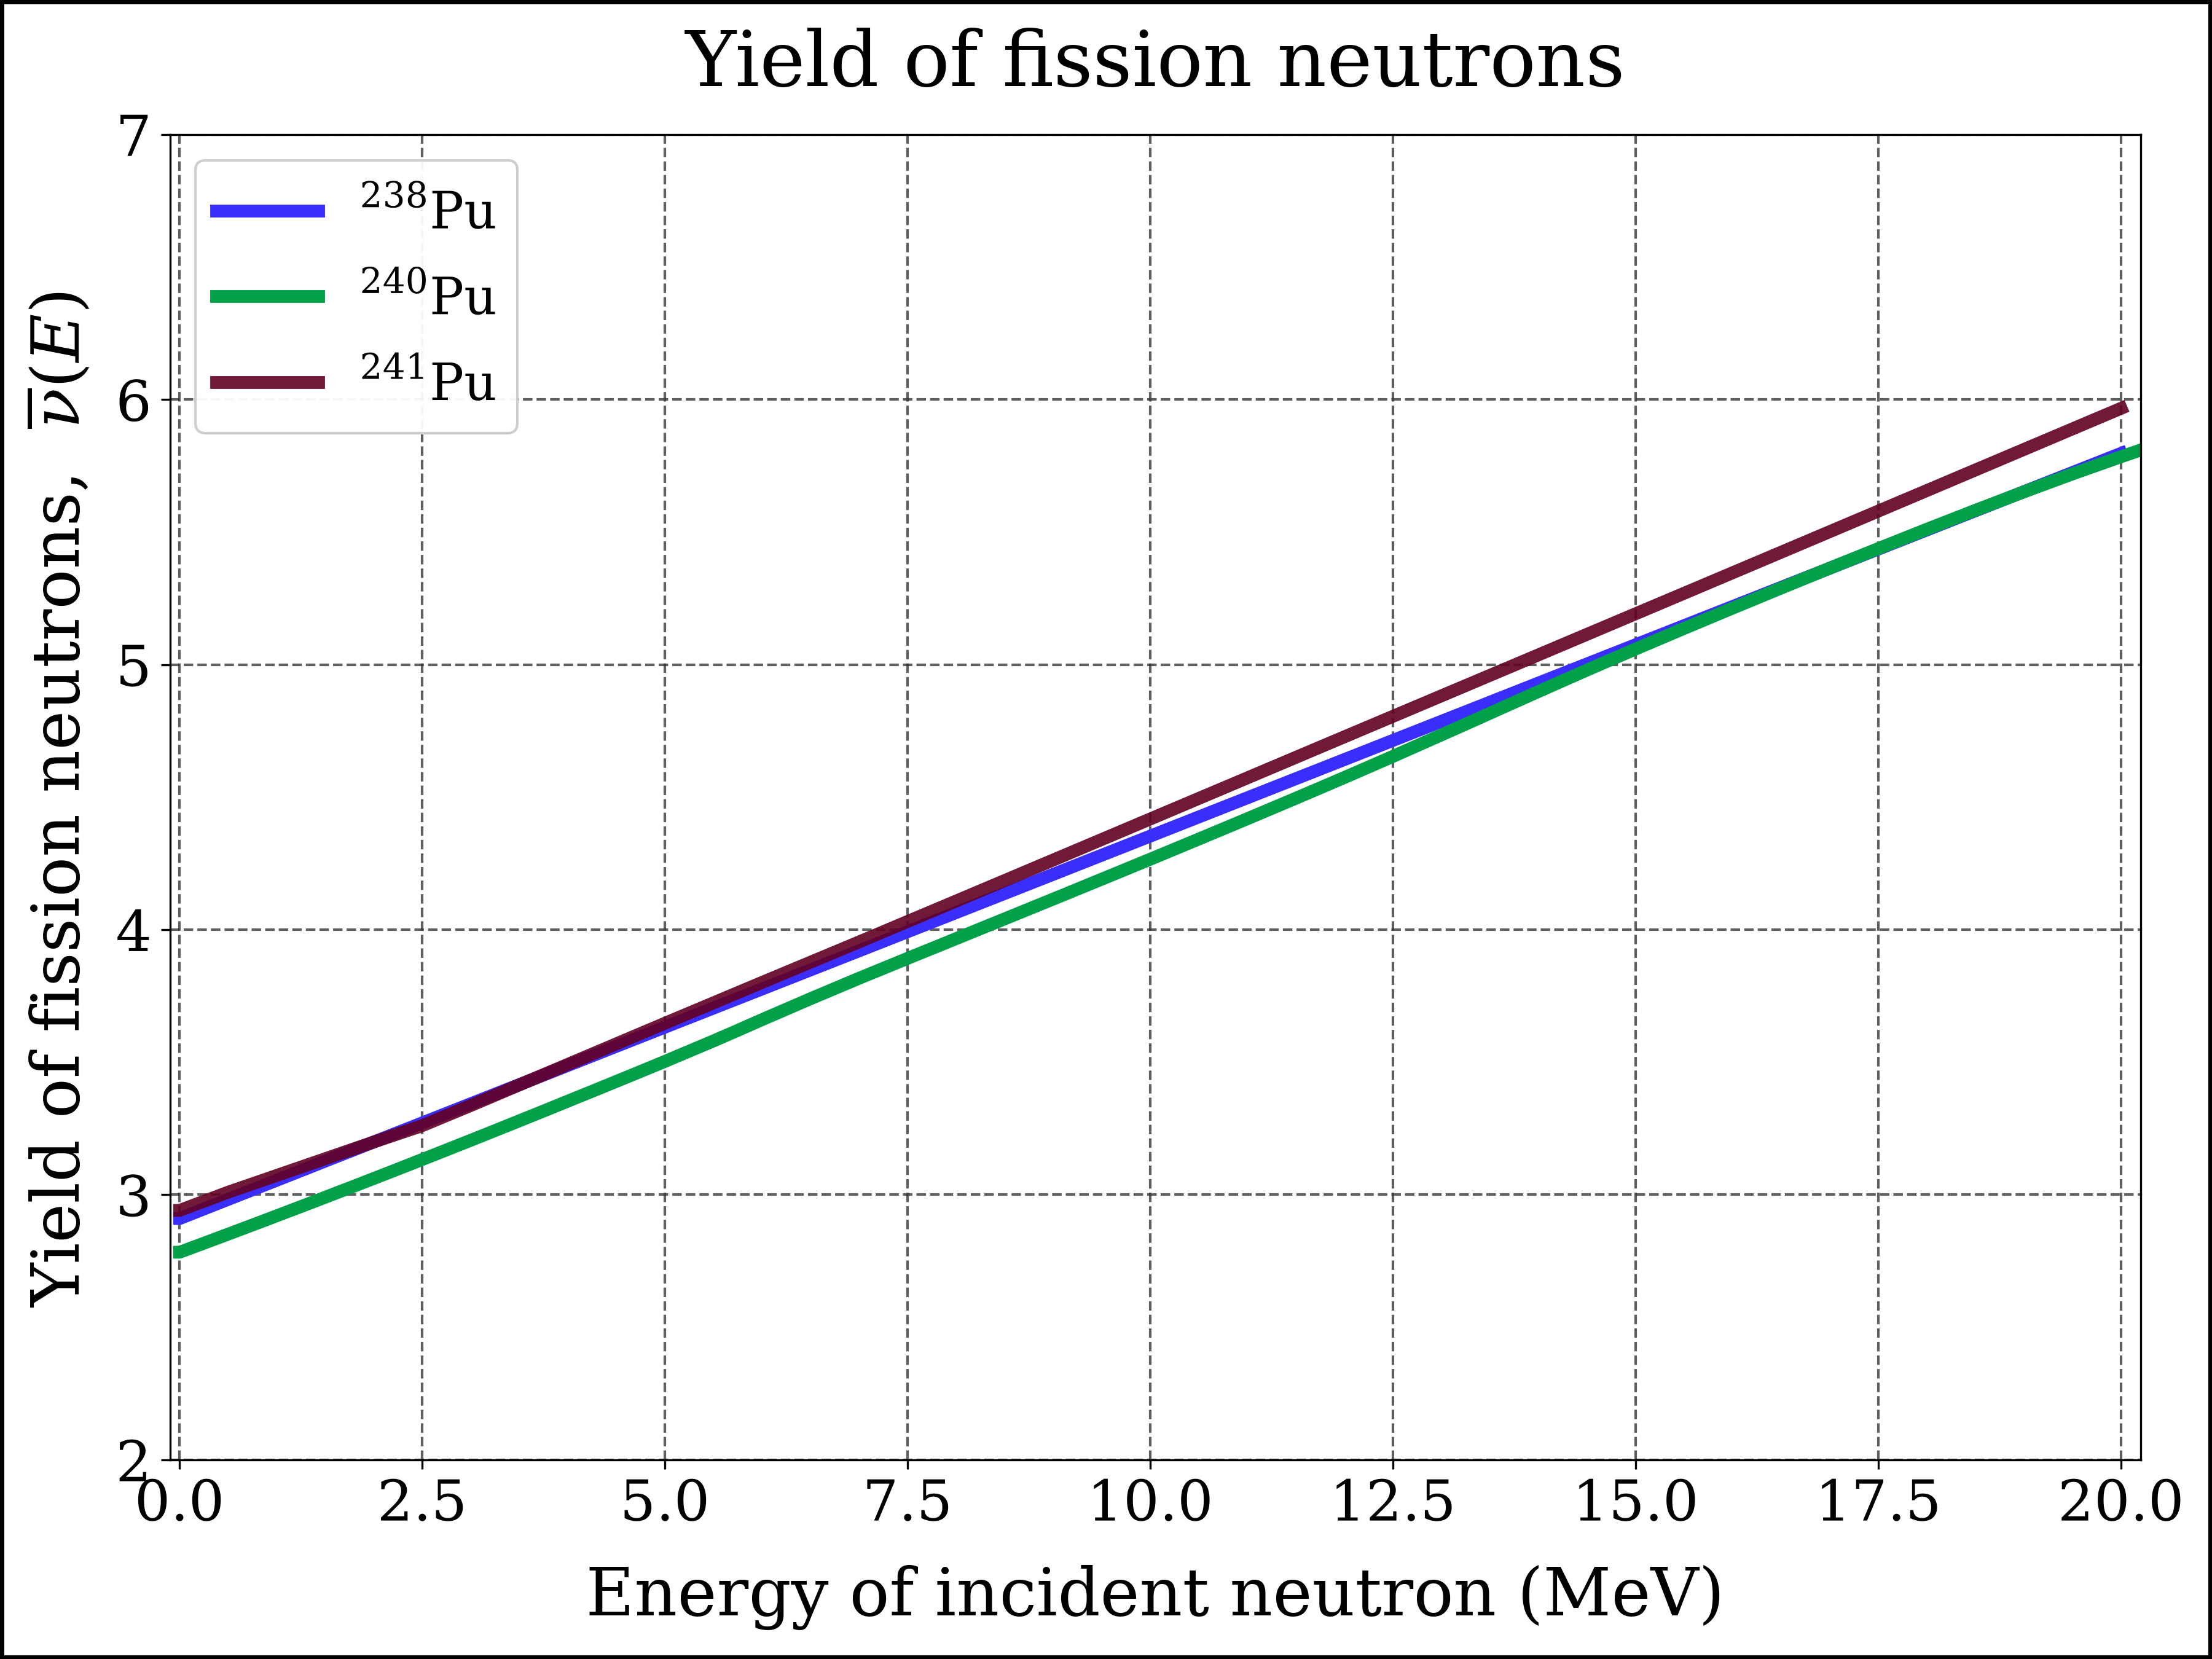

In [19]:
#| echo: true
#| label: fig-yield-fission-neutrons-other-plutonium-isotopes-line
#| fig-cap: 'Average total yield of fission neutrons, for other isotopes of plutonium'

fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
#
x = eng_yield_fn_pu238_vec
y = yield_fn_pu238_vec
axes.plot(x, y, label=r'$\mathrm{^{238}Pu}$',
          color=color_pu238, linestyle=ls1, linewidth=lw1, marker=None)
#
x = eng_yield_fn_pu240_vec
y = yield_fn_pu240_vec
axes.plot(x, y, label=r'$\mathrm{^{240}Pu}$',
          color=color_pu240, linestyle=ls1, linewidth=lw1, marker=None)
#
x = eng_yield_fn_pu241_vec
y = yield_fn_pu241_vec
axes.plot(x, y, label=r'$\mathrm{^{241}Pu}$',
          color=color_pu241, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.9)
#
xlims            =  [-0.1, 20.2]
ylims            =  [2, 7.0]
xscale           =  'linear'
yscale           =  'linear'
file_name        =  'yield_fn_pu238_pu240_pu241_linE'
#
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

$^{238}\mathrm{Pu}$ emits on average `{python} f"{yield_fn_pu238(2.53E-08):.2f}"`
neutrons per fission induced by a thermal neutron - about as many as $^{239}\mathrm{Pu}$
(`{python} f"{yield_fn_pu239(2.53E-08):.2f}"`) - and, like every nuclide, more at higher
incident-neutron energies (@fig-yield-fission-neutrons-other-plutonium-isotopes-line).

# Building the functions $\eta(E)$ {#sec-build-eta}

## The spectrum as a continuous function

In [20]:
# ϕ_n(E): neutron fluence rate per unit energy (MeV⁻¹ cm⁻² s⁻¹), E in MeV
x = eng_φ_vec
y = φ_vec
ϕ_n = PchipInterpolator(x, y, extrapolate=None)

## Spot check of an interpolated cross section

At low energies the fission cross section of $^{233}\mathrm{U}$ follows the
**1/v law**, $\sigma\propto 1/v\propto 1/\sqrt{E}$: from $10^{-10}$ to $10^{-8}$ MeV
(two decades in energy) it falls by one decade. Above about 1 eV the resonance
region begins, and in the MeV region the cross section is only about 2 b.

In [21]:
# Spot values of the interpolated U-233 fission cross section.
# 0.0253 eV (2.53E-08 MeV) is the conventional 'thermal' energy: kT at 20 °C,
# which corresponds to the most probable neutron speed of 2200 m/s.
# Testing:
σ = σ_nf_u233

print('σ(1.1E-11) = ', "{:.2e}".format(σ(1.1E-11)), 'barn')
print('σ(1.0E-10) = ', "{:.2e}".format(σ(1.0E-10)), 'barn')
print('σ(1.0E-09) = ', "{:.2e}".format(σ(1.0E-09)), 'barn')
print('σ(1.0E-08) = ', "{:.2e}".format(σ(1.0E-08)), 'barn')
print('σ(1.0E-07) = ', "{:.2e}".format(σ(1.0E-07)), 'barn')
print('σ(1.0E-06) = ', "{:.2e}".format(σ(1.0E-06)), 'barn')
print('σ(1.0E-05) = ', "{:.2e}".format(σ(1.0E-05)), 'barn')
print('σ(1.0E-04) = ', "{:.2e}".format(σ(1.0E-04)), 'barn')
print('σ(1.0E-03) = ', "{:.2e}".format(σ(1.0E-03)), 'barn')
print('σ(1.0E-02) = ', "{:.2e}".format(σ(1.0E-02)), 'barn')
print('σ(1.0E-01) = ', "{:.2e}".format(σ(1.0E-01)), 'barn')
print('σ(1.00000) = ', "{:.2e}".format(σ(1.00000)), 'barn')
print('σ(2.00000) = ', "{:.2e}".format(σ(2.00000)), 'barn')
print('σ(3.00000) = ', "{:.2e}".format(σ(3.00000)), 'barn')
print('σ(4.00000) = ', "{:.2e}".format(σ(4.00000)), 'barn')
print('σ(5.00000) = ', "{:.2e}".format(σ(5.00000)), 'barn')
print('σ(6.00000) = ', "{:.2e}".format(σ(6.00000)), 'barn')
print('σ(7.00000) = ', "{:.2e}".format(σ(7.00000)), 'barn')
print('σ(8.00000) = ', "{:.2e}".format(σ(8.00000)), 'barn')
print('σ(9.00000) = ', "{:.2e}".format(σ(9.00000)), 'barn')
print('σ(10.0000) = ', "{:.2e}".format(σ(10.0000)), 'barn')
print('σ(12.0000) = ', "{:.2e}".format(σ(12.0000)), 'barn')
print('σ(19.9000) = ', "{:.2e}".format(σ(19.9000)), 'barn')

σ(1.1E-11) =  2.57e+04 barn
σ(1.0E-10) =  8.52e+03 barn
σ(1.0E-09) =  2.69e+03 barn
σ(1.0E-08) =  8.51e+02 barn
σ(1.0E-07) =  2.61e+02 barn
σ(1.0E-06) =  1.38e+02 barn
σ(1.0E-05) =  1.05e+02 barn
σ(1.0E-04) =  5.37e+01 barn
σ(1.0E-03) =  2.34e+01 barn
σ(1.0E-02) =  3.82e+00 barn
σ(1.0E-01) =  2.22e+00 barn
σ(1.00000) =  1.84e+00 barn
σ(2.00000) =  1.96e+00 barn
σ(3.00000) =  1.85e+00 barn
σ(4.00000) =  1.69e+00 barn
σ(5.00000) =  1.57e+00 barn
σ(6.00000) =  1.64e+00 barn
σ(7.00000) =  2.07e+00 barn
σ(8.00000) =  2.27e+00 barn
σ(9.00000) =  2.29e+00 barn
σ(10.0000) =  2.26e+00 barn
σ(12.0000) =  2.17e+00 barn
σ(19.9000) =  2.29e+00 barn


## The functions $\eta(E)$

@eq-eta-E is coded once for every nuclide:

In [22]:
# η(E) = ν̄(E) σ_f(E) / (σ_f(E) + σ_γ(E))     (eq-eta-E)
# The functions accept a scalar energy or a NumPy array of energies (MeV).
def nrf_u232(E):
    return (yield_fn_u232(E) * σ_nf_u232(E)) / (σ_nf_u232(E) + σ_nγ_u232(E))
    
def nrf_u233(E):
    return (yield_fn_u233(E) * σ_nf_u233(E)) / (σ_nf_u233(E) + σ_nγ_u233(E))
    
def nrf_u234(E):
    return (yield_fn_u234(E) * σ_nf_u234(E)) / (σ_nf_u234(E) + σ_nγ_u234(E))

def nrf_u235(E):
    return (yield_fn_u235(E) * σ_nf_u235(E)) / (σ_nf_u235(E) + σ_nγ_u235(E))
    
def nrf_u236(E):
    return (yield_fn_u236(E) * σ_nf_u236(E)) / (σ_nf_u236(E) + σ_nγ_u236(E))

def nrf_u238(E):
    return (yield_fn_u238(E) * σ_nf_u238(E)) / (σ_nf_u238(E) + σ_nγ_u238(E))

def nrf_pu238(E):
    return (yield_fn_pu238(E) * σ_nf_pu238(E)) / (σ_nf_pu238(E) + σ_nγ_pu238(E))

def nrf_pu239(E):
    return (yield_fn_pu239(E) * σ_nf_pu239(E)) / (σ_nf_pu239(E) + σ_nγ_pu239(E))

def nrf_pu240(E):
    return (yield_fn_pu240(E) * σ_nf_pu240(E)) / (σ_nf_pu240(E) + σ_nγ_pu240(E))

def nrf_pu241(E):
    return (yield_fn_pu241(E) * σ_nf_pu241(E)) / (σ_nf_pu241(E) + σ_nγ_pu241(E))

## Thermal point values (0.0253 eV) {#sec-thermal-point}

At the thermal reference energy of 0.0253 eV the four fissile nuclides compare as
follows; $^{238}\mathrm{Pu}$ is added for contrast. The capture-to-fission ratio
$\alpha$ explains the ranking of $\eta$ better than $\bar{\nu}$ does. (These are
values of the interpolated data at one energy - no integration, hence no
numerical error.)

In [23]:
# Thermal (2200 m/s) values of ν̄, σ_f, σ_γ, α and η for the fissile nuclides
# and, for contrast, for Pu-238:
E_th = 2.53E-08   # MeV  (= 0.0253 eV)

thermal_point = {
    'U-233':  (yield_fn_u233,  σ_nf_u233,  σ_nγ_u233),
    'U-235':  (yield_fn_u235,  σ_nf_u235,  σ_nγ_u235),
    'Pu-238': (yield_fn_pu238, σ_nf_pu238, σ_nγ_pu238),
    'Pu-239': (yield_fn_pu239, σ_nf_pu239, σ_nγ_pu239),
    'Pu-241': (yield_fn_pu241, σ_nf_pu241, σ_nγ_pu241),
}

print('Nuclide     ν̄      σ_f (b)   σ_γ (b)     α       η')
for name, (ν, σ_f, σ_γ) in thermal_point.items():
    α = σ_γ(E_th) / σ_f(E_th)            # capture-to-fission ratio
    η = ν(E_th) / (1 + α)                # eq-eta-E, written with α
    print(f'{name:8}{ν(E_th):7.3f}{σ_f(E_th):10.1f}{σ_γ(E_th):10.1f}{α:9.3f}{η:8.3f}')

Nuclide     ν̄      σ_f (b)   σ_γ (b)     α       η
U-233     2.499     532.9      45.2    0.085   2.304
U-235     2.437     586.1      99.4    0.170   2.083
Pu-238    2.910      16.0     534.9   33.505   0.084
Pu-239    2.873     750.7     271.4    0.362   2.110
Pu-241    2.941    1023.7     364.0    0.356   2.170


## $\eta$ of enriched uranium {#sec-enrichment}

@eq-eta-enriched evaluated at 0.0253 eV shows how quickly $\eta$ of uranium fuel
rises with enrichment - and that it saturates: above about 20 % enrichment the
$^{238}\mathrm{U}$ absorptions hardly matter any more. (Point values at 0.0253 eV;
the thermal-group values that belong in the four-factor formula follow in @sec-leu.)

In [24]:
# Thermal η of uranium as a function of the U-235 atom fraction e  (eq-eta-mixture):
#   production = N5 ν5 σf5 + N8 ν8 σf8,   absorption = N5 σa5 + N8 σa8,   N8/N5 = (1-e)/e
def eta_uranium(e, E=E_th):
    r = (1 - e) / e                                   # N(U-238) / N(U-235)
    production = yield_fn_u235(E)*σ_nf_u235(E) + r*yield_fn_u238(E)*σ_nf_u238(E)
    absorption = (σ_nf_u235(E) + σ_nγ_u235(E)) + r*(σ_nf_u238(E) + σ_nγ_u238(E))
    return production / absorption

print('U-235 atom fraction    η (0.0253 eV)')
for e, label in [(0.00711, 'natural'), (0.03, ''), (0.05, ''), (0.20, 'HALEU limit'), (0.93, 'HEU')]:
    print(f'   {e:8.2%}  {label:12}{eta_uranium(e):8.3f}')

U-235 atom fraction    η (0.0253 eV)
      0.71%  natural        1.346
      3.00%                 1.849
      5.00%                 1.939
     20.00%  HALEU limit    2.051
     93.00%  HEU            2.083


# Energy dependence of $\eta(E)$ {#sec-eta-curves}

The following graphs show $\eta(E)$ for each nuclide over the full energy range,
followed by comparisons of the fissile and the fertile uranium isotopes.

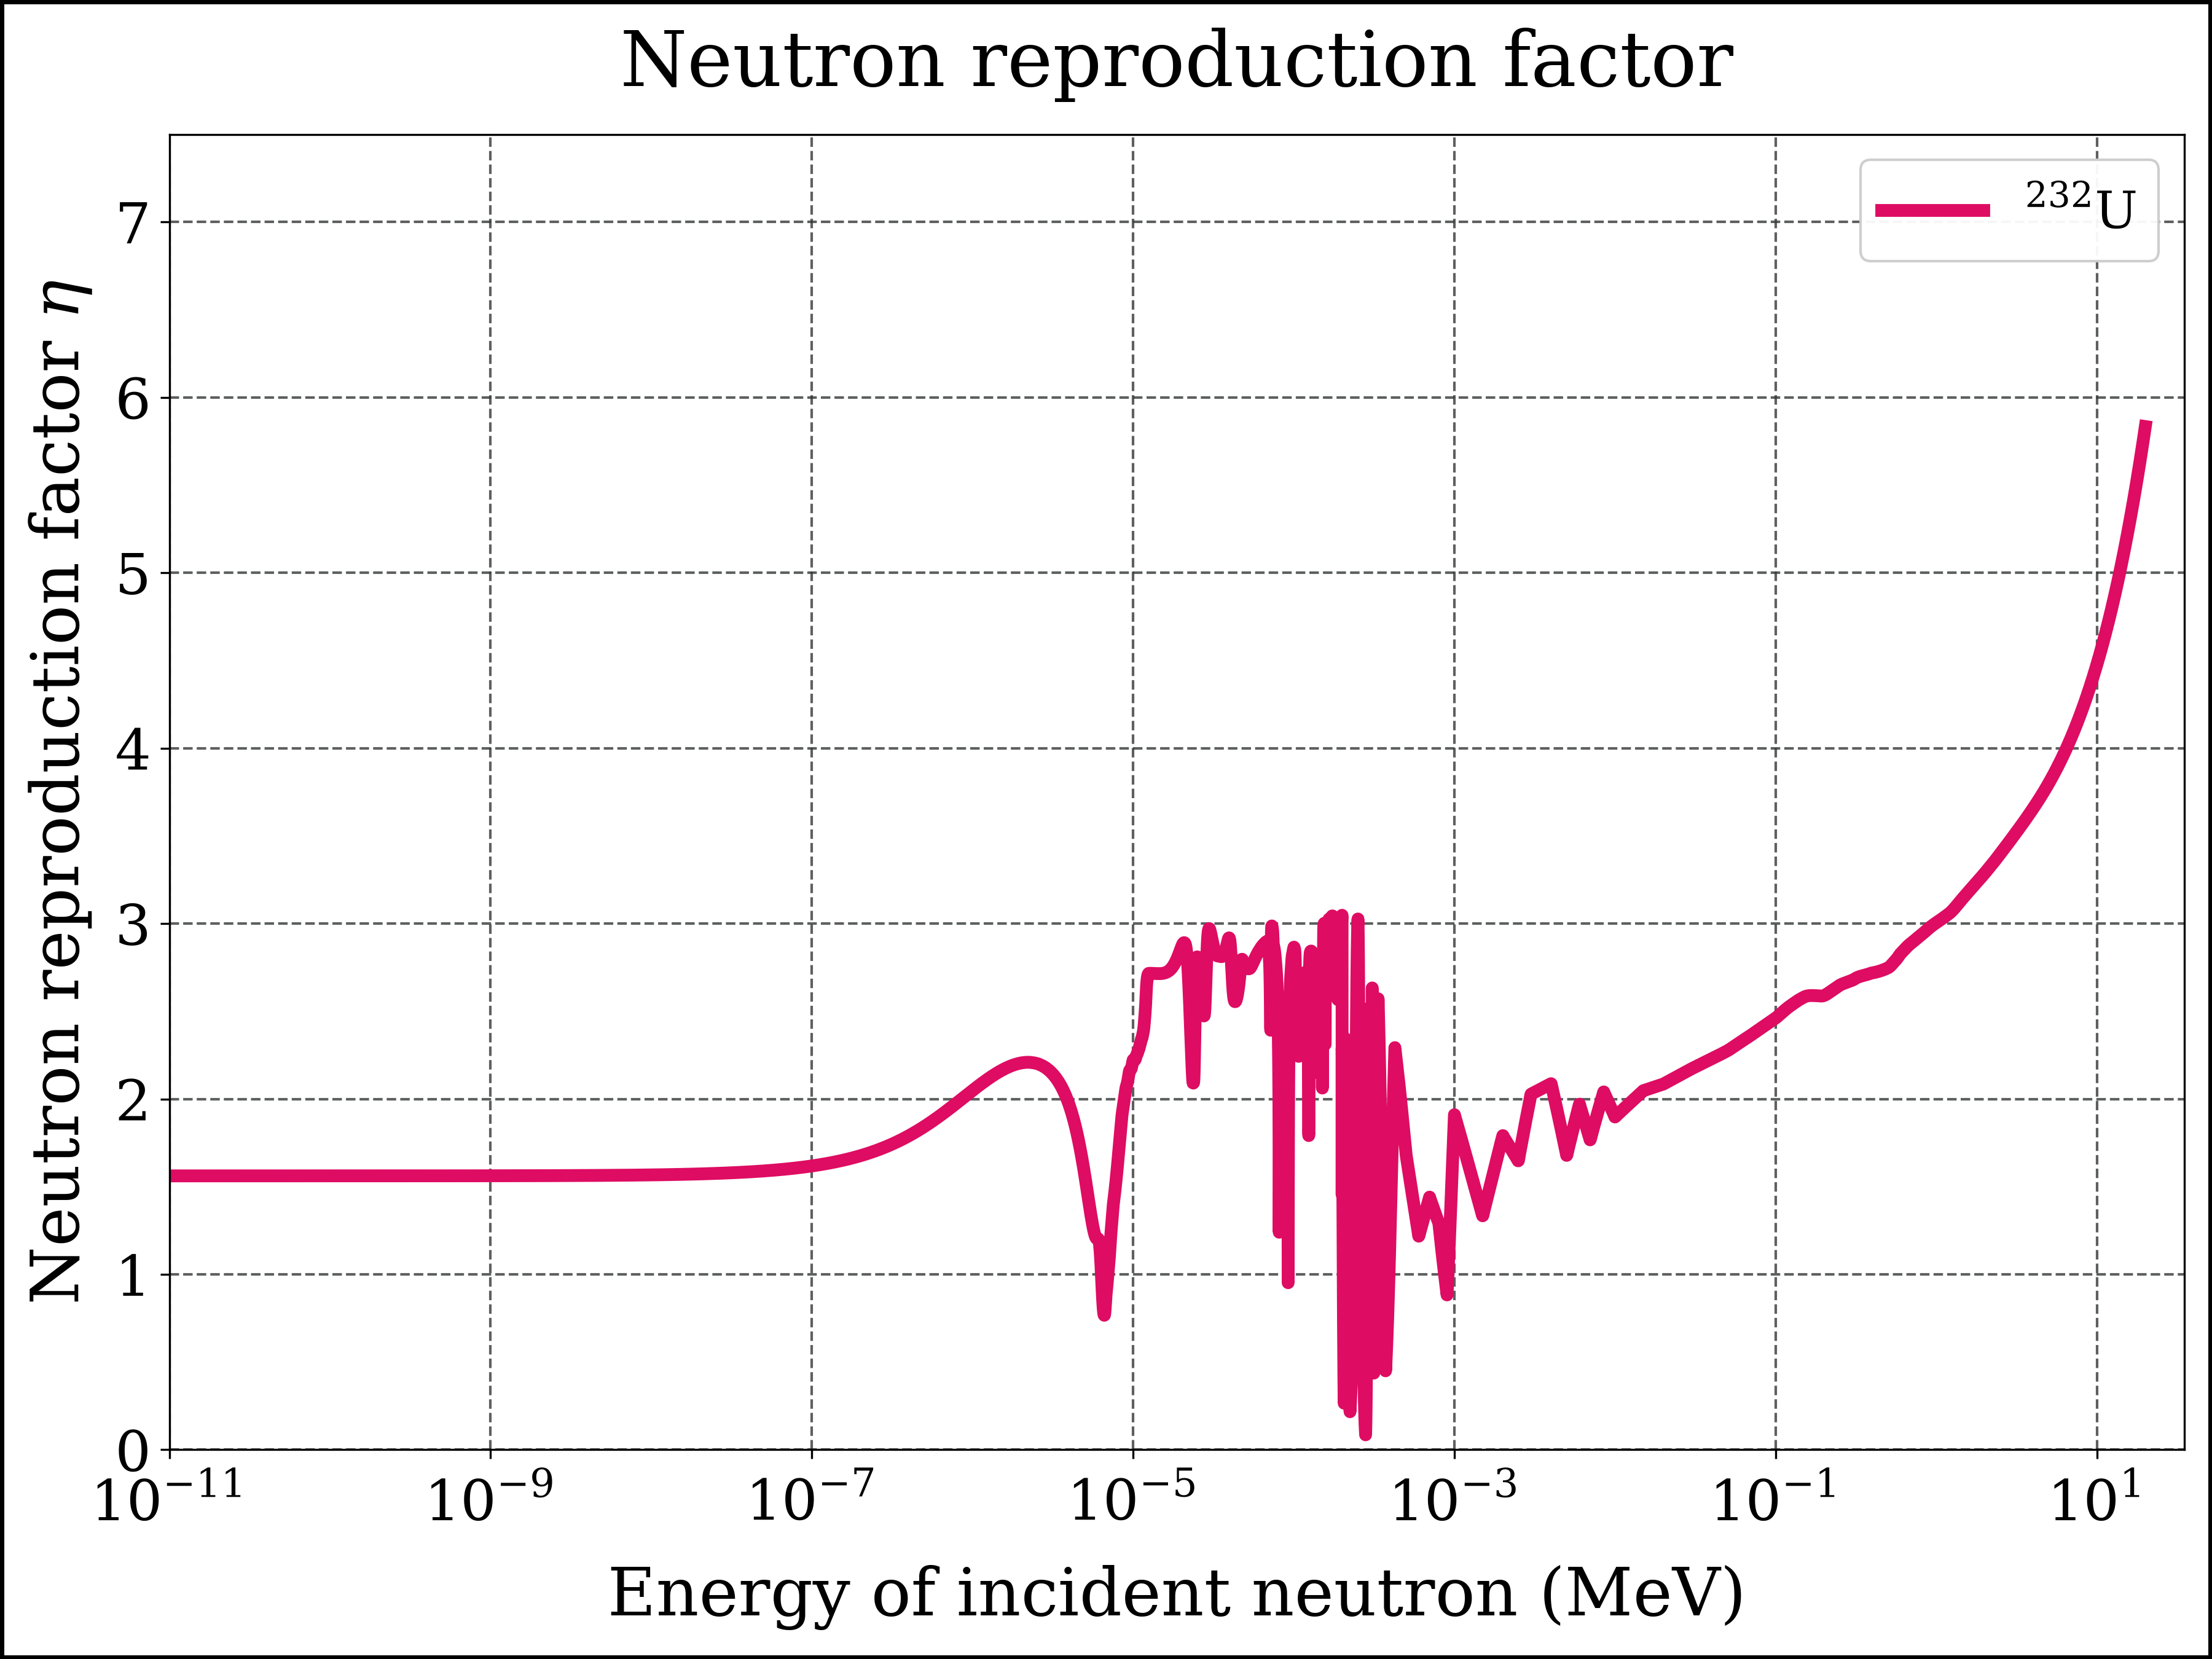

In [25]:
#| echo: true
#| label: fig-nrf-u232
#| fig-cap: 'Neutron reproduction factor for U-232'

fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
#
x = E_fine
y = nrf_u232(E_fine)
axes.plot(x, y, label=r'$\mathrm{^{232}U}$', color=color_u232,
          linestyle=ls1, linewidth=lw1, marker=None)
title        =  'Neutron reproduction factor'
ncol_legend  =  1
xlabel       =  'Energy of incident neutron (MeV)'
ylabel       =  r'Neutron reproduction factor $\eta$'
xlims        =  [1E-11, 35]
ylims        =  [0, 7.5]
xscale       =  'log'
yscale       =  'linear'
file_name    =  'nrf_u232_logE'
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

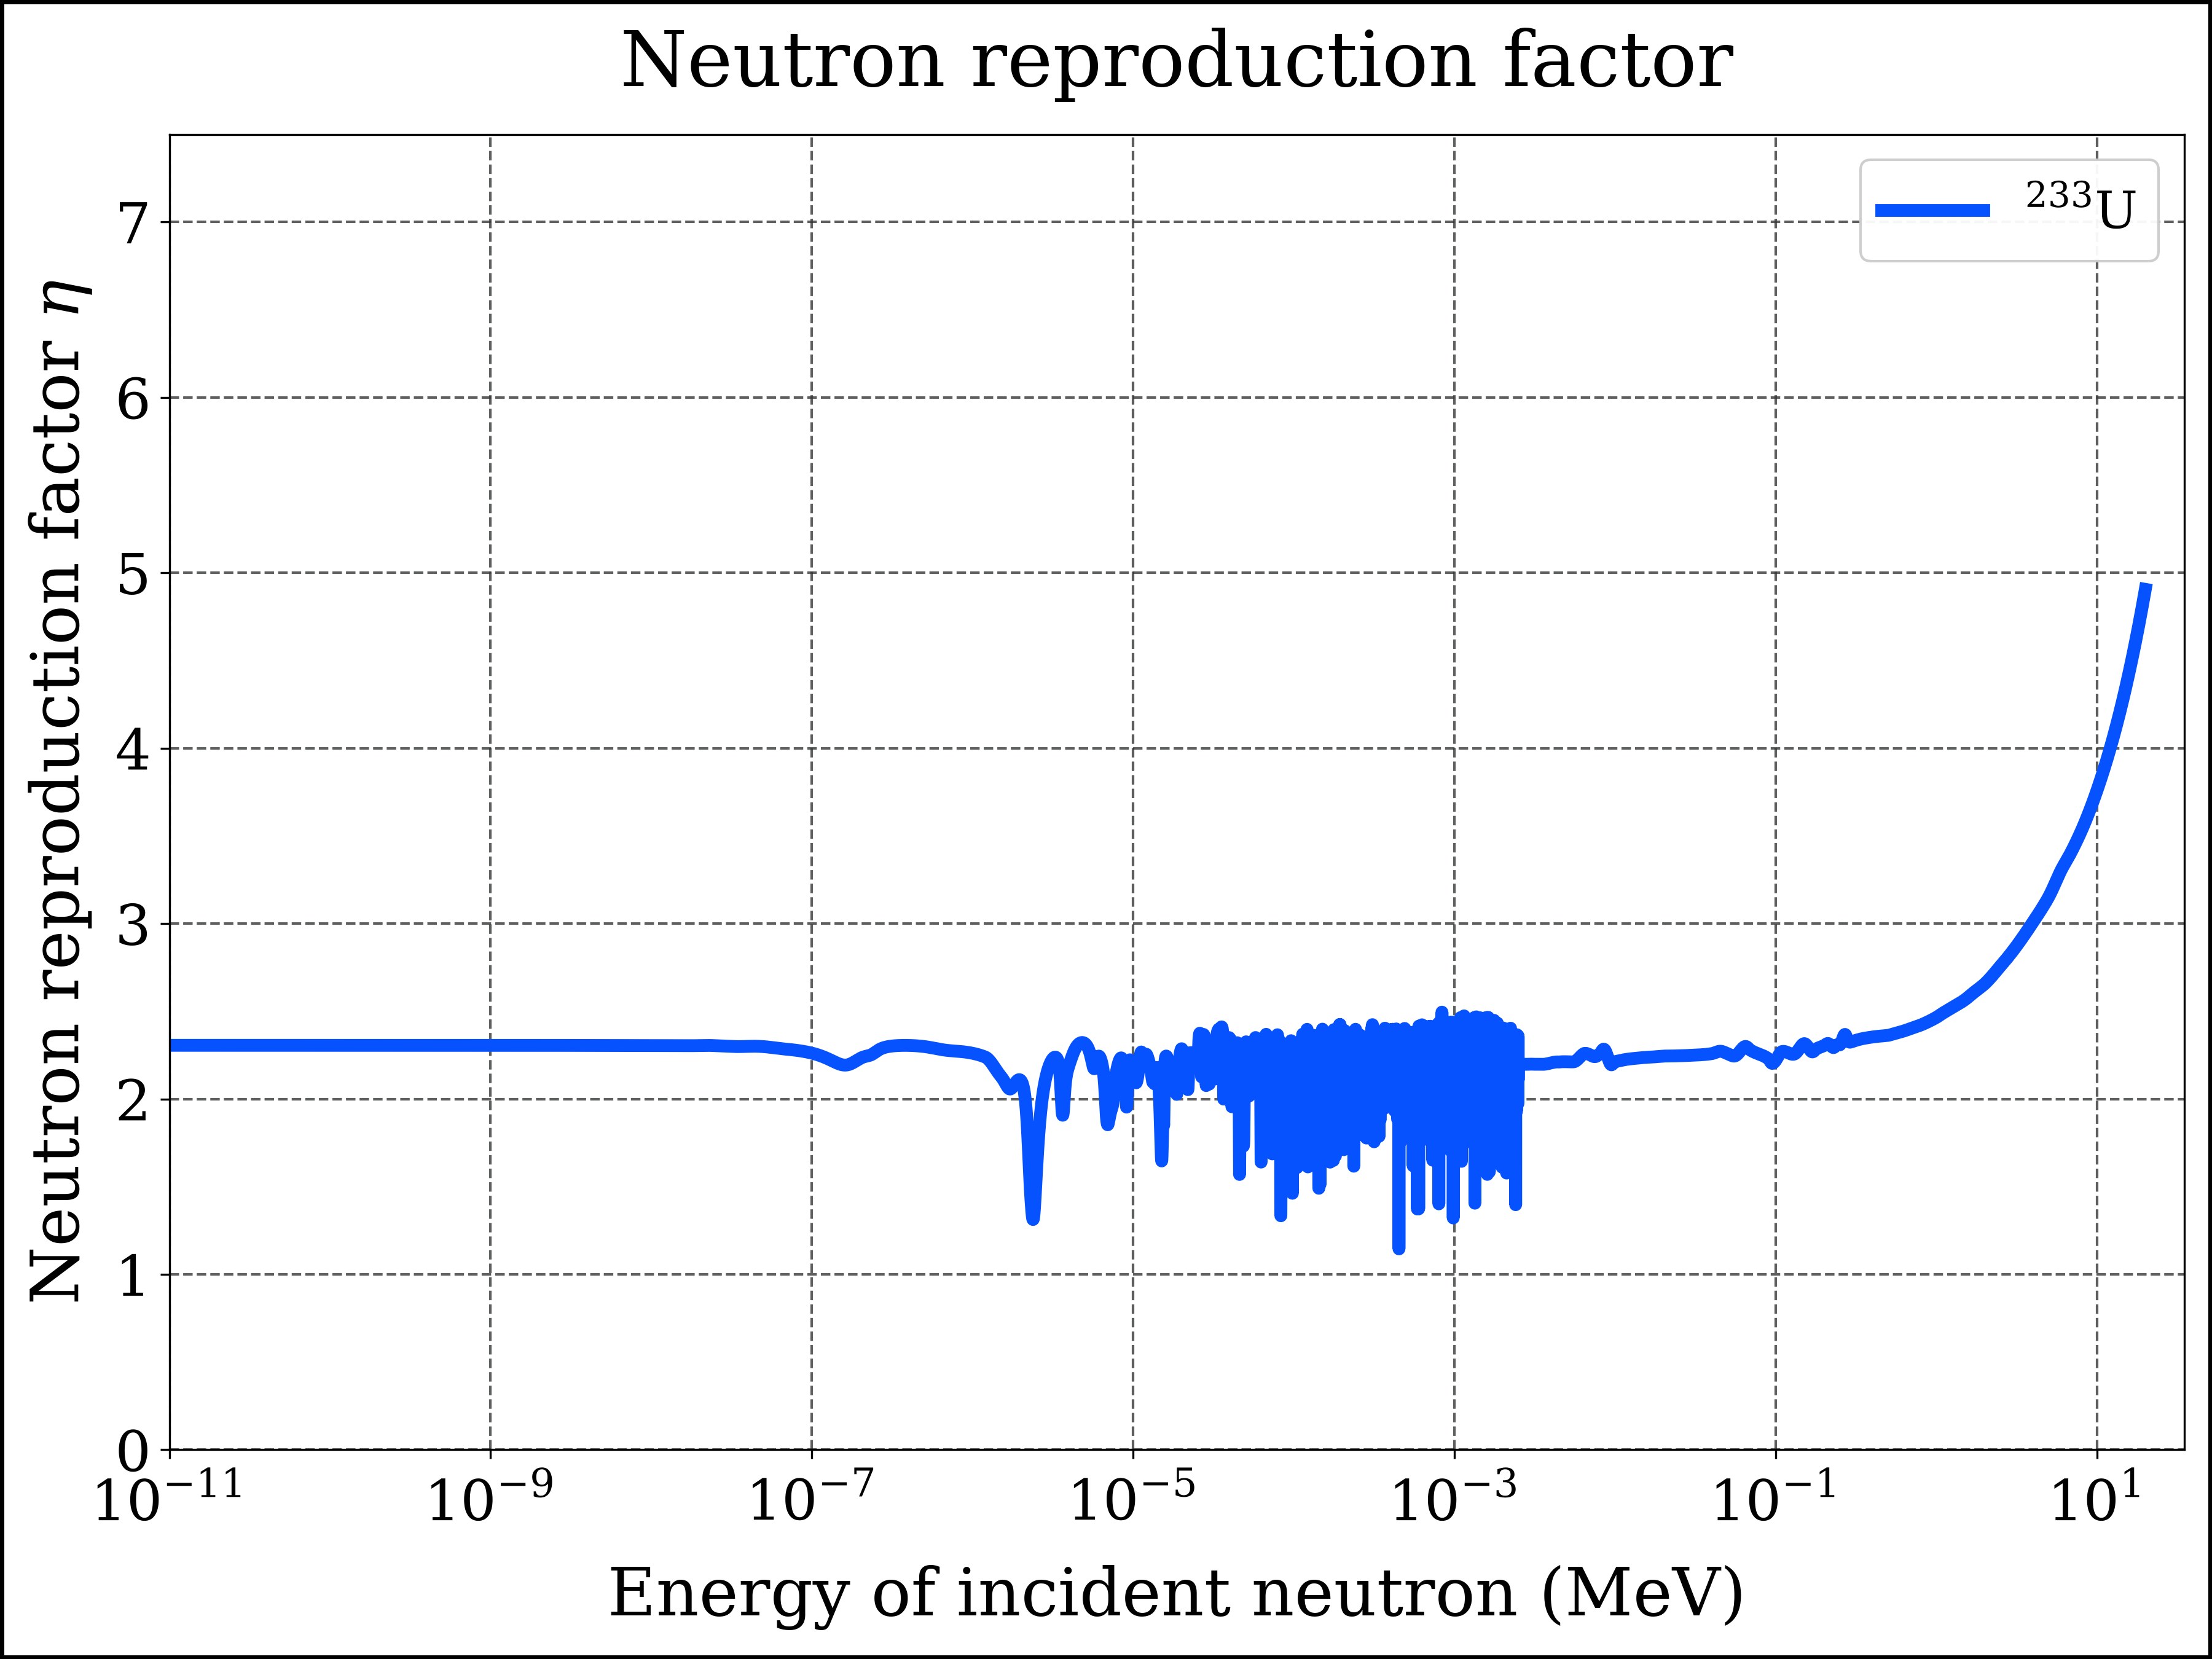

In [26]:
#| echo: true
#| label: fig-nrf-u233
#| fig-cap: 'Neutron reproduction factor for U-233'

x = E_fine
y = nrf_u233(E_fine)
fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
axes.plot(x, y, label=r'$\mathrm{^{233}U}$', color=color_u233, linestyle=ls1, linewidth=lw1, marker=None)
xlims      =  [1E-11, 35]
ylims      =  [0, 7.5]
xscale     =  'log'
yscale     =  'linear'
file_name  =  'nrf_u233_logE'
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

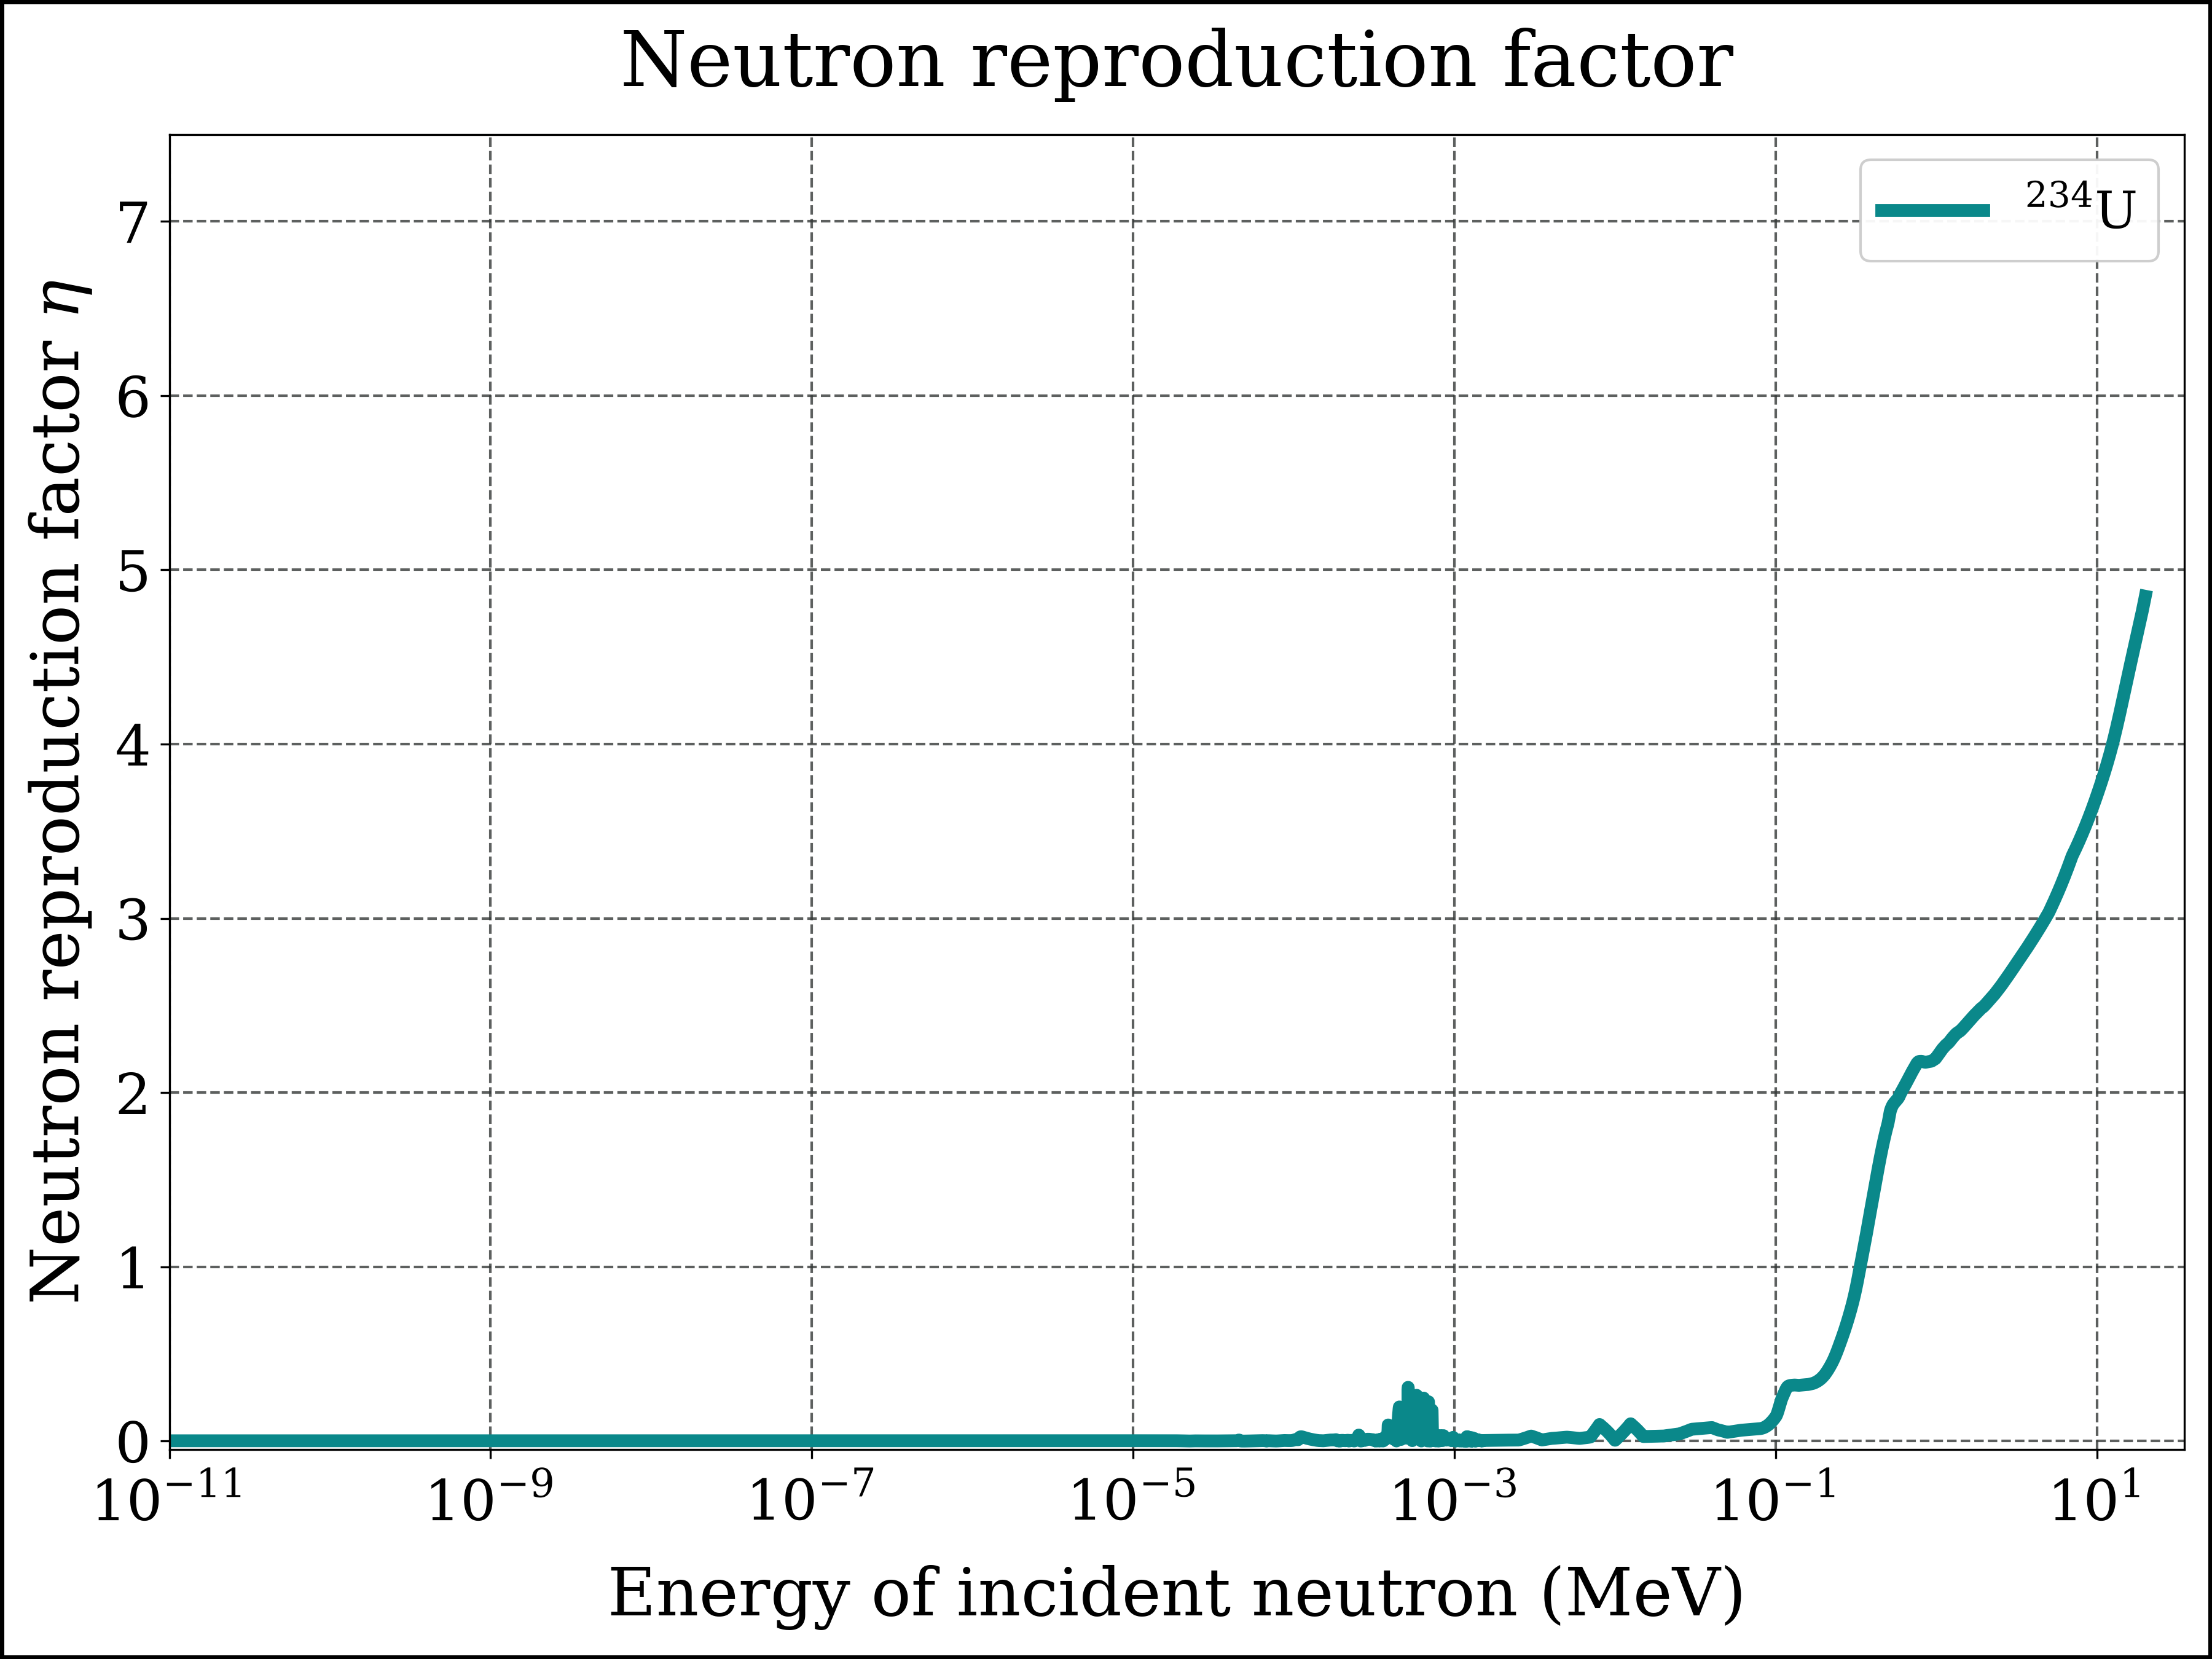

In [27]:
#| echo: true
#| label: fig-nrf-u234
#| fig-cap: 'Neutron reproduction factor for U-234'

x = E_fine
y = nrf_u234(E_fine)
fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
axes.plot(x, y, label=r'$\mathrm{^{234}U}$', color=color_u234, linestyle=ls1, linewidth=lw1, marker=None)
xlims      =  [1E-11, 35]
ylims      =  [-0.05, 7.5]
xscale     =  'log'
yscale     =  'linear'
file_name  =  'nrf_u234_logE'
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

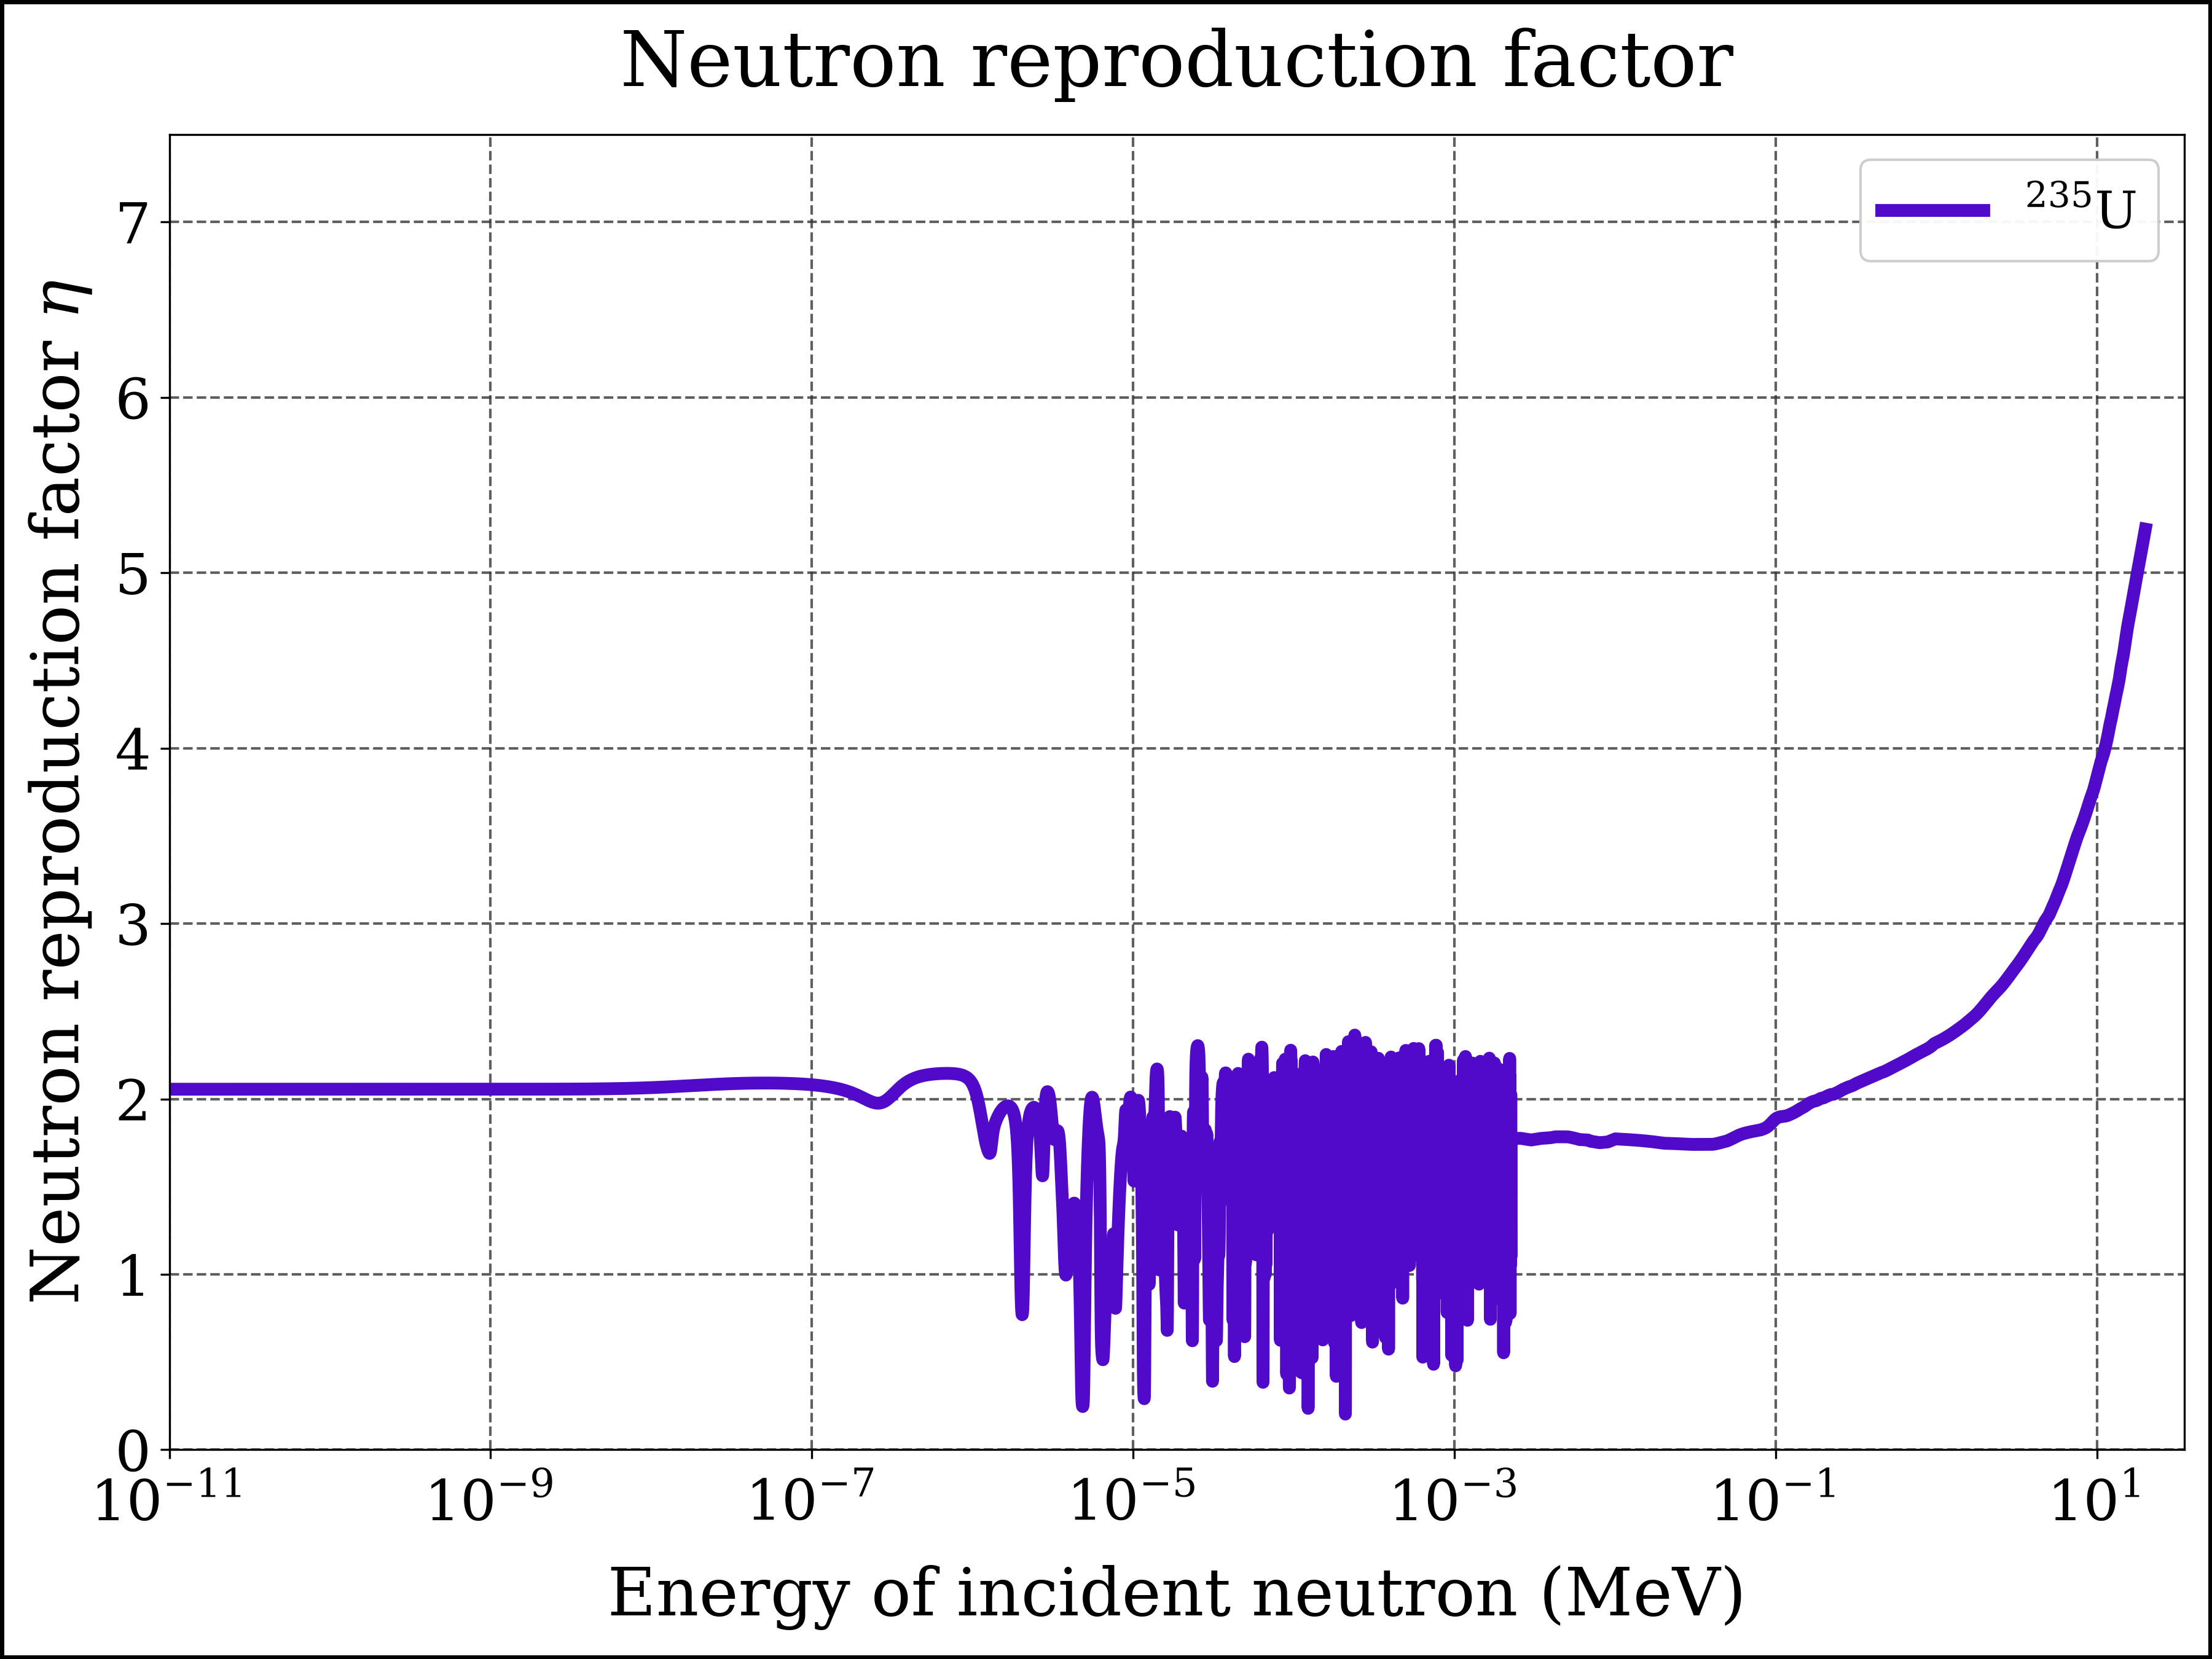

In [28]:
#| echo: true
#| label: fig-nrf-u235
#| fig-cap: 'Neutron reproduction factor for U-235'

x = E_fine
y = nrf_u235(E_fine)
fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
axes.plot(x, y, label=r'$\mathrm{^{235}U}$',
          color=color_u235, linestyle=ls1, linewidth=lw1, marker=None)
#
xlims      =  [1E-11, 35]
ylims      =  [0, 7.5]
xscale     =  'log'
yscale     =  'linear'
file_name  =  'nrf_u235_logE'
#
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

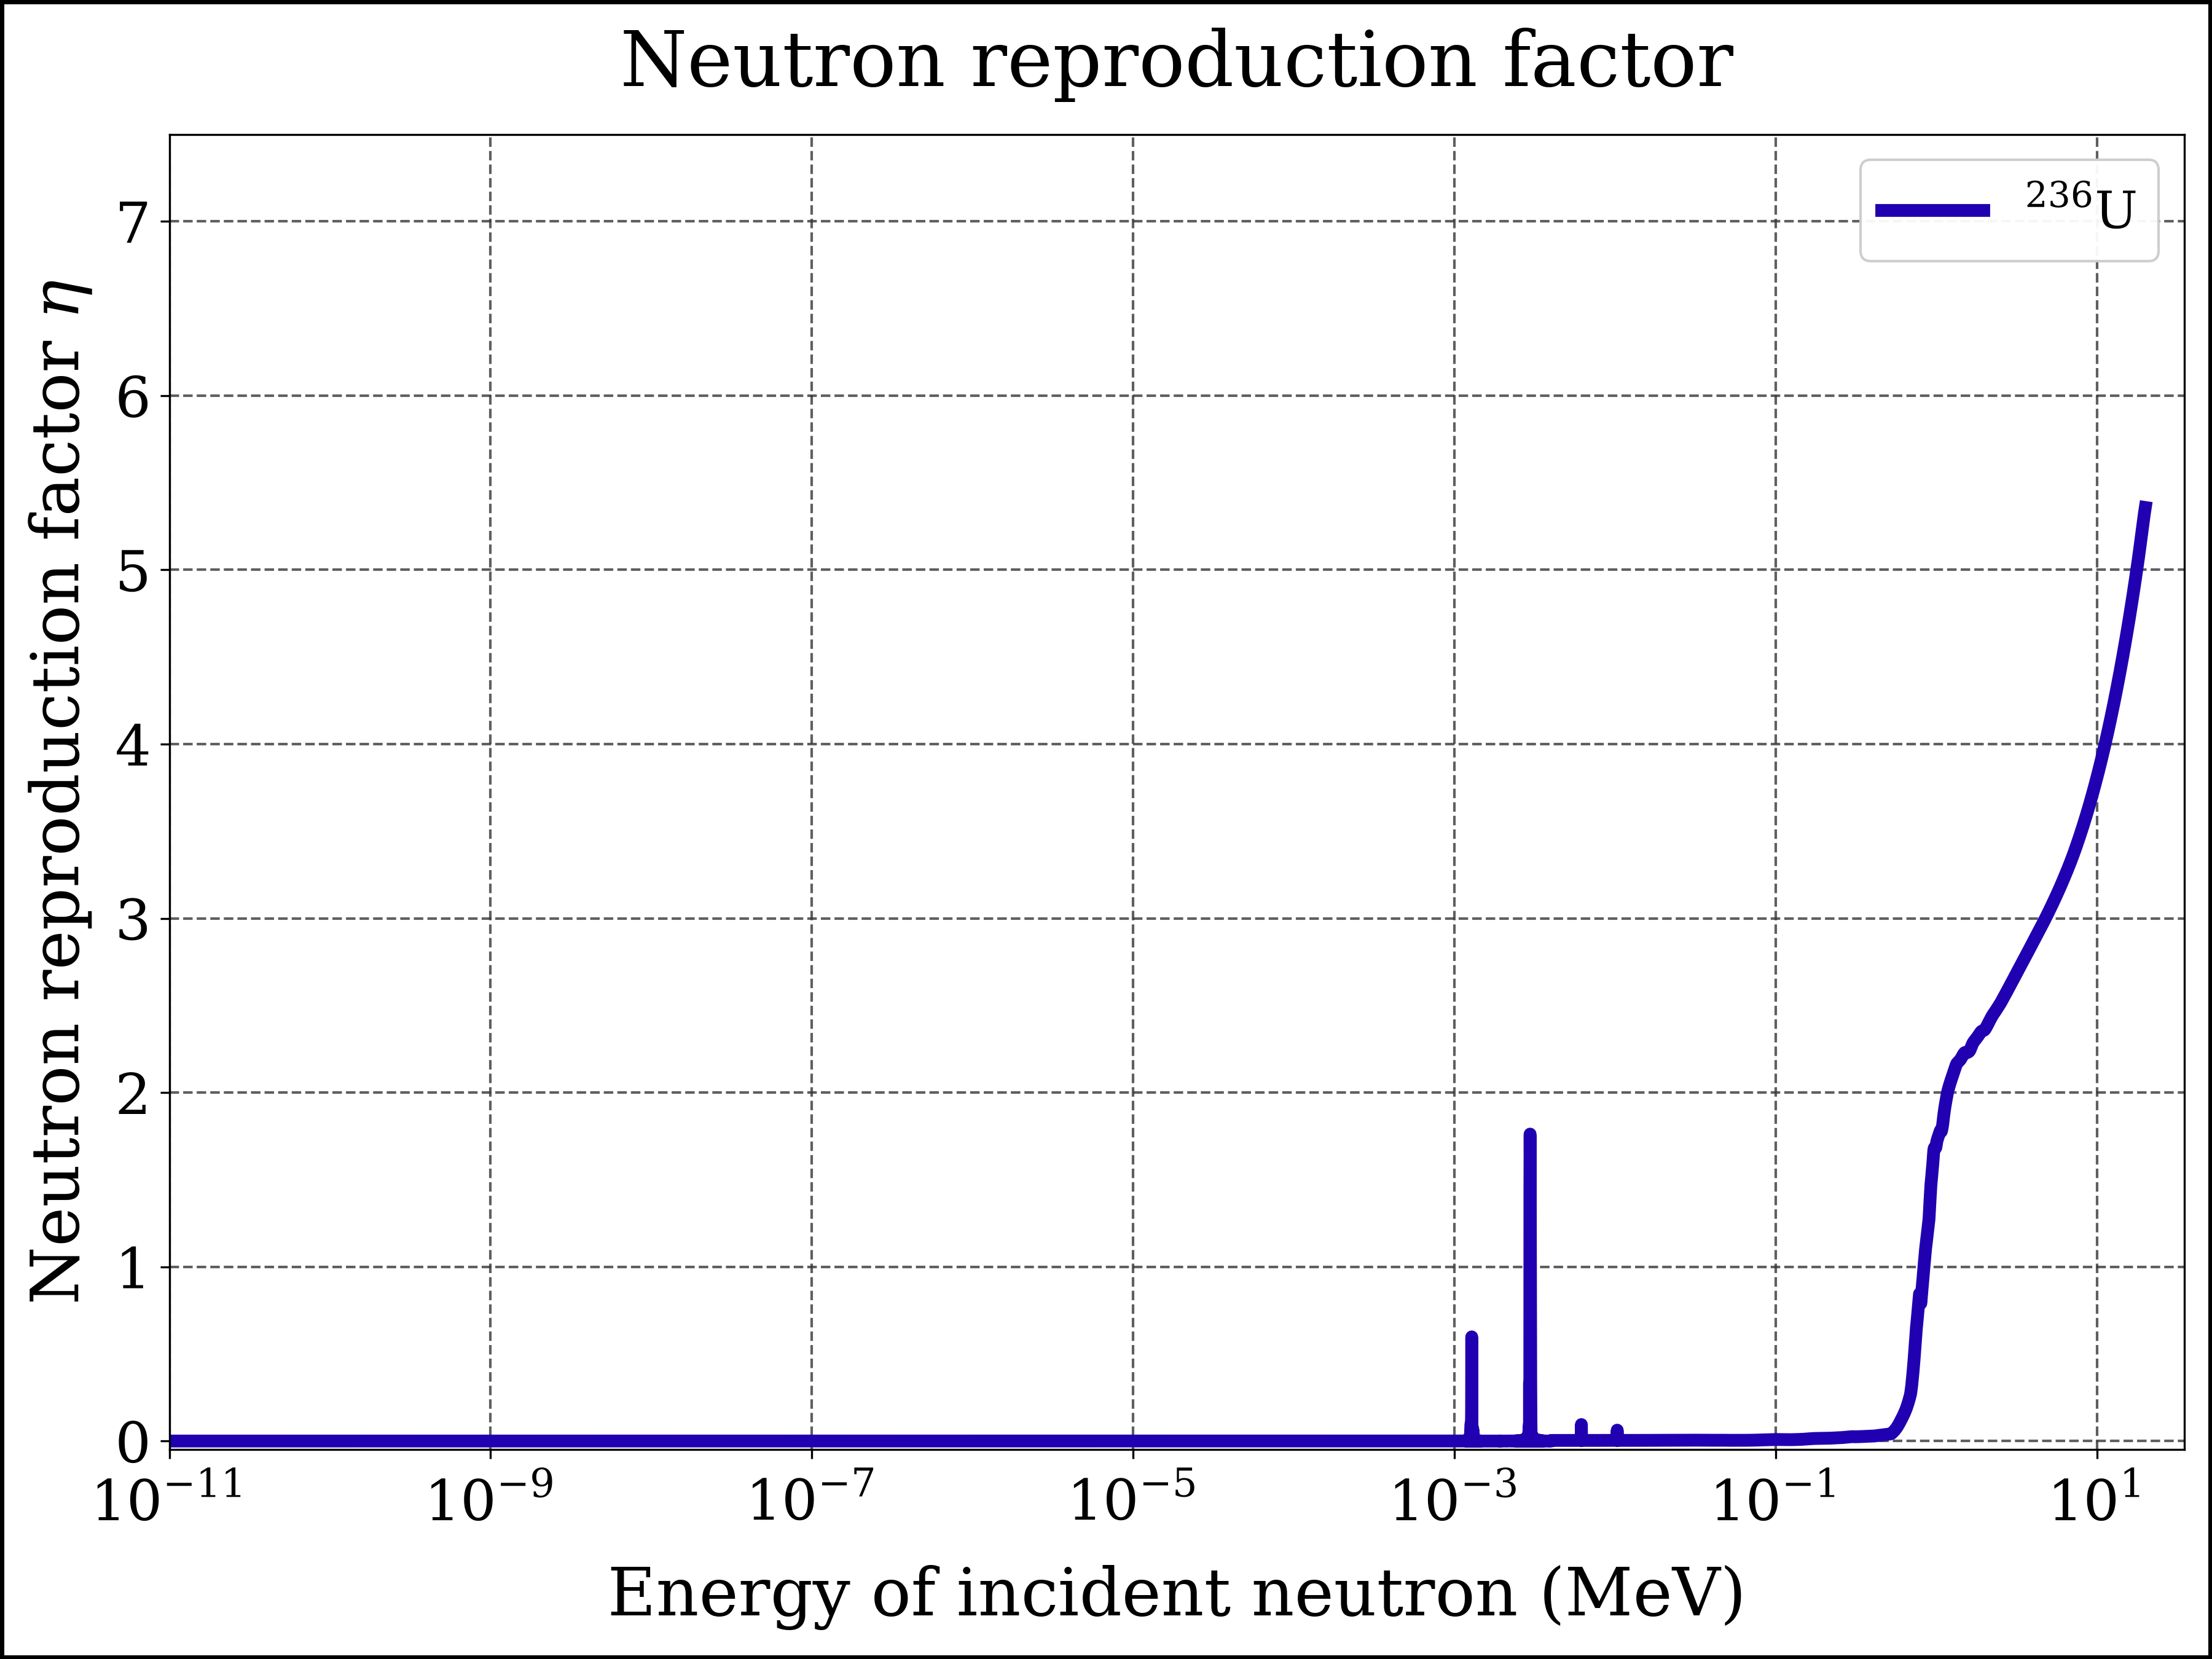

In [29]:
#| echo: true
#| label: fig-nrf-u236
#| fig-cap: 'Neutron reproduction factor for U-236'

x = E_fine
y = nrf_u236(E_fine)
fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
axes.plot(x, y, label=r'$\mathrm{^{236}U}$',
          color=color_u236, linestyle=ls1, linewidth=lw1, marker=None)
#
xlims      =  [1E-11, 35]
ylims      =  [-0.05, 7.5]
xscale     =  'log'
yscale     =  'linear'
file_name  =  'nrf_u236_logE'
#
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

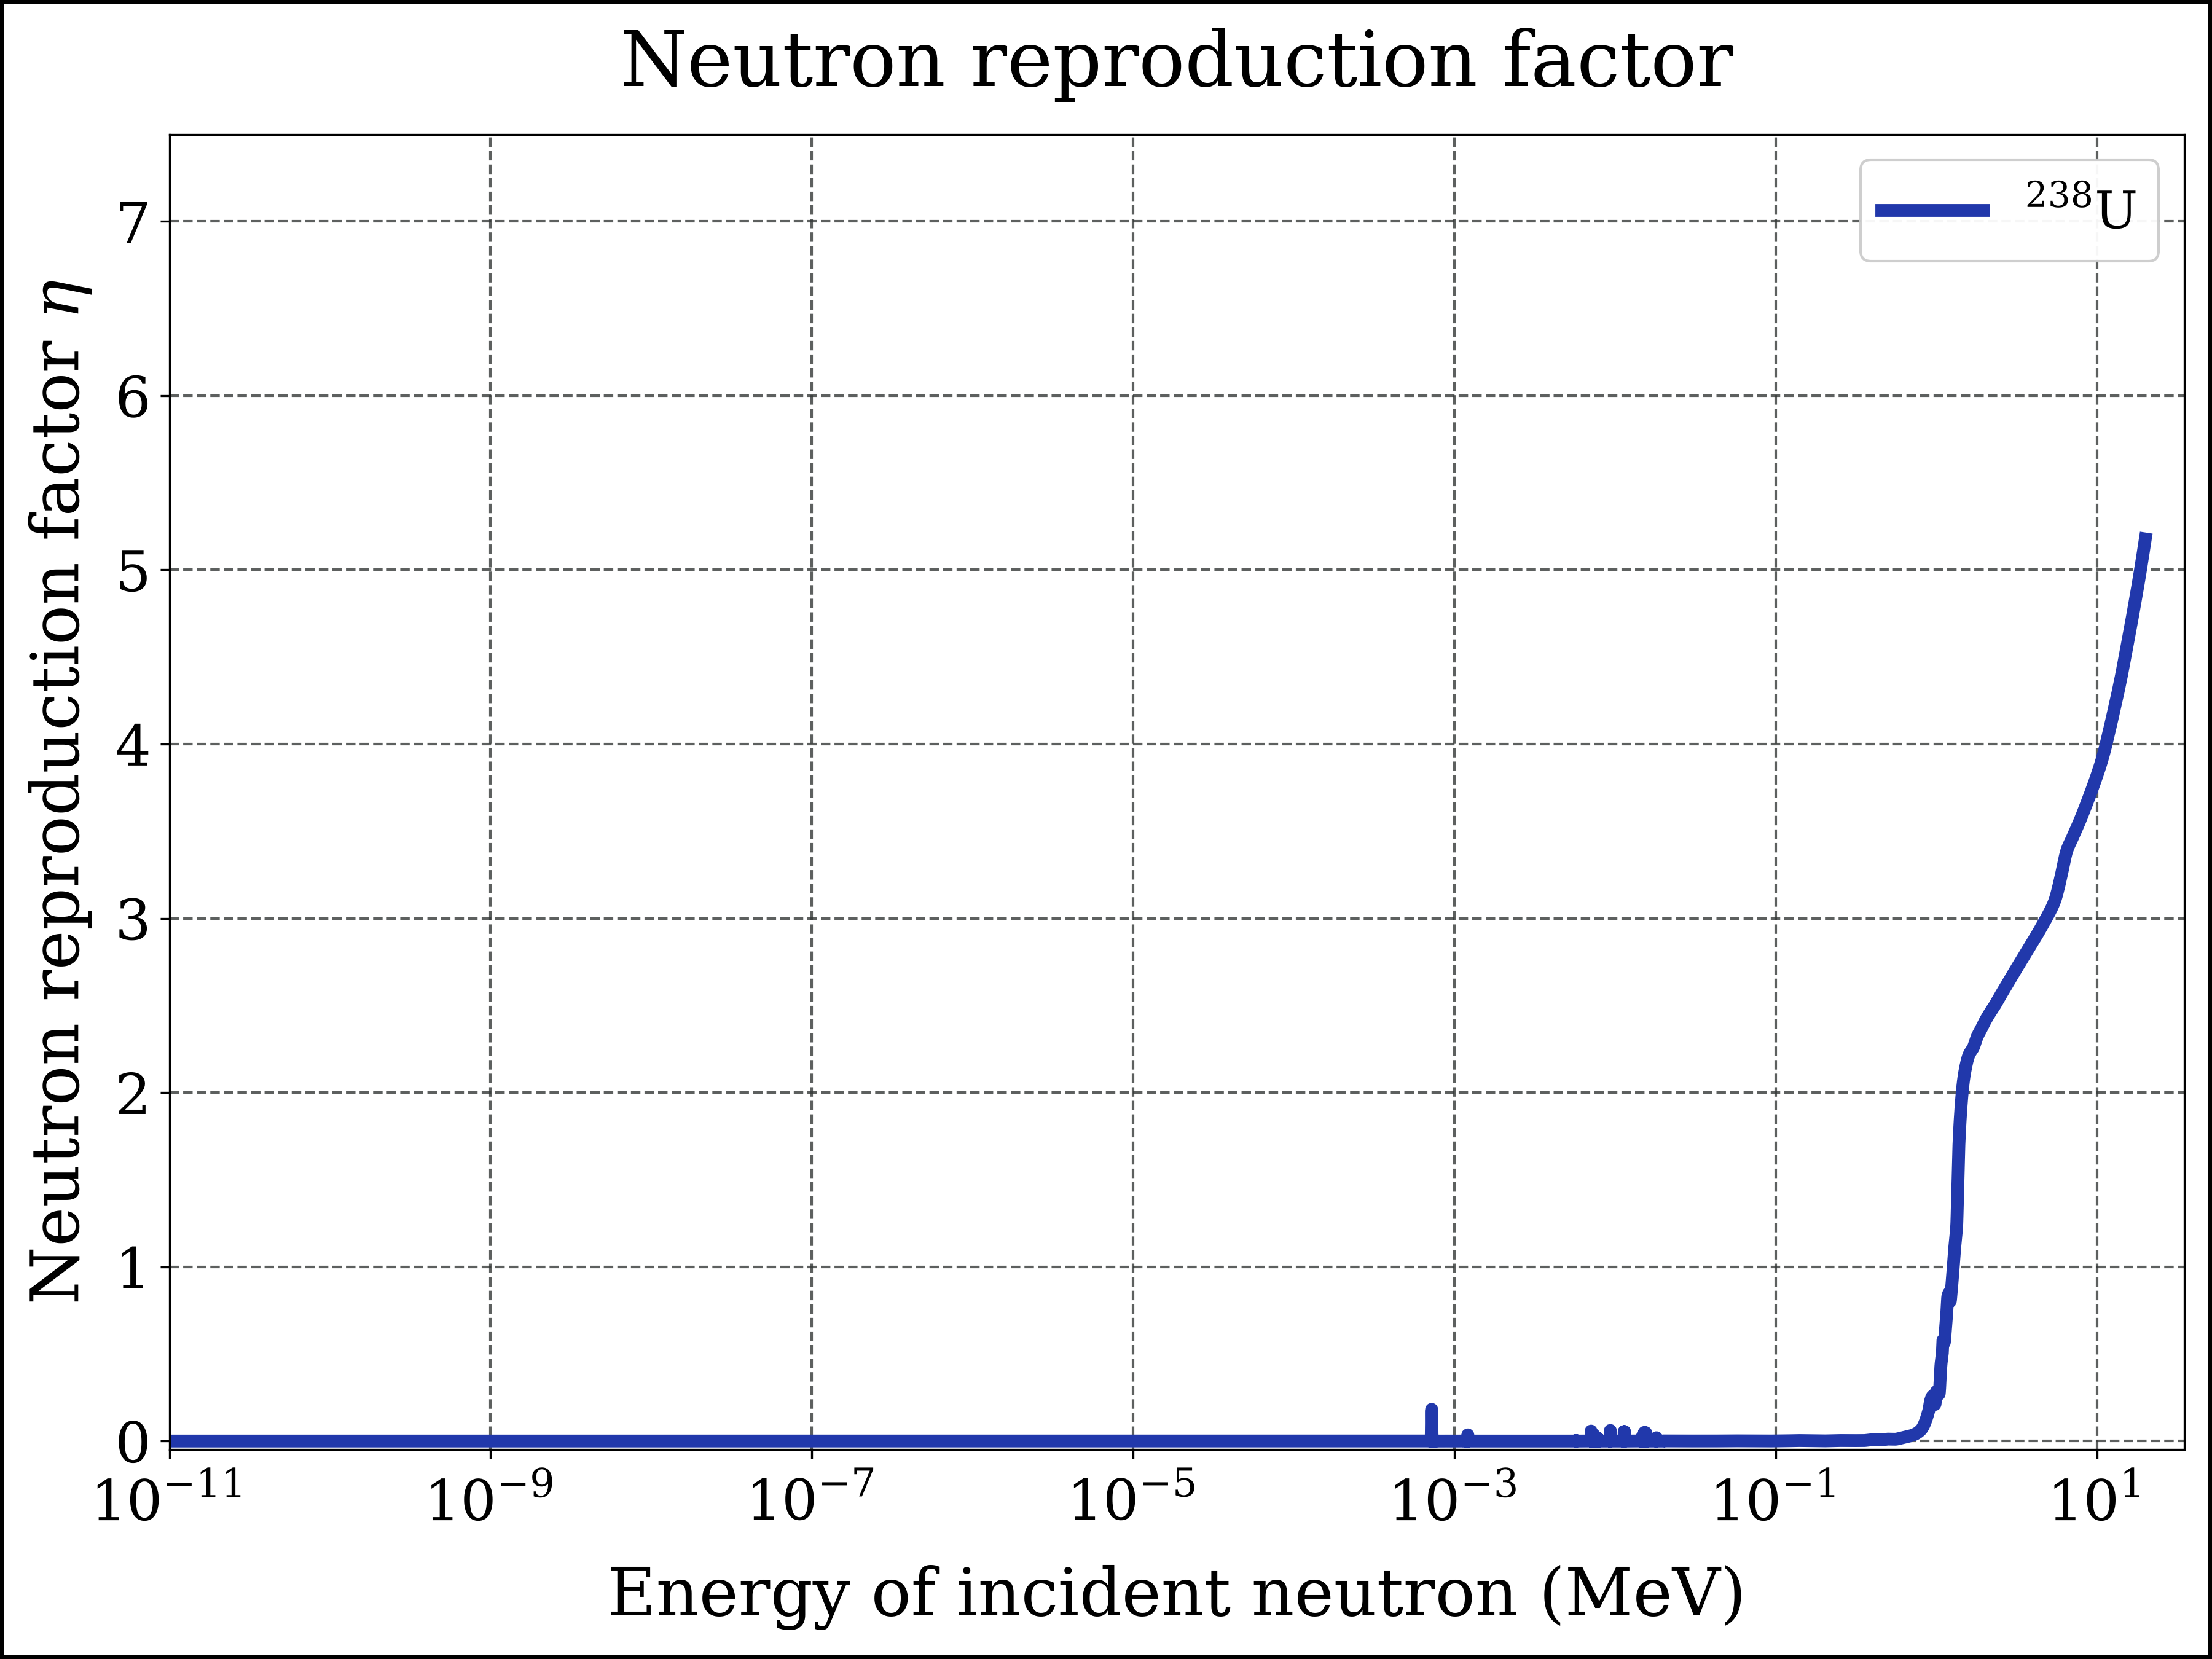

In [30]:
#| echo: true
#| label: fig-nrf-u238
#| fig-cap: 'Neutron reproduction factor for U-238'

x = E_fine
y = nrf_u238(E_fine)
fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
axes.plot(x, y, label=r'$\mathrm{^{238}U}$',
          color=color_u238, linestyle=ls1, linewidth=lw1, marker=None)
#
xlims      =  [1E-11, 35]
ylims      =  [-0.05, 7.5]
file_name  =  'nrf_u238_logE'
#
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

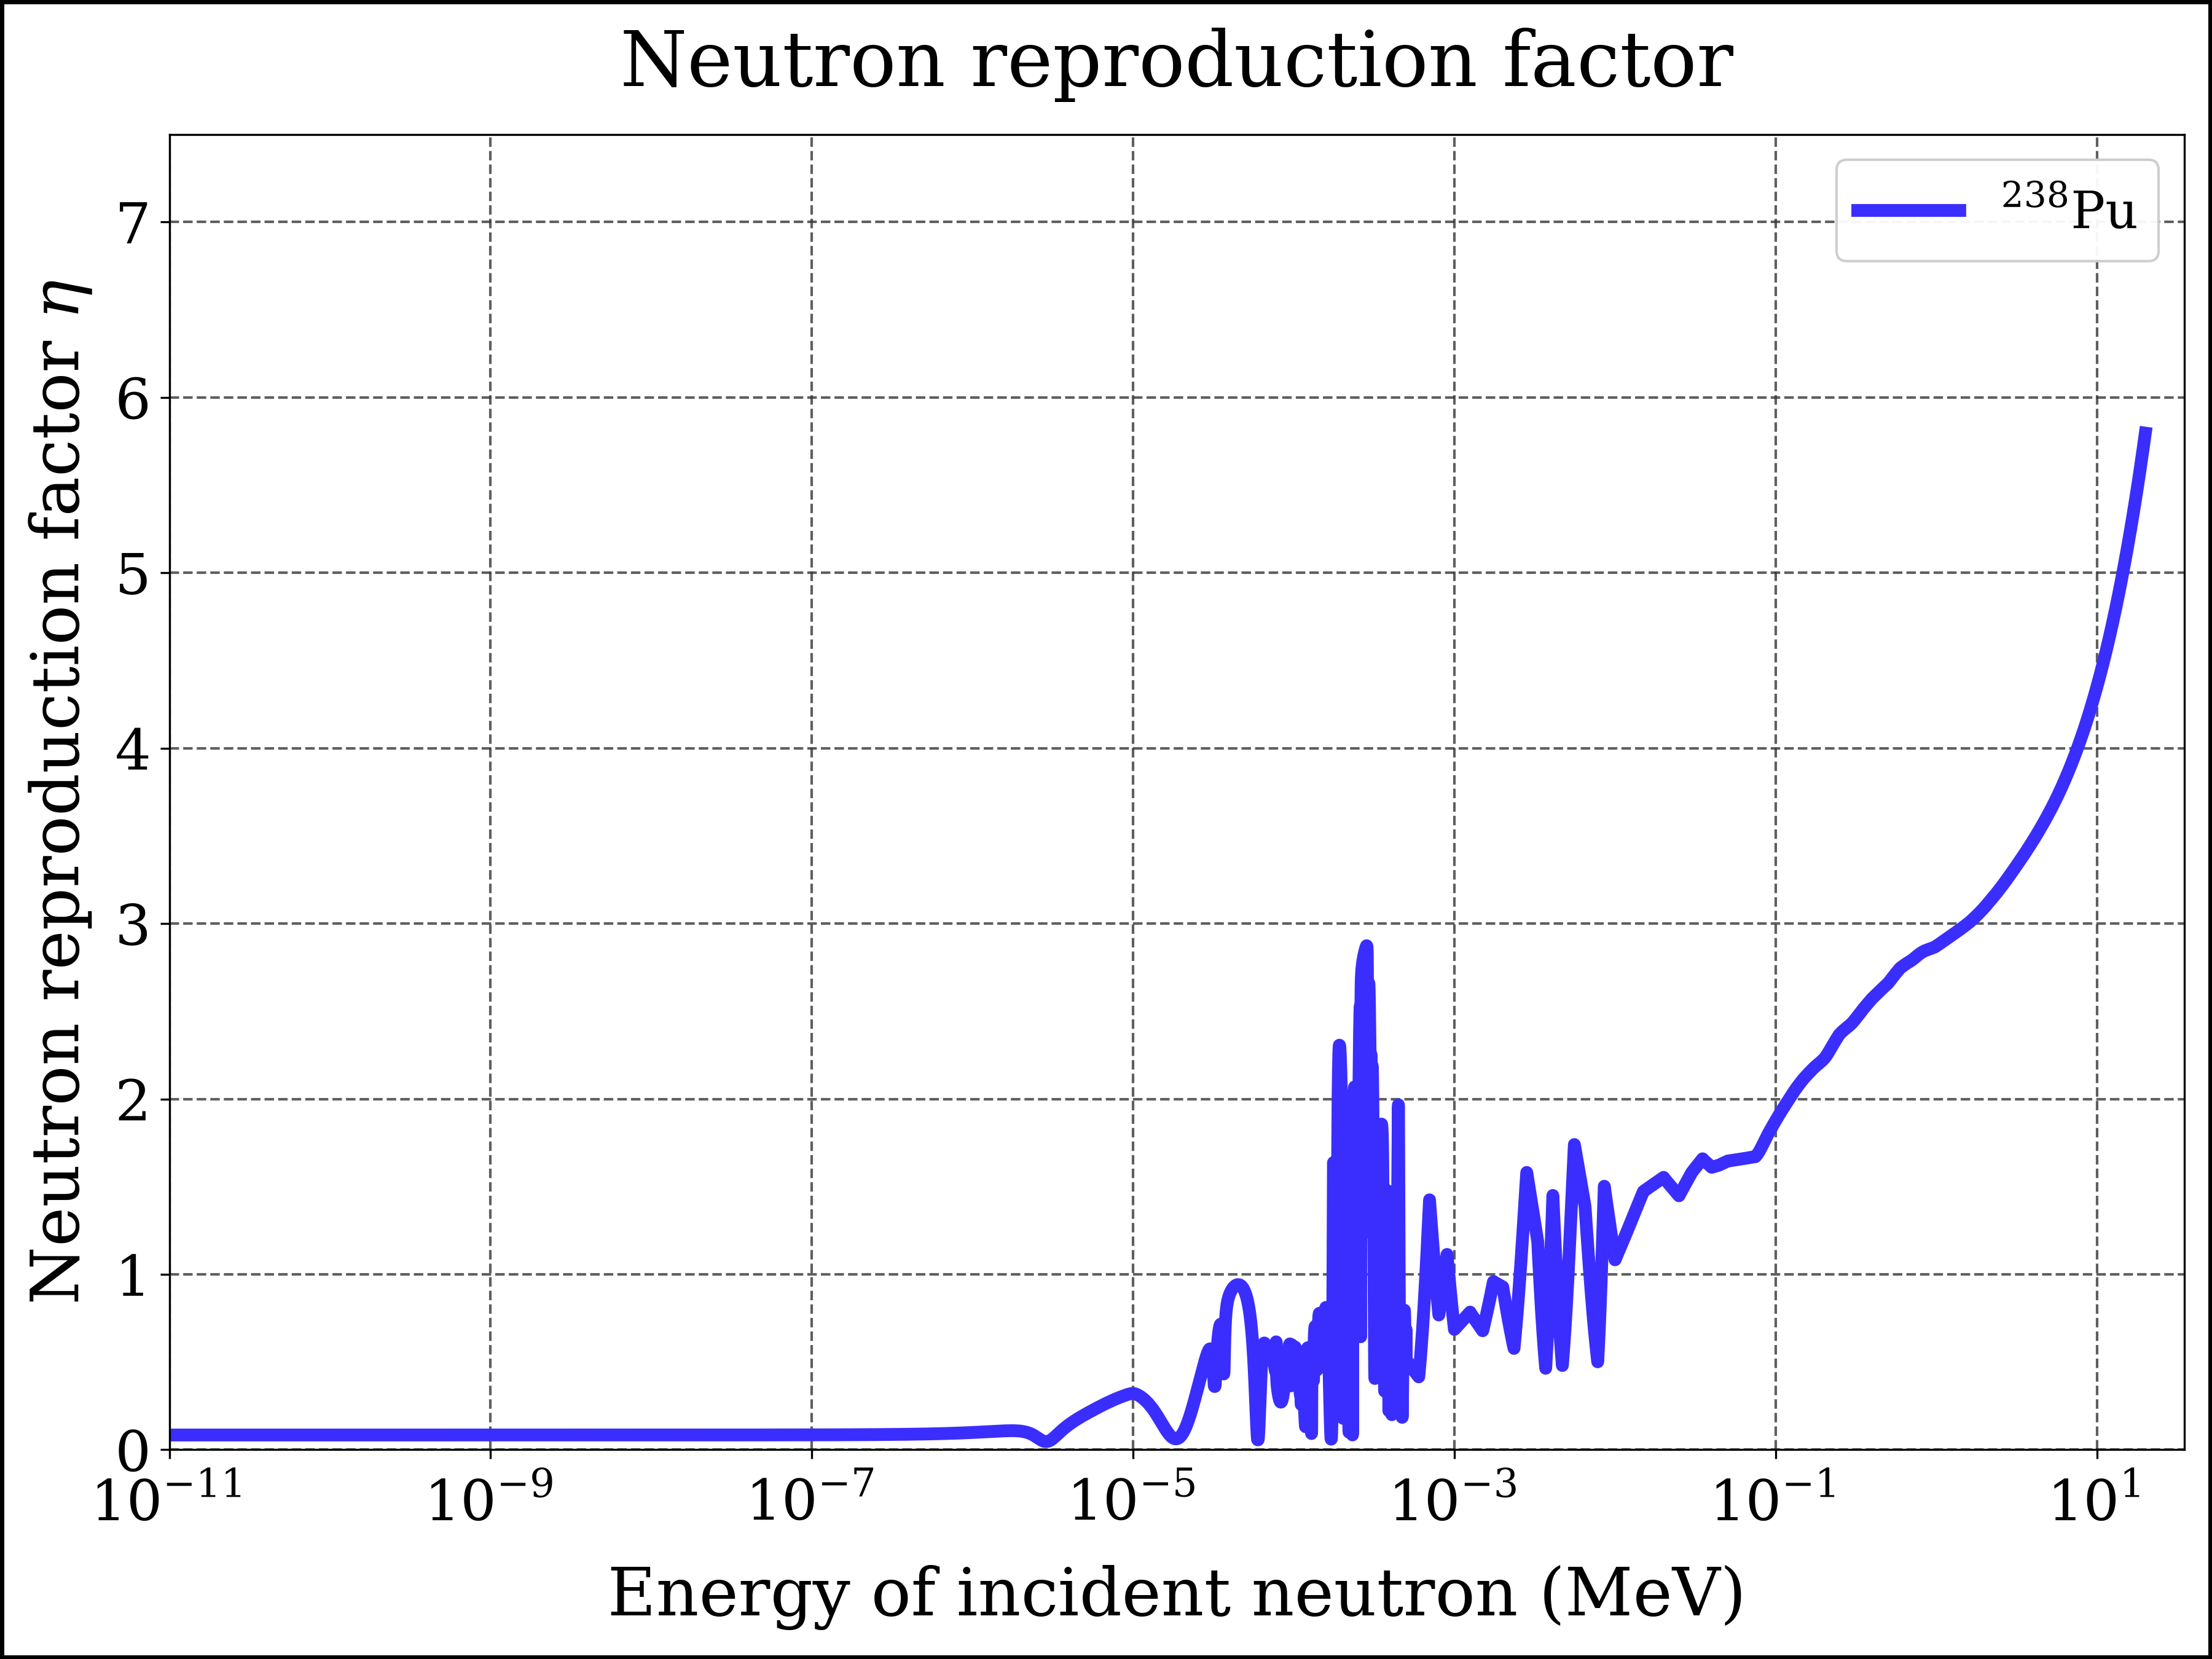

In [31]:
#| echo: true
#| label: fig-nrf-pu238
#| fig-cap: 'Neutron reproduction factor for Pu-238'

x = E_fine
y = nrf_pu238(E_fine)
fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
axes.plot(x, y, label=r'$\mathrm{^{238}Pu}$',
          color=color_pu238, linestyle=ls1, linewidth=lw1, marker=None)
#
xlims      =  [1E-11, 35]
ylims      =  [0, 7.5]
file_name  =  'nrf_pu238_logE'
#
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

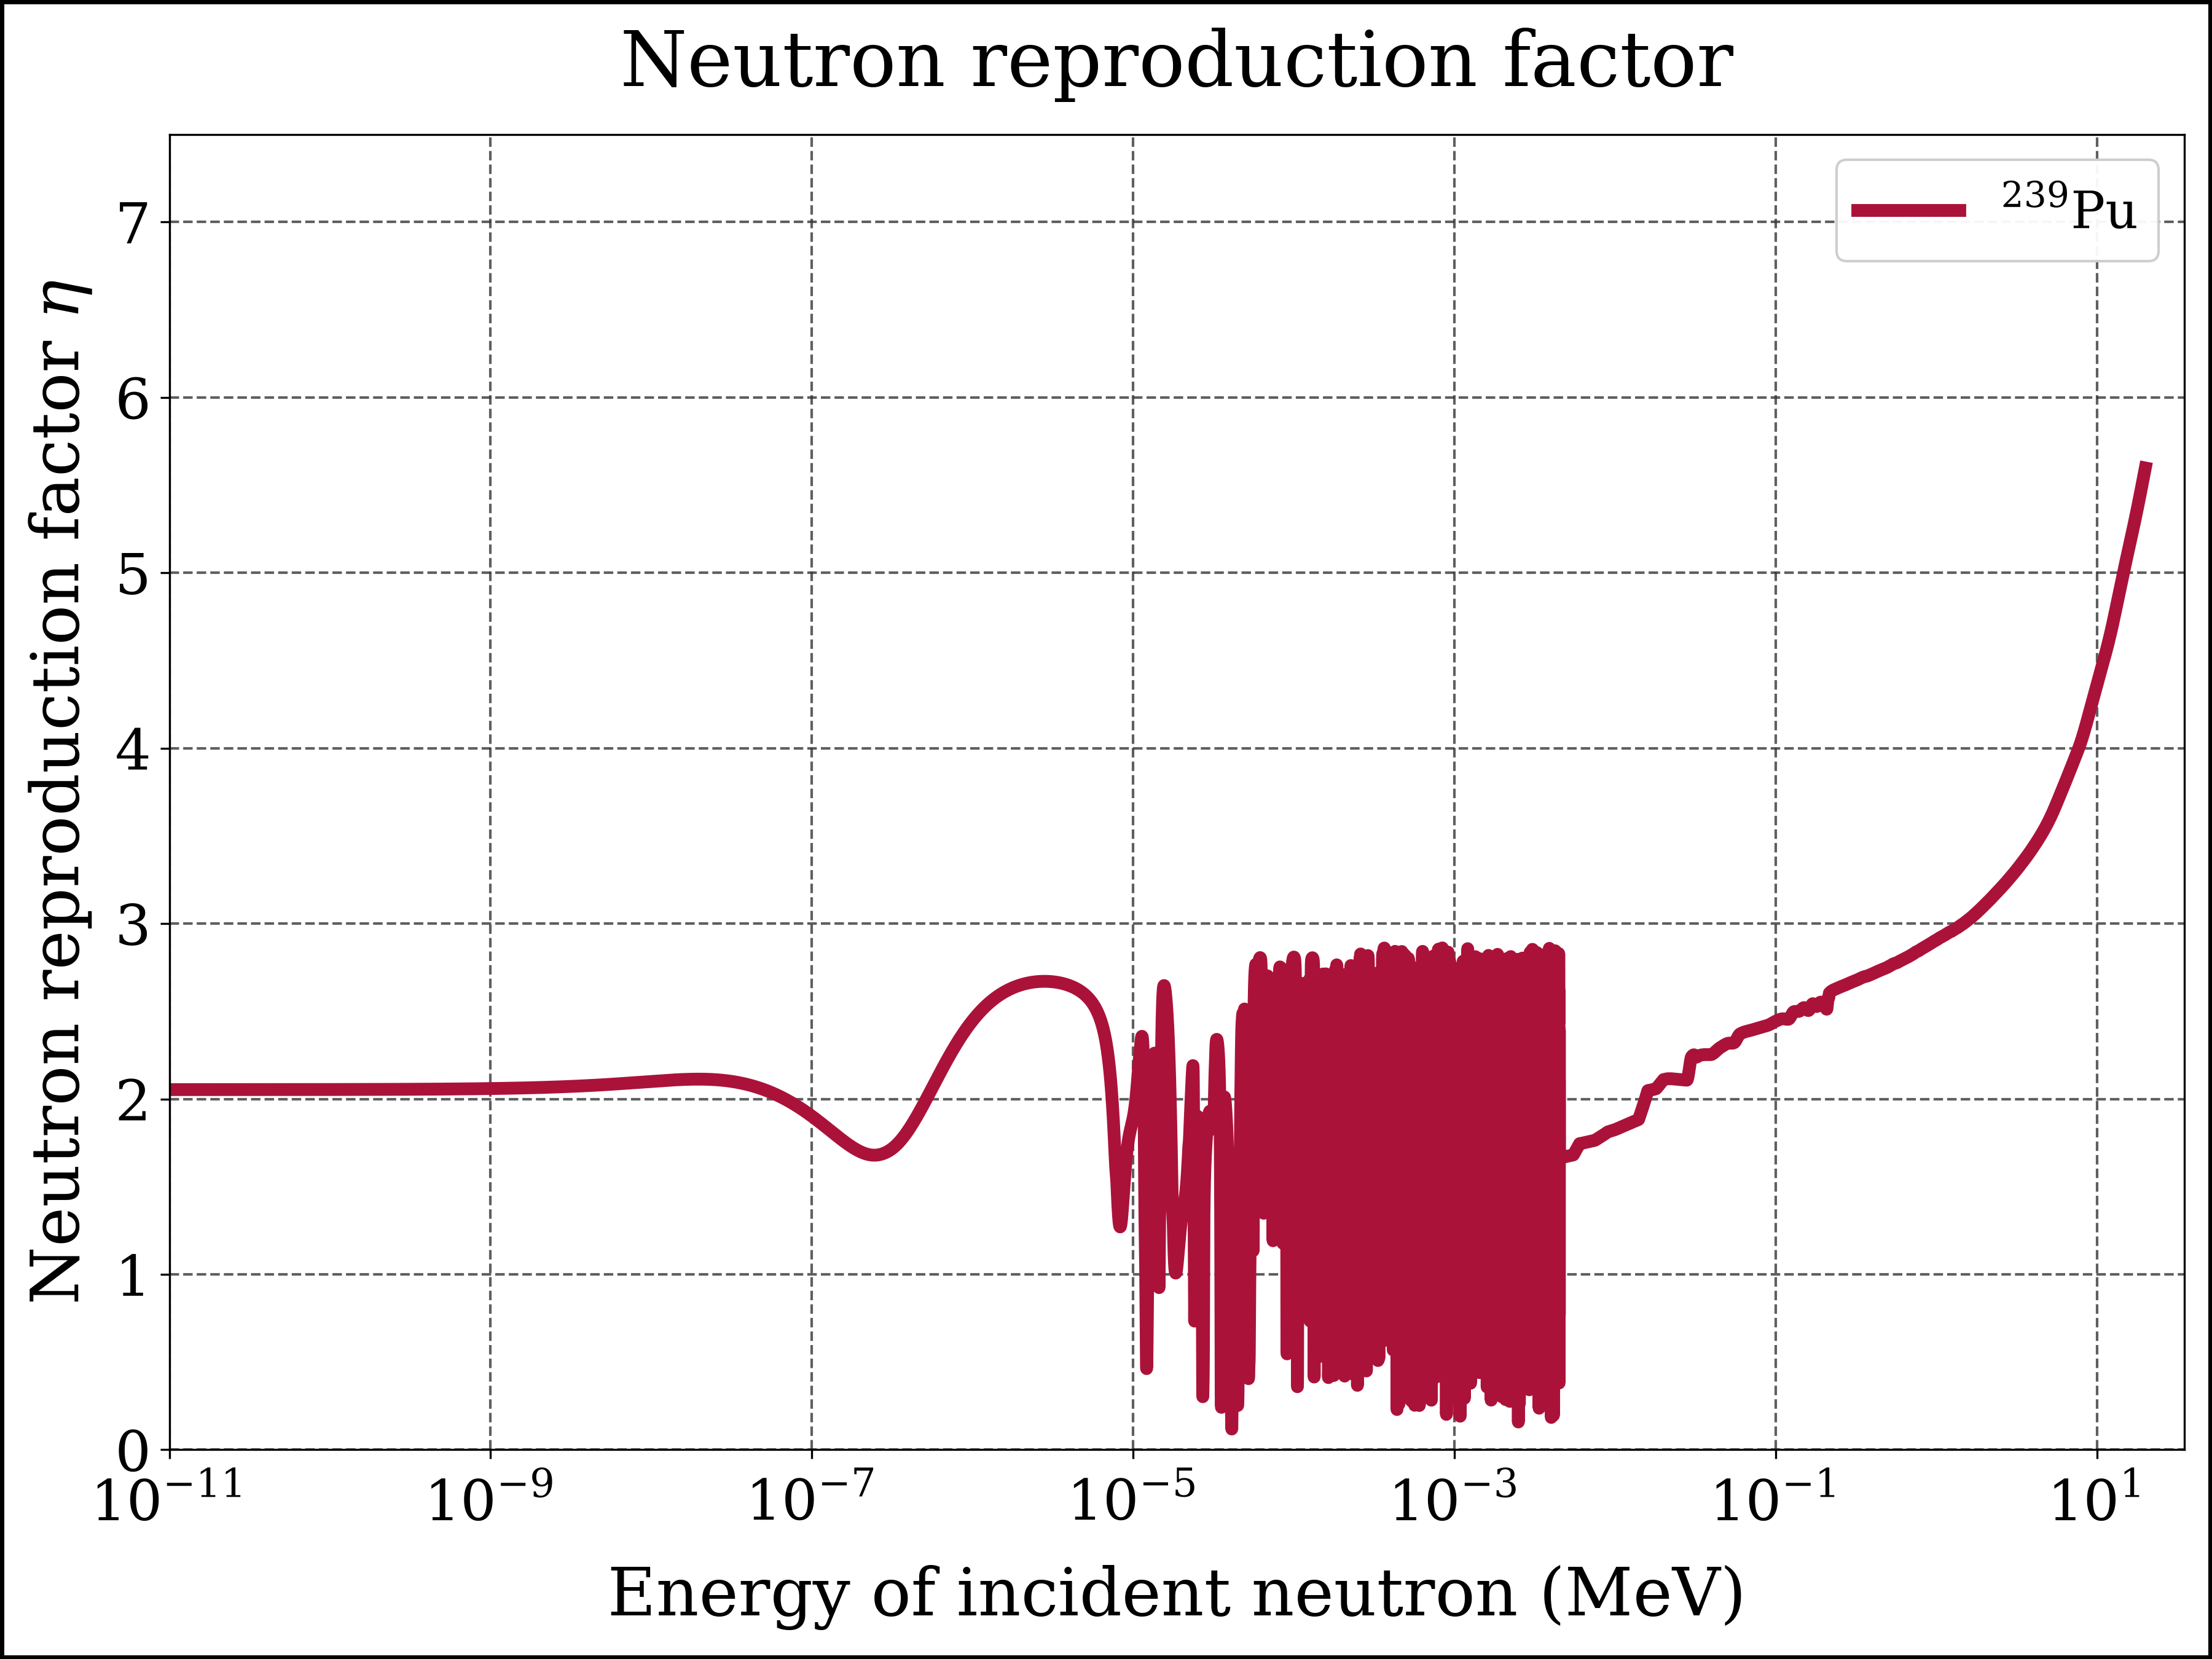

In [32]:
#| echo: true
#| label: fig-nrf-pu239
#| fig-cap: 'Neutron reproduction factor for Pu-239'

x = E_fine
y = nrf_pu239(E_fine)
fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
axes.plot(x, y, label=r'$\mathrm{^{239}Pu}$',
          color=color_pu239, linestyle=ls1, linewidth=lw1, marker=None)
#
xlims      =  [1E-11, 35]
ylims      =  [0, 7.5]
file_name  =  'nrf_pu239_logE'
#
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

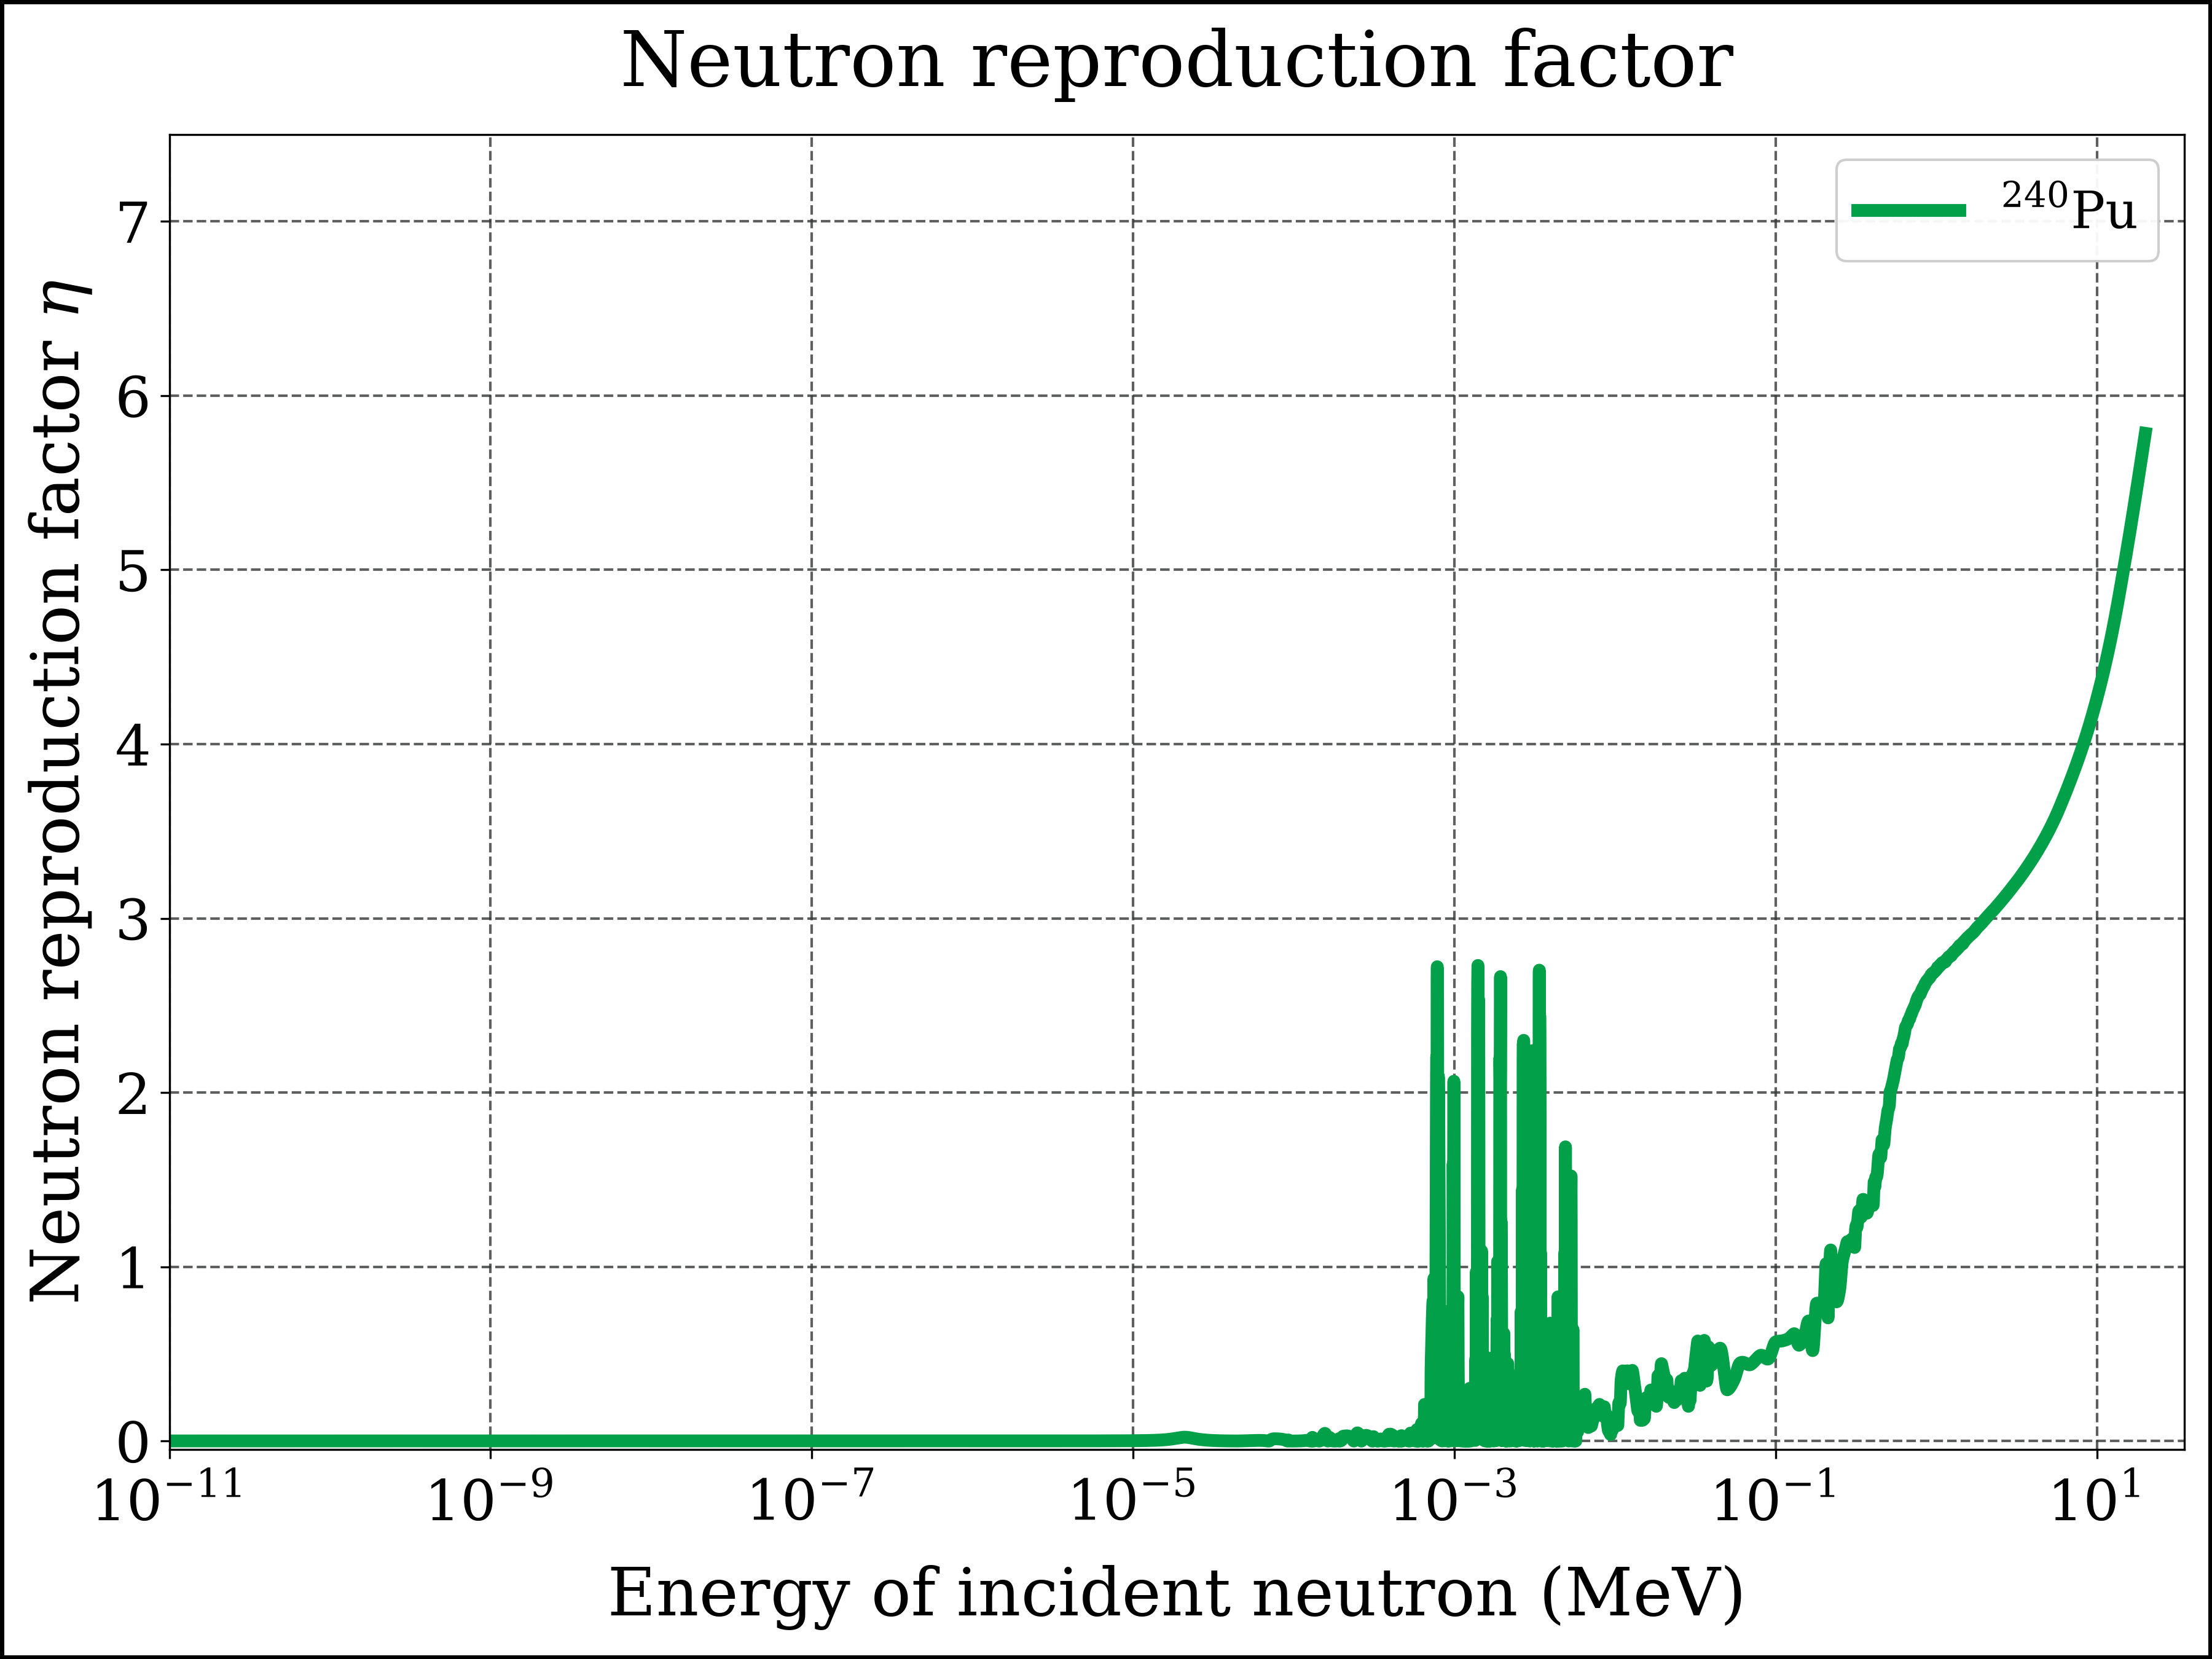

In [33]:
#| echo: true
#| label: fig-nrf-pu240
#| fig-cap: 'Neutron reproduction factor for Pu-240'

x = E_fine
y = nrf_pu240(E_fine)
fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
axes.plot(x, y, label=r'$\mathrm{^{240}Pu}$',
          color=color_pu240, linestyle=ls1, linewidth=lw1, marker=None)
#
xlims      =  [1E-11, 35]
ylims      =  [-0.05, 7.5]
file_name  =  'nrf_pu240_logE'
#
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

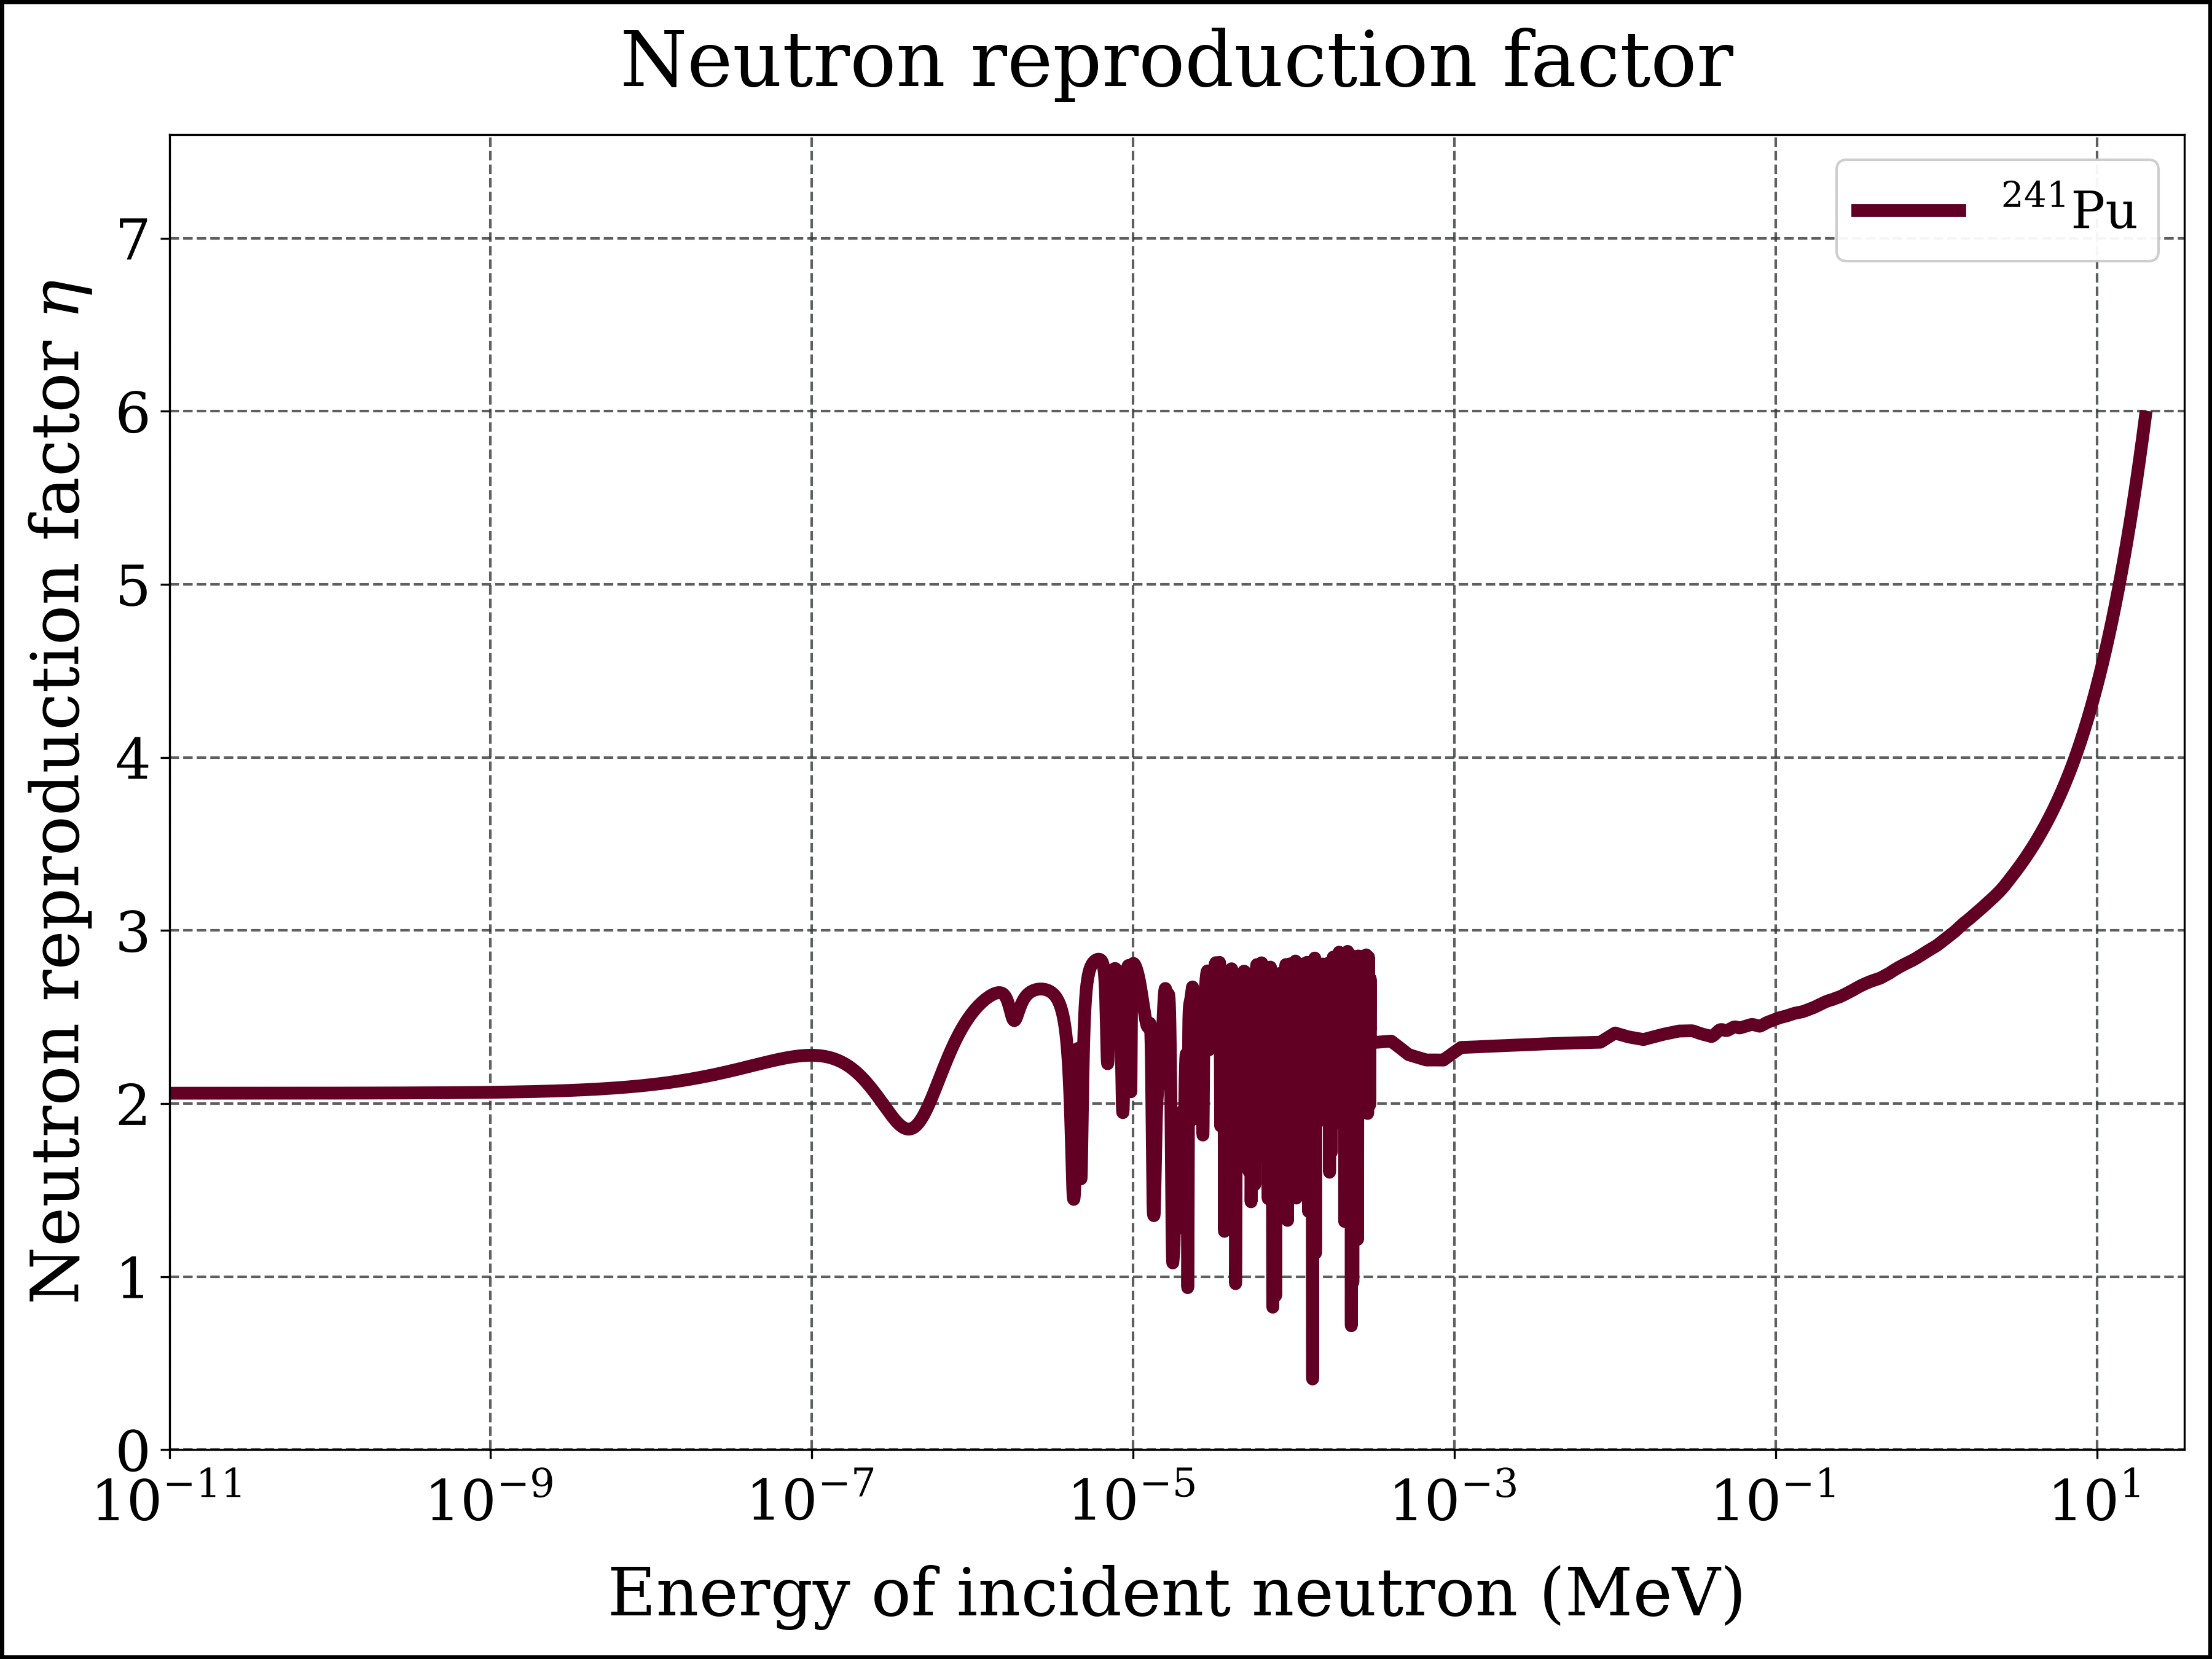

In [34]:
#| echo: true
#| label: fig-nrf-pu241
#| fig-cap: 'Neutron reproduction factor for Pu-241'

x = E_fine
y = nrf_pu241(E_fine)
fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
axes.plot(x, y, label=r'$\mathrm{^{241}Pu}$',
          color=color_pu241, linestyle=ls1, linewidth=lw1, marker=None)
xlims      =  [1E-11, 35]
ylims      =  [0, 7.6]
file_name  =  'nrf_pu241_logE'
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

## Comparisons

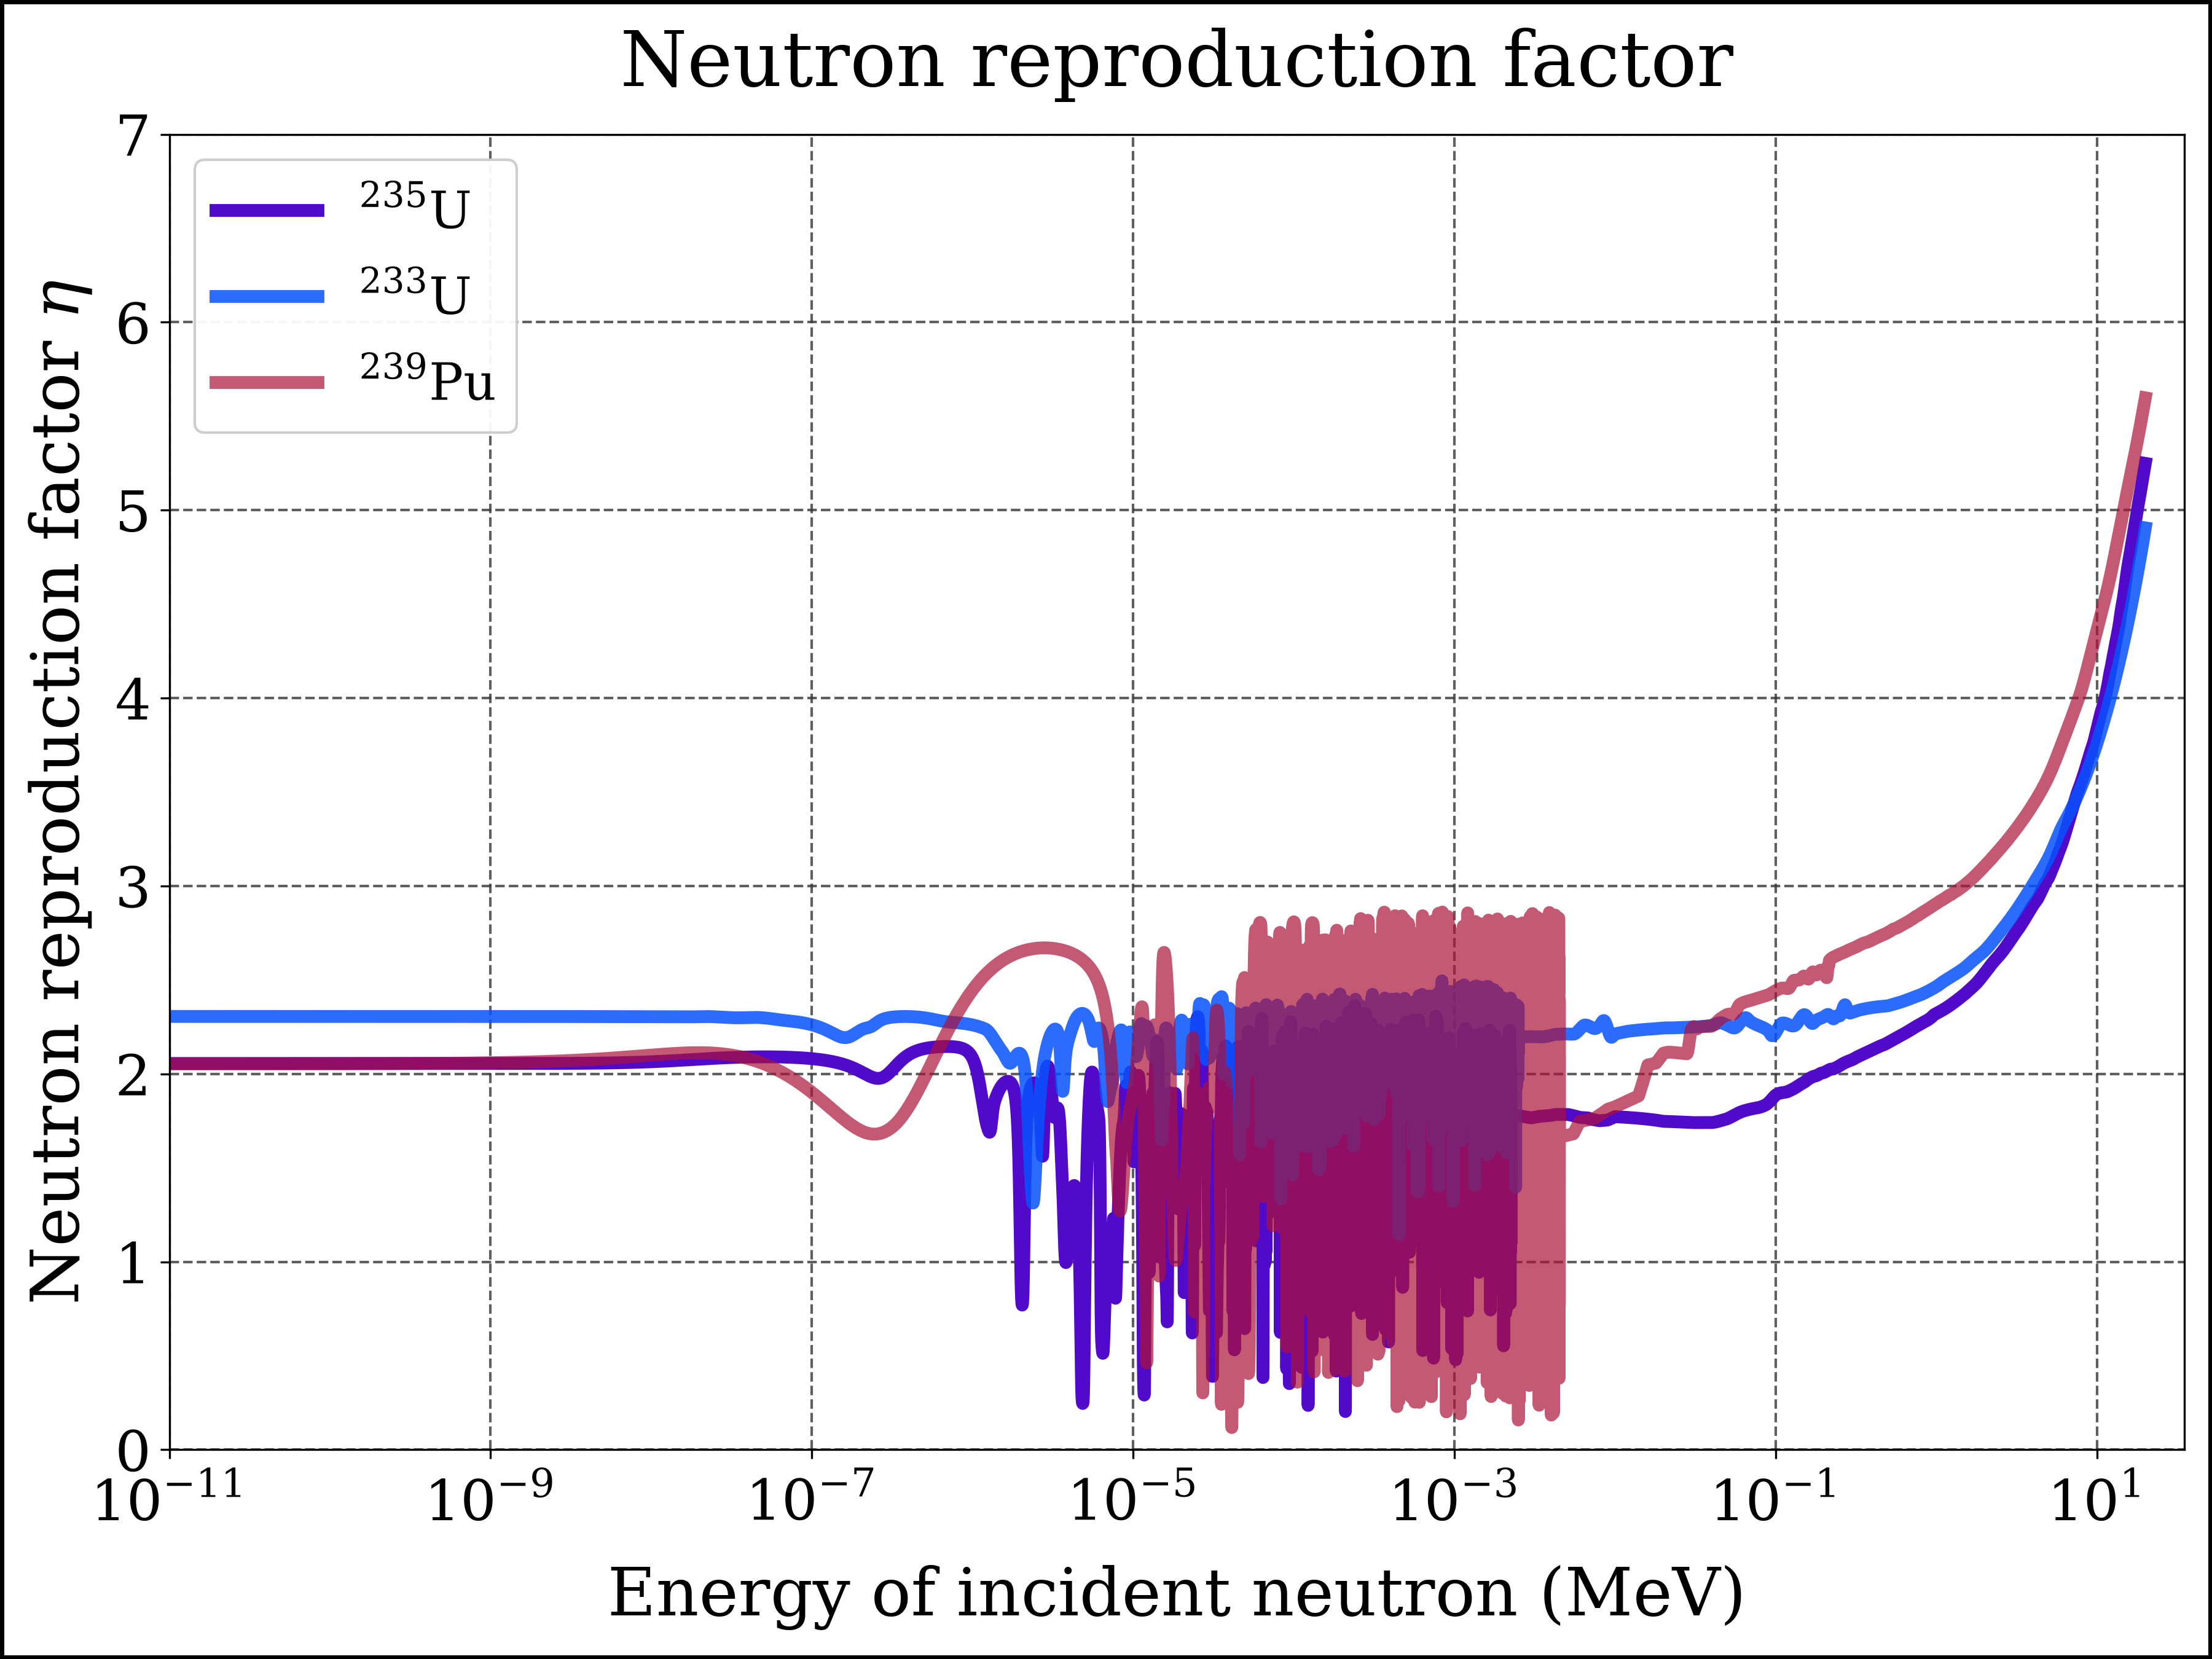

In [35]:
#| echo: true
#| label: fig-nrf-u233-u235-pu239-loge
#| fig-cap: 'Neutron reproduction factor for the 3 principal fissile actinides: U-233, U-235 and Pu-239 (logarithmic scaling of energy axis)'

fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
#
x = E_fine
y = nrf_u235(E_fine)
axes.plot(x, y, label=r'$\mathrm{^{235}U}$',
          color=color_u235, linestyle=ls1, linewidth=lw1, marker=None, alpha=1.00)
#
y = nrf_u233(E_fine)
axes.plot(x, y, label=r'$\mathrm{^{233}U}$',
          color=color_u233, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.85)
#
y = nrf_pu239(E_fine)
axes.plot(x, y, label=r'$\mathrm{^{239}Pu}$',
          color=color_pu239, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.70)
#
xscale     =  'log'
yscale     =  'linear'
xlims      =  [1E-11, 35]
ylims      =  [0, 7]
file_name  =  'nrf_u233_u235_pu239_logE'
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

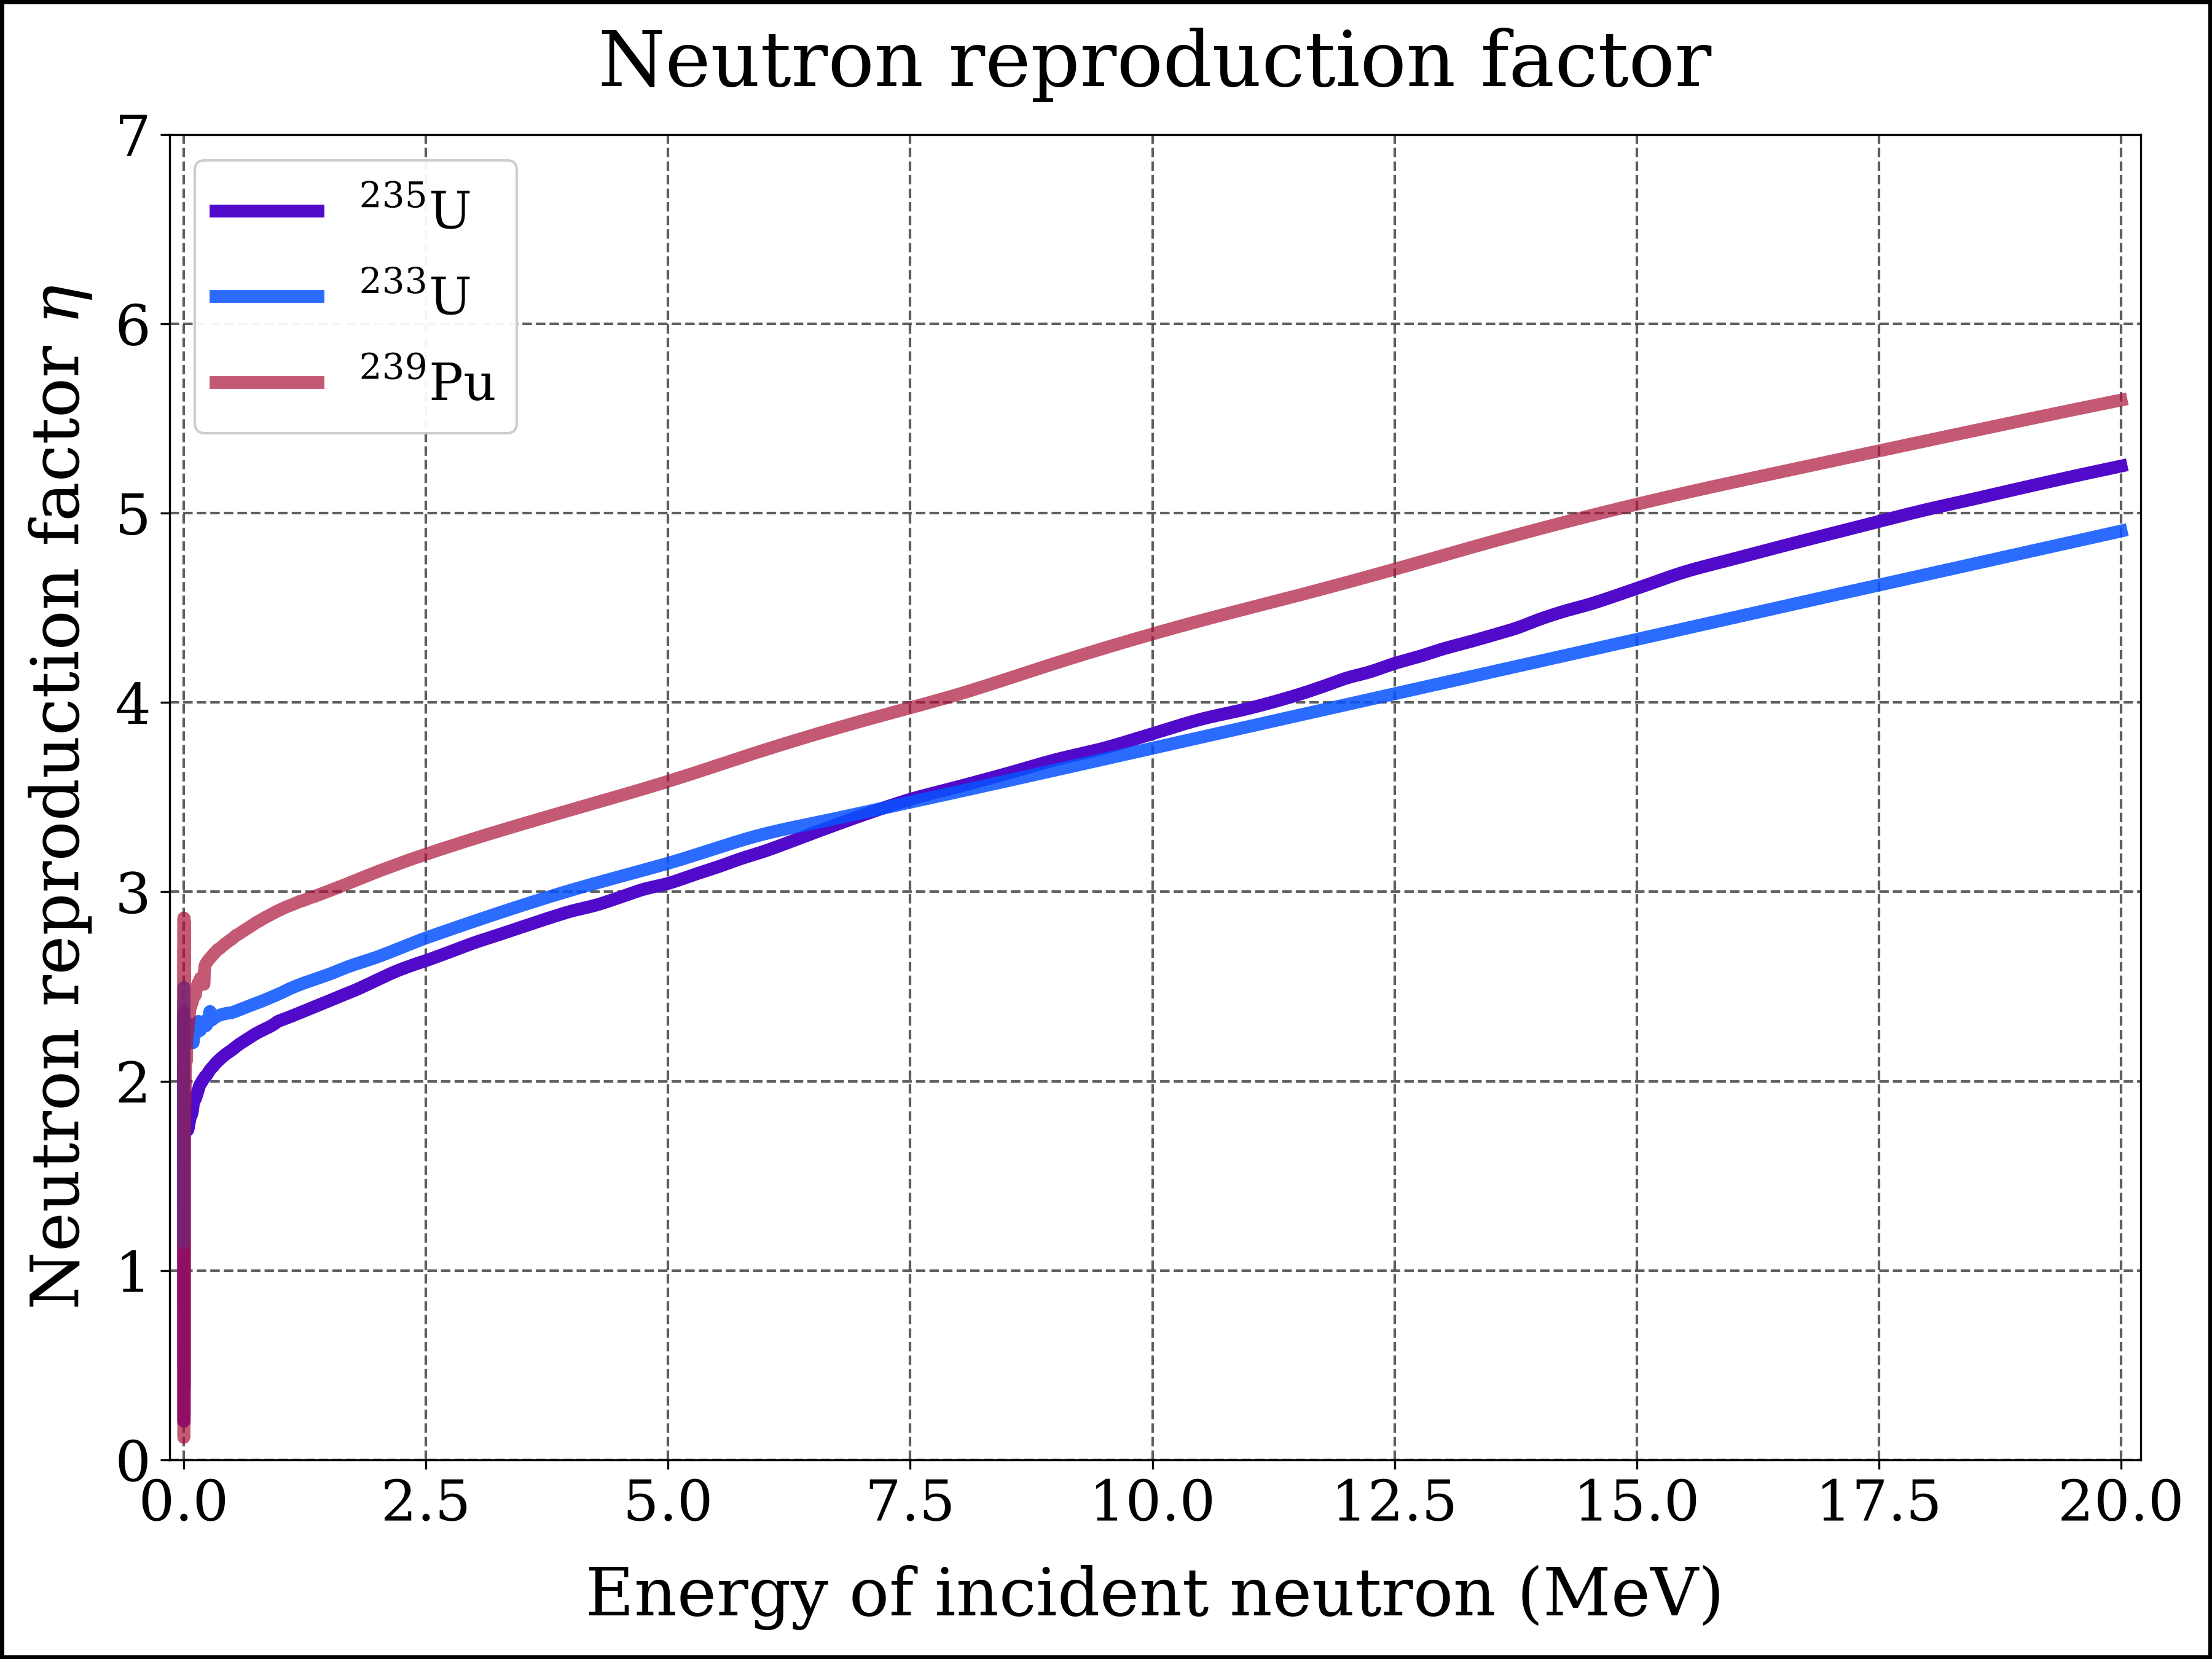

In [36]:
#| echo: true
#| label: fig-nrf-u233-u235-pu239-line
#| fig-cap: 'Neutron reproduction factor for the 3 principal fissile actinides: U-233, U-235 and Pu-239 (linear scaling of energy axis)'

fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
#
x = E_fine
y = nrf_u235(E_fine)
axes.plot(x, y, label=r'$\mathrm{^{235}U}$',
          color=color_u235, linestyle=ls1, linewidth=lw1, marker=None, alpha=1.00)
#
y = nrf_u233(E_fine)
axes.plot(x, y, label=r'$\mathrm{^{233}U}$',
          color=color_u233, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.85)
#
y = nrf_pu239(E_fine)
axes.plot(x, y, label=r'$\mathrm{^{239}Pu}$',
          color=color_pu239, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.70)
#
xscale = 'linear'
yscale = 'linear'
xlims        =  [-0.15, 20.2]
ylims        =  [0, 7]
file_name    =  'nrf_u233_u235_pu239_linE'
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

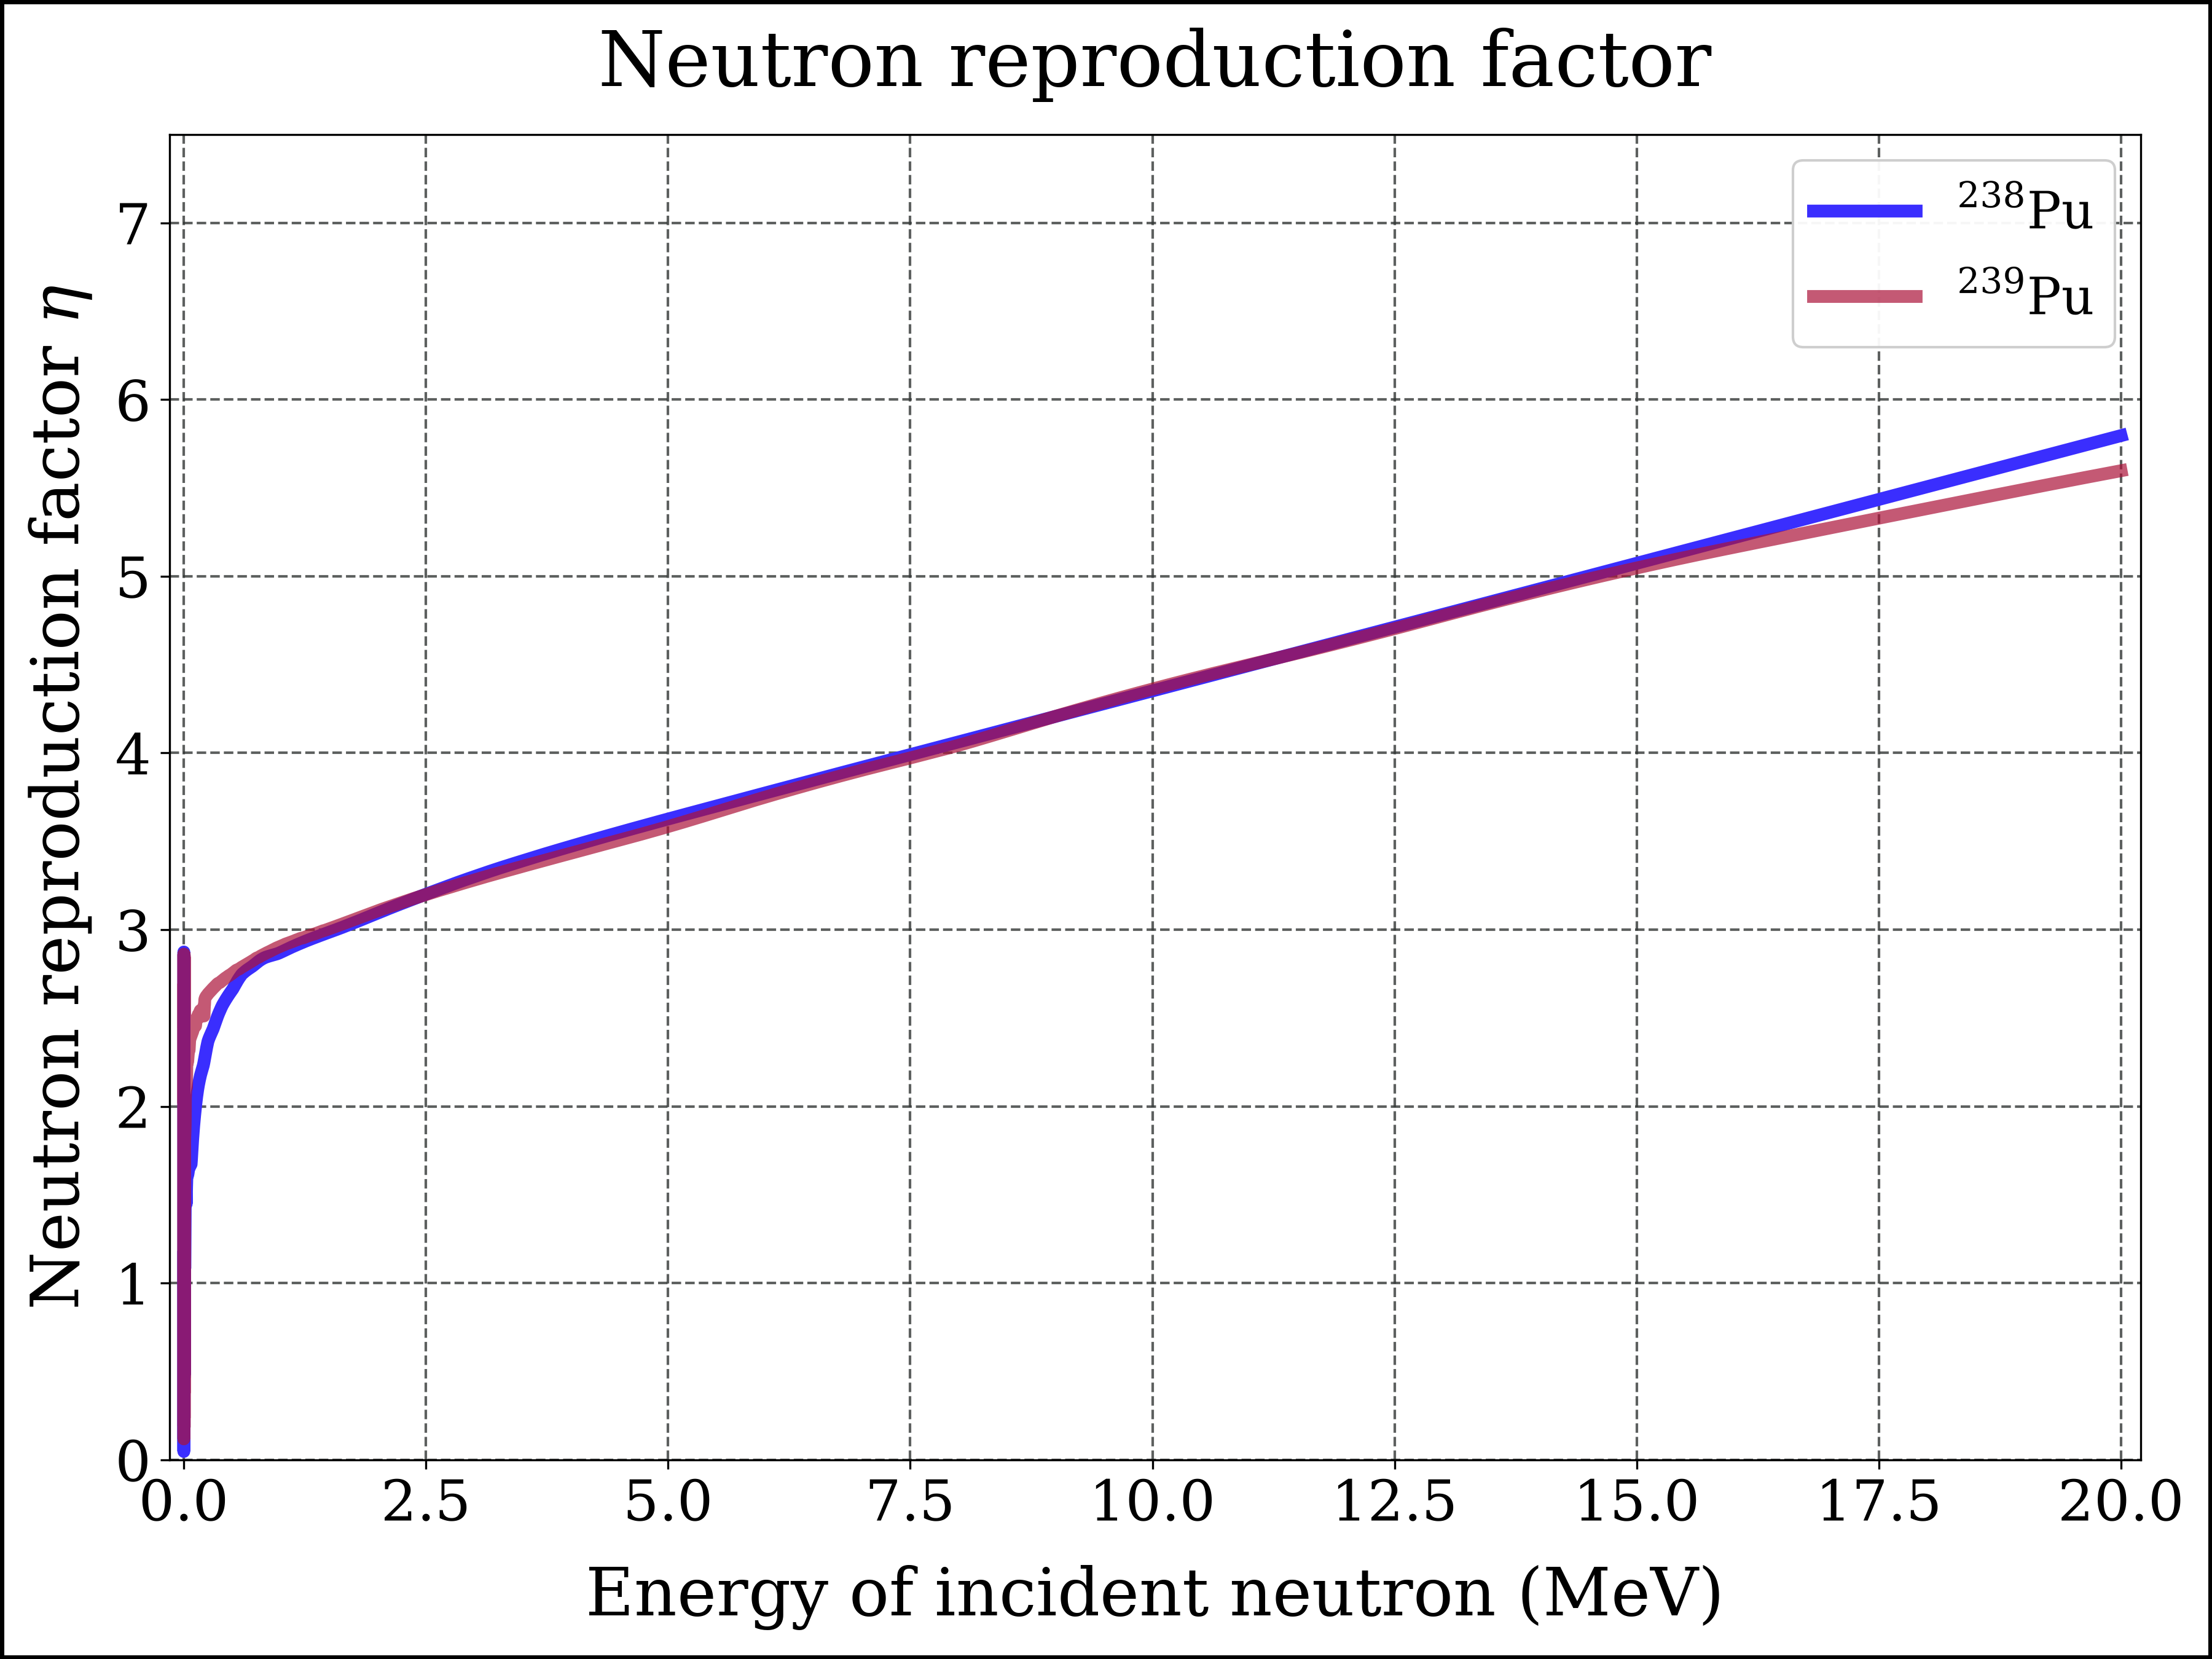

In [37]:
#| echo: true
#| label: fig-nrf-pu238-pu239-line
#| fig-cap: 'Neutron reproduction factor for Pu-238 and Pu-239 (linear scaling of energy axis)'

fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
#
x = E_fine
y = nrf_pu238(E_fine)
axes.plot(x, y, label=r'$\mathrm{^{238}Pu}$',
          color=color_pu238, linestyle=ls1, linewidth=lw1, marker=None, alpha=1.00)
#
y = nrf_pu239(E_fine)
axes.plot(x, y, label=r'$\mathrm{^{239}Pu}$',
          color=color_pu239, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.70)
#
xscale = 'linear'
yscale = 'linear'
xlims        =  [-0.15, 20.2]
ylims        =  [0, 7.5]
file_name    =  'nrf_pu238_pu239_linE'
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

**Commentary.** @fig-nrf-pu238-pu239-line compares $^{238}\mathrm{Pu}$ with
$^{239}\mathrm{Pu}$ on a linear energy axis. Above about 1 MeV the two curves are
practically identical, and above about 3 MeV the $\eta$ of $^{238}\mathrm{Pu}$ is even
marginally higher. In this energy range the fission cross section of
$^{238}\mathrm{Pu}$ is actually *larger* than that of $^{239}\mathrm{Pu}$
(`{python} f"{σ_nf_pu238(1.0):.2f}"` b against `{python} f"{σ_nf_pu239(1.0):.2f}"` b at
1 MeV), and capture competes only weakly ($\alpha$ is a few percent): almost every fast
neutron absorbed in $^{238}\mathrm{Pu}$ causes a fission. The "mediocre" fission
cross section of $^{238}\mathrm{Pu}$ is a property of *slow* neutrons. Below about
1 MeV capture competes more strongly, and $\eta$ of $^{238}\mathrm{Pu}$ falls below
that of $^{239}\mathrm{Pu}$ (@fig-nrf-pu238). The consequences are discussed in
@sec-pu238.

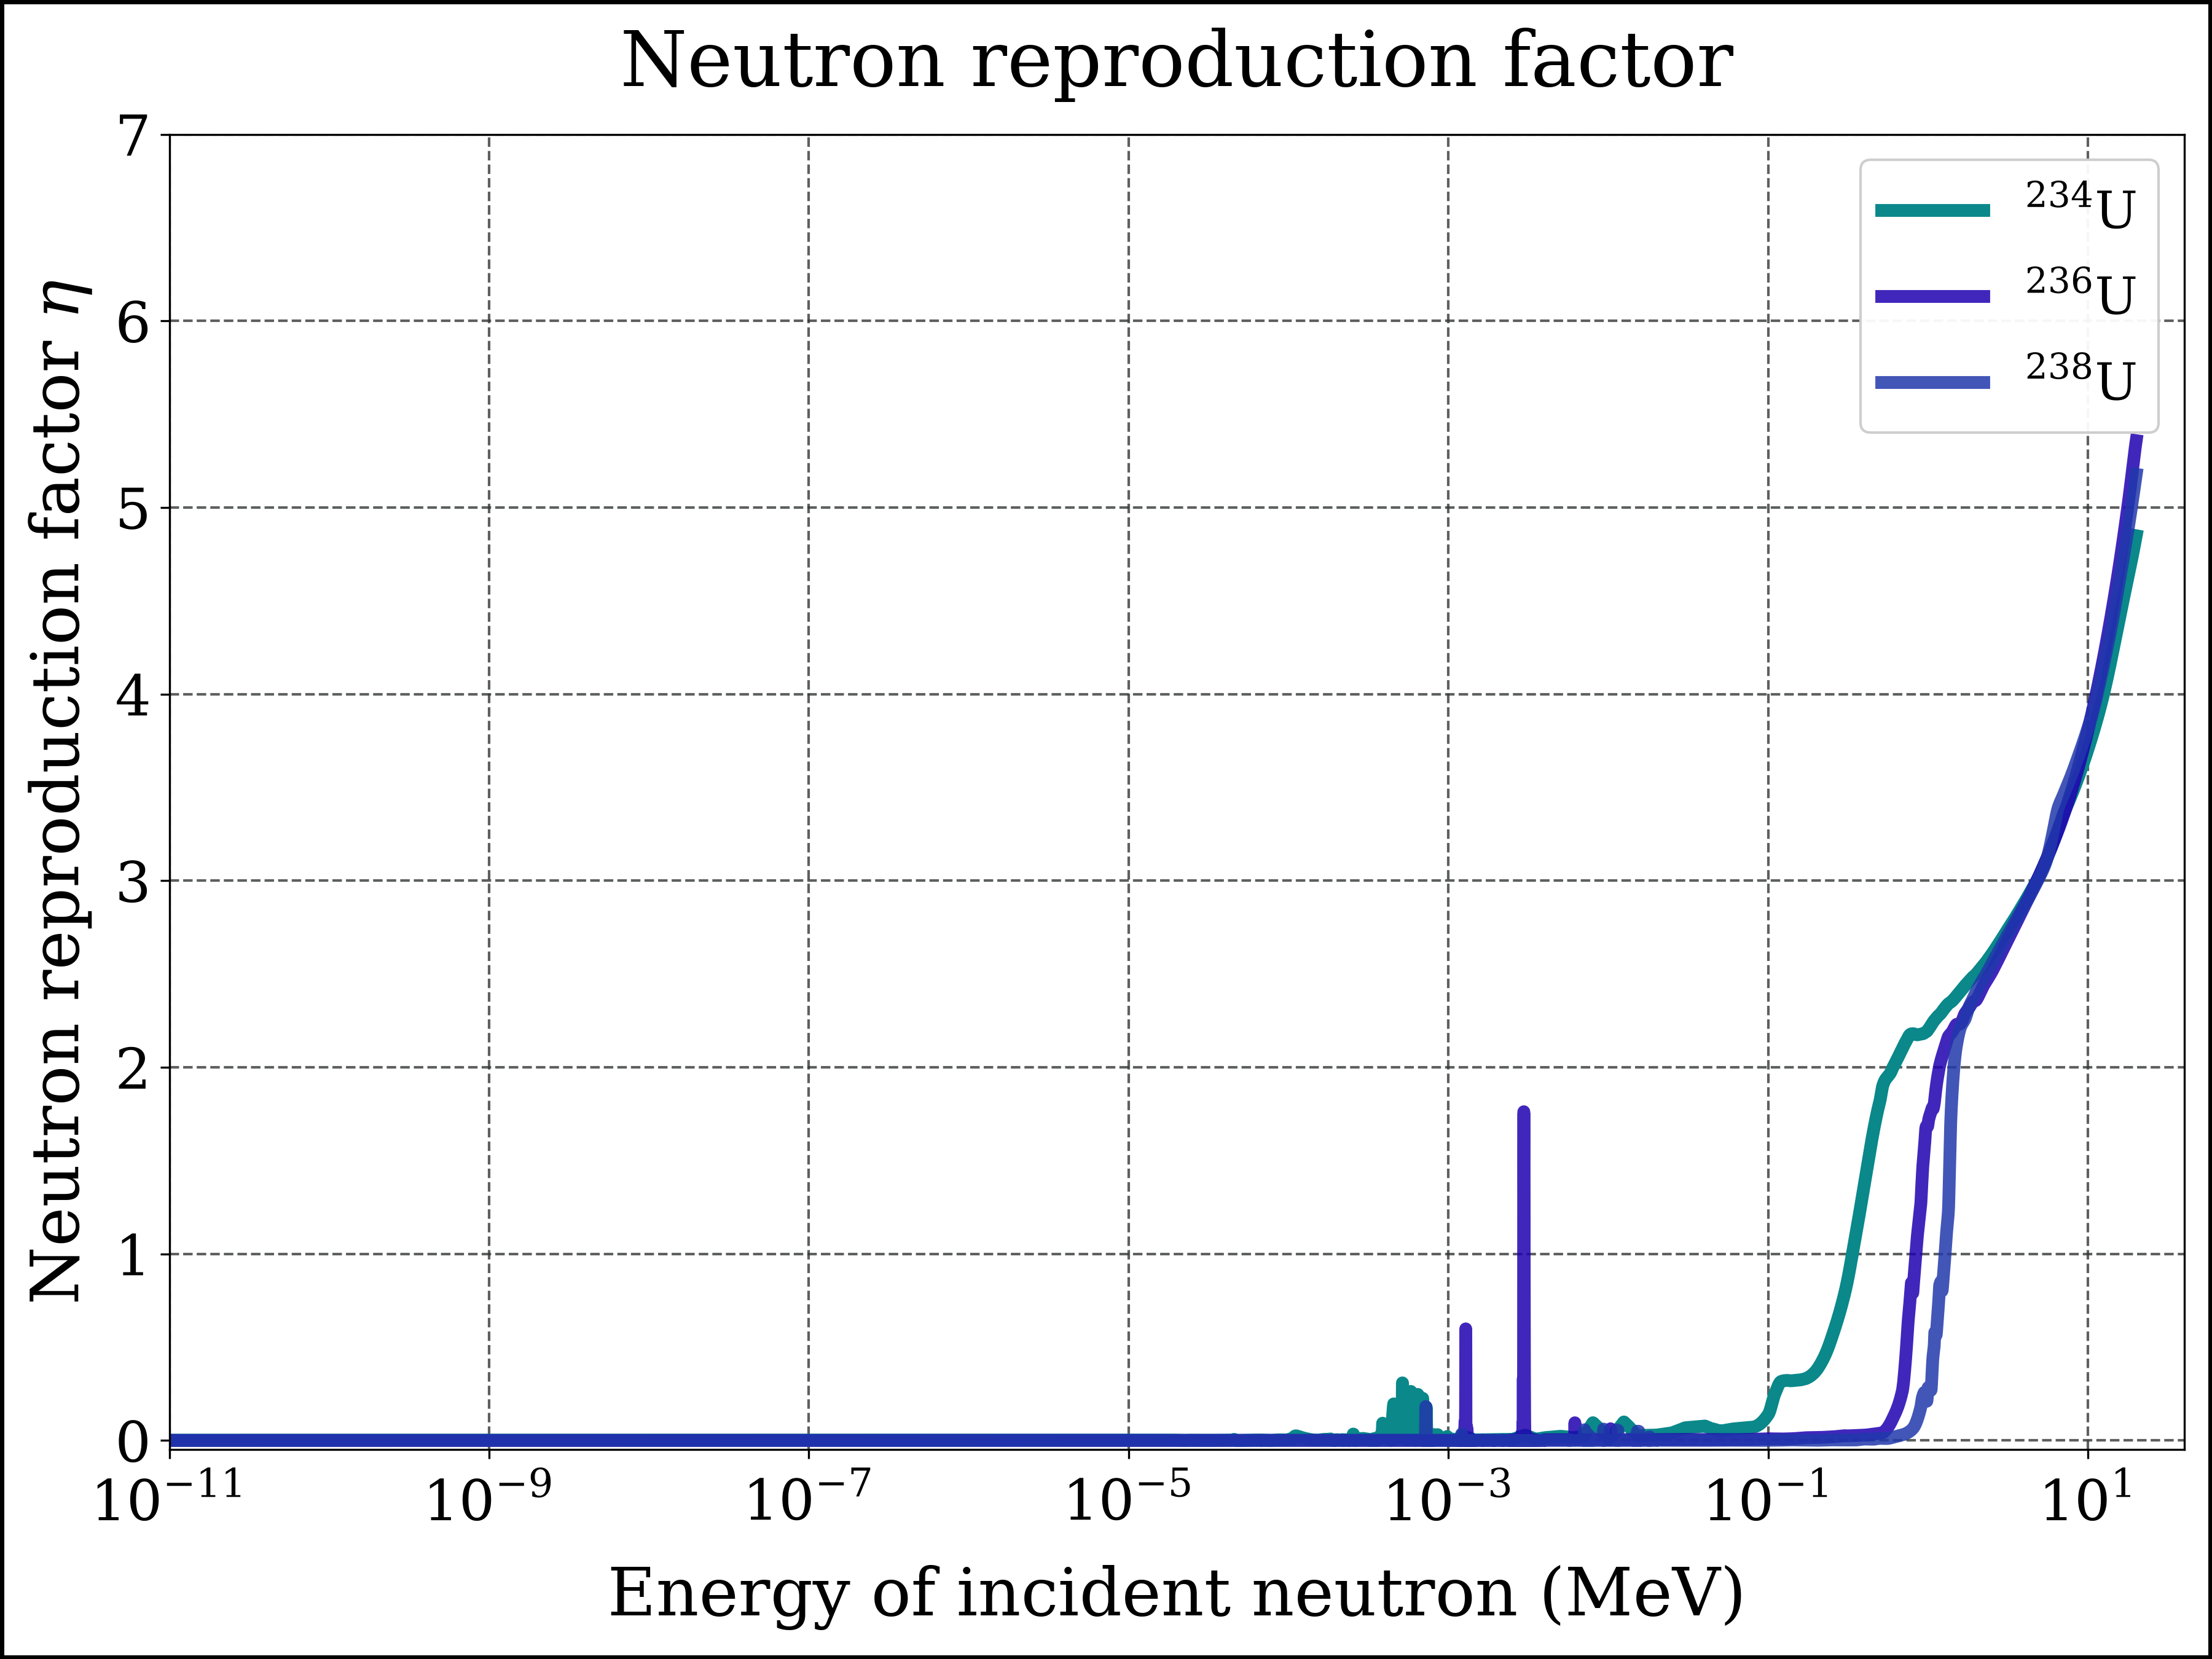

In [38]:
#| echo: true
#| label: fig-nrf-u234-u236-u238
#| fig-cap: 'Neutron reproduction factor for 3 fissionable actinides: U-234, U-236 and U-238'

fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
#
x = E_fine
y = nrf_u234(E_fine)
axes.plot(x, y, label=r'$\mathrm{^{234}U}$',
          color=color_u234, linestyle=ls1, linewidth=lw1, marker=None, alpha=1.00)
#
y = nrf_u236(E_fine)
axes.plot(x, y, label=r'$\mathrm{^{236}U}$',
          color=color_u236, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.85)
#
y = nrf_u238(E_fine)
axes.plot(x, y, label=r'$\mathrm{^{238}U}$',
          color=color_u238, linestyle=ls1, linewidth=lw1, marker=None, alpha=0.85)
#
xscale     =  'log'
yscale     =  'linear'
xlims      =  [1E-11, 40]
ylims      =  [-0.05, 7]
file_name  =  'nrf_u234_u236_u238_logE'
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

## What the curves show

* **Thermal region** ($E \lesssim 0.1$ eV). Both $\sigma_\mathrm{f}$ and
  $\sigma_\gamma$ of the fissile nuclides follow approximately the 1/v law, so their
  ratio $\alpha$ - and with it $\eta$ - is nearly constant. $^{239}\mathrm{Pu}$ is the
  exception: $\eta$ dips to about 1.7 near 0.25 eV, on the flank of its large 0.3 eV
  resonance, which has a high capture fraction. This makes the thermal $\eta$ of
  plutonium fuel sensitive to the temperature of the neutron population
  (@sec-eta-temperature).
* **Resonance region** (about 1 eV to 10 keV). Thousands of resonances: in
  capture-dominated resonances $\eta$ collapses (to about 0.2 for $^{235}\mathrm{U}$
  and 0.1 for $^{239}\mathrm{Pu}$), in fission-dominated ones it peaks. A spectrum
  average smooths this structure out.
* **Fast region** ($E \gtrsim 0.1$ MeV). $\alpha$ falls steeply while $\bar{\nu}$
  rises, so $\eta$ increases. At 1 MeV, $\eta \approx 2.47$ for $^{233}\mathrm{U}$,
  2.32 for $^{235}\mathrm{U}$ and 2.91 for $^{239}\mathrm{Pu}$: plutonium is the
  natural fuel of fast breeder reactors.
* **Even-$N$ nuclides** ($^{234}\mathrm{U}$, $^{236}\mathrm{U}$, $^{238}\mathrm{U}$,
  $^{240}\mathrm{Pu}$). Below the fission threshold $\eta\approx0$: almost every
  absorption is a capture. Above the threshold $\eta$ climbs to 2 - 3; for
  $^{238}\mathrm{U}$ it crosses $\eta=1$ at about 1.3 MeV (@fig-nrf-u234-u236-u238).
  $^{240}\mathrm{Pu}$ also shows isolated fission-dominated resonances in the keV
  region - *sub-threshold fission*.
* **$^{238}\mathrm{Pu}$** is even-$N$ too, and for thermal neutrons capture wins by far
  ($\eta\approx0.08$). But it has no sharp threshold: $\eta$ exceeds 1 already at about
  10 keV and reaches the level of $^{239}\mathrm{Pu}$ above 1 MeV (@fig-nrf-pu238,
  @fig-nrf-pu238-pu239-line).

All curves end at 20 MeV, the upper end of the tabulated data.

# Spectrum-averaged reproduction factors {#sec-results}

## The thermal reactor spectrum

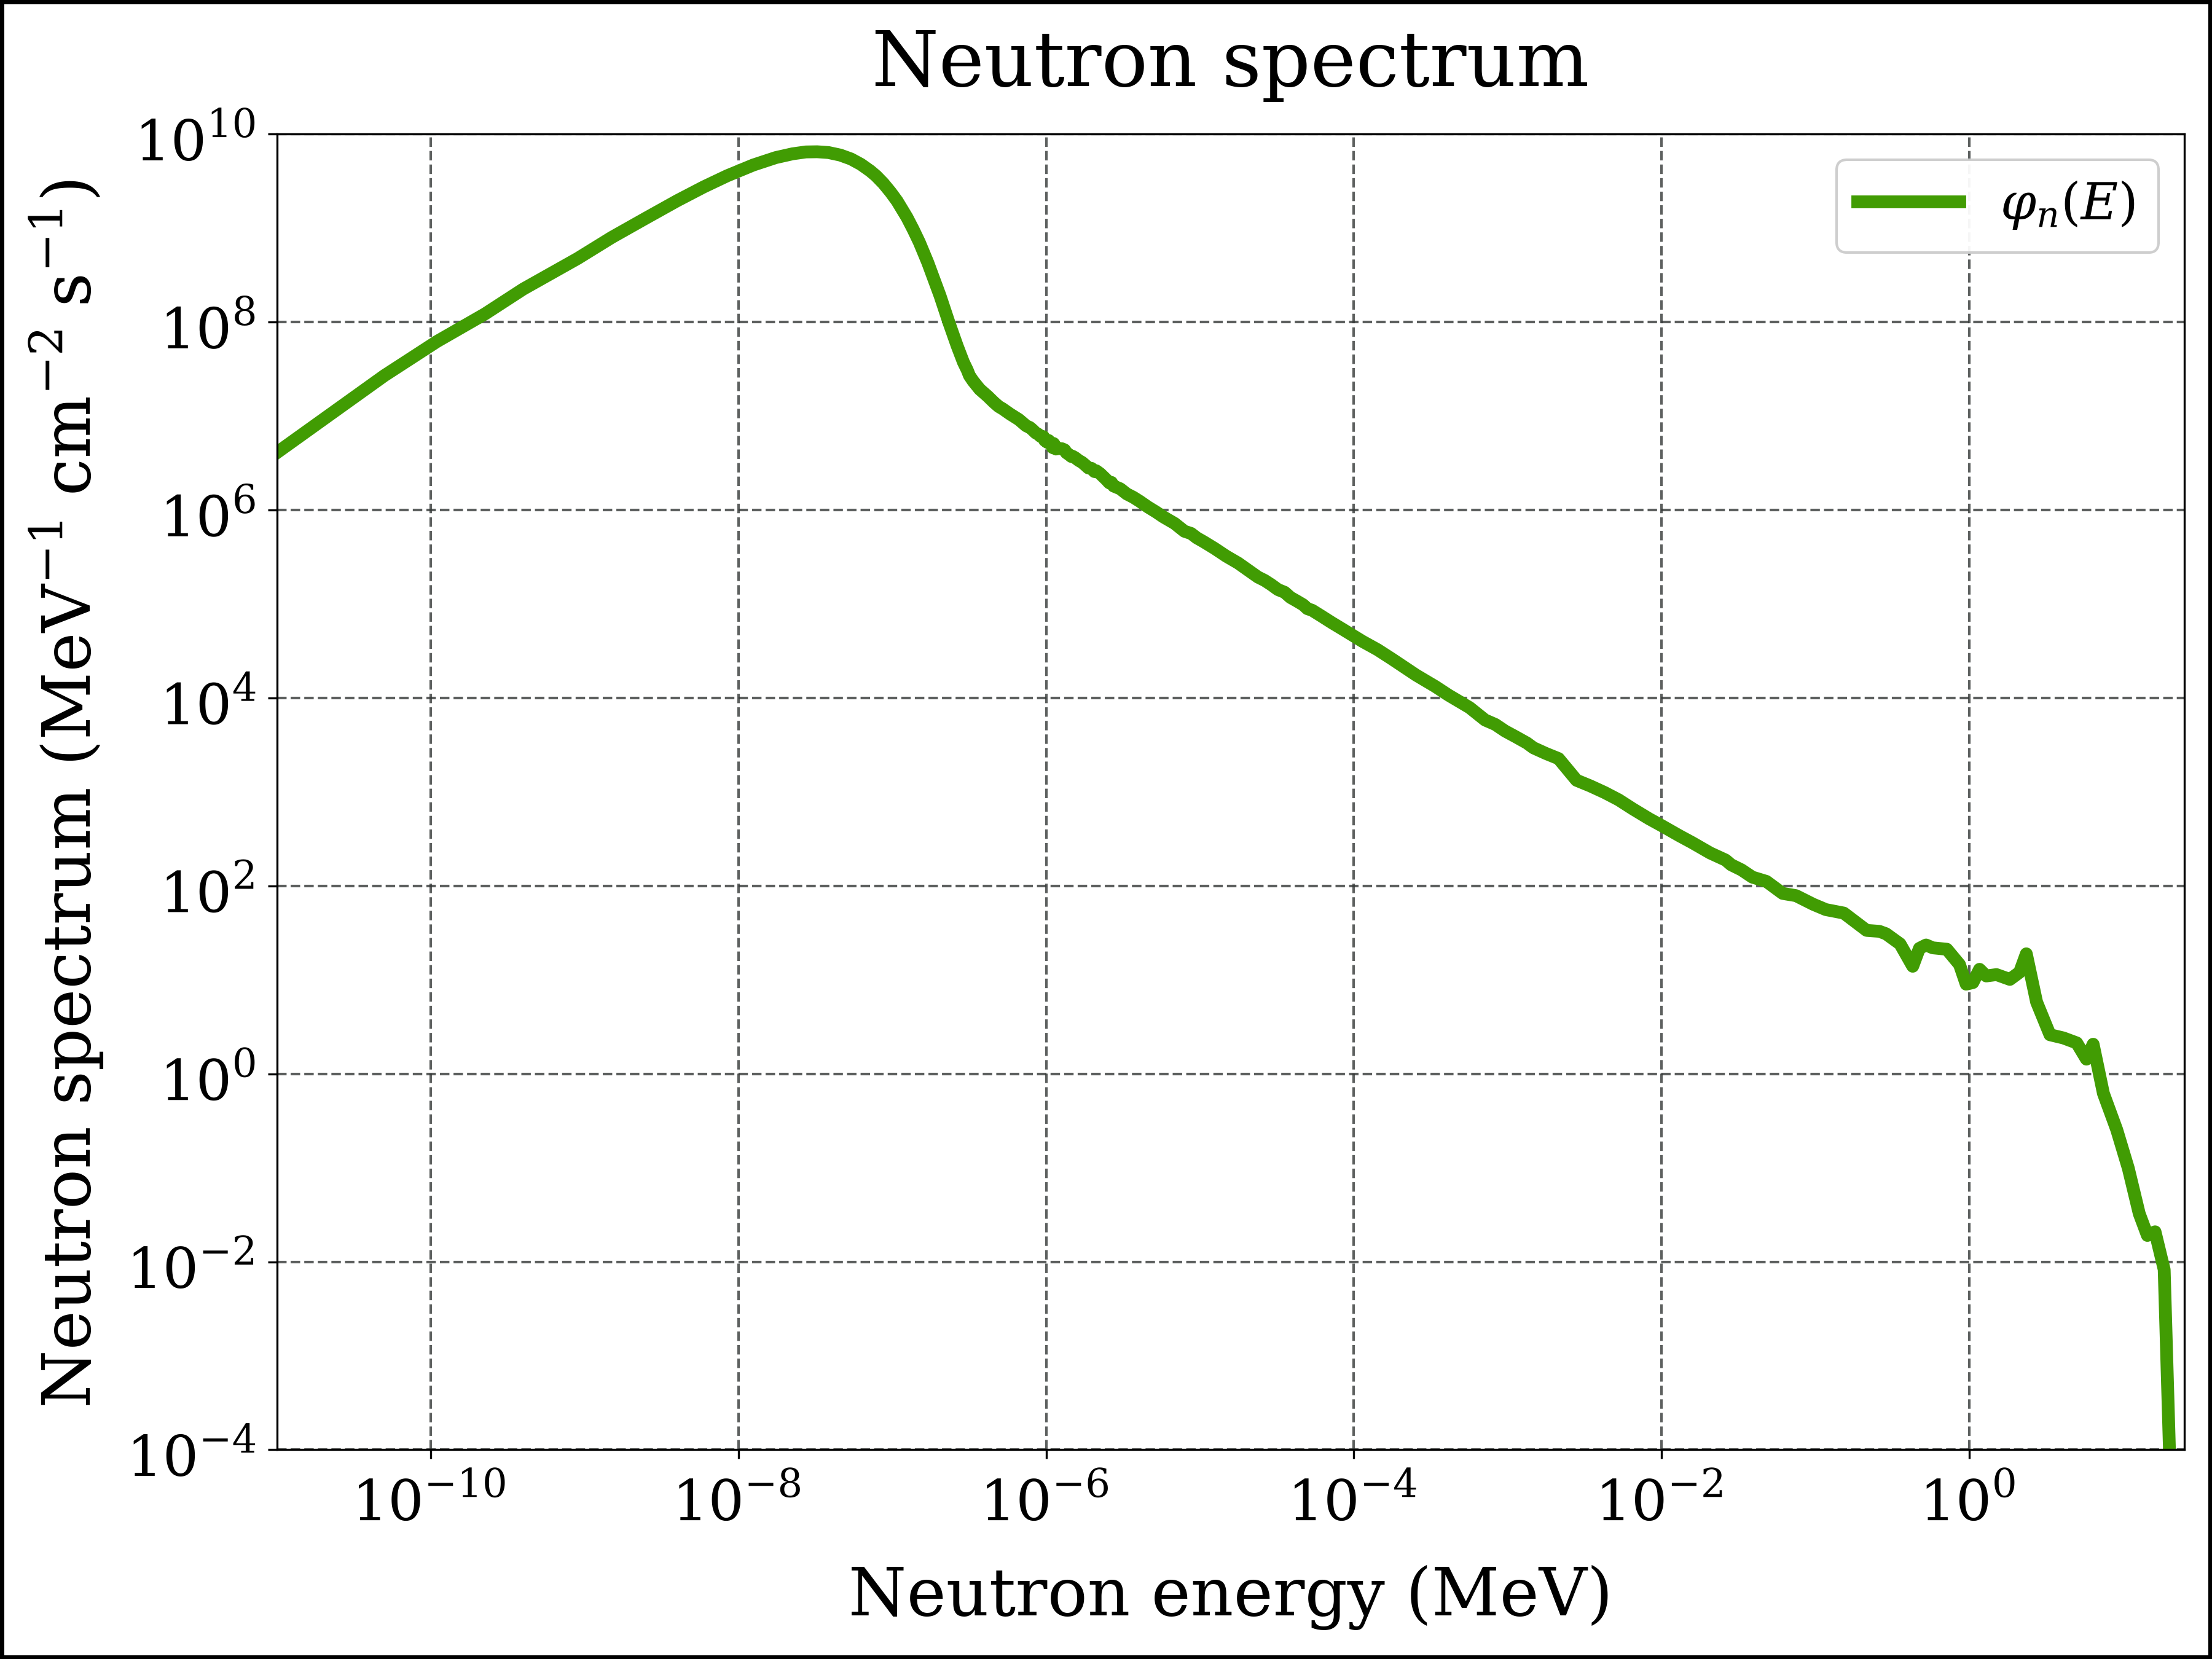

In [39]:
#| echo: true
#| label: fig-neutron-fluence-rate
#| fig-cap: 'Neutron fluence rate in the nuclear reactor for which spectrum-averaged effective neutron reproduction factors are quantified'

fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
#
x = eng_φ_vec
y = φ_vec
axes.plot(x, y, label=r'$\varphi_{n}(E)$',
          color=color_n, linestyle=ls1, linewidth=lw1, marker=None)
#
title      =  'Neutron spectrum'
xlabel     =  'Neutron energy (MeV)'
ylabel     =  r'Neutron spectrum $\left(\mathrm{MeV^{-1}\;cm^{-2}\;s^{-1}}\right)$'
xlims      =  [E_min, E_max*1.25]
ylims      =  [1E-4, 1E10]
xscale     =  'log'
yscale     =  'log'
file_name  =  'neutron_fluence_rate_spectrum'
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

@fig-neutron-fluence-rate shows the two characteristic features of a thermal-reactor
spectrum: the Maxwellian **thermal peak** around 0.025 eV, where neutrons are in
thermal equilibrium with the moderator, and the **slowing-down region**, in which
$\varphi(E)\propto 1/E$, connecting it with the fission neutrons in the MeV range.

## Numerical integration: decade by decade {#sec-integration}

Every spectrum average is a ratio of energy integrals from $E_\mathrm{min}=10^{-5}$ eV
to $E_\mathrm{max}=20$ MeV. Each integral is split into sub-integrals that cover **one
decade of energy** each - $10^{-5}$ to $10^{-4}$ eV, $10^{-4}$ to $10^{-3}$ eV, ...,
1 to 10 MeV and 10 to 20 MeV - and the sub-integrals are summed:

$$
\int_{E_\mathrm{min}}^{E_\mathrm{max}} g(E)\,\mathrm{d}E
= \sum_{k} \int_{E_k}^{E_{k+1}} g(E)\,\mathrm{d}E .
$$ {#eq-decades}

Splitting by decades suits the physics: over 12 decades the integrands change by many
orders of magnitude, and on a logarithmic energy scale every decade carries its own,
equally important structure (thermal peak, resonances, fast region). As a bonus, each
sub-integral shows *where in energy* the reactions happen (@sec-where-absorbed).

**Quadrature rule.** Inside each decade the integral is evaluated with composite
**Gauss-Legendre quadrature** on the tabulated energy grid: every interval between two
consecutive tabulated energies is integrated with an $n$-point Gauss-Legendre rule,
which is *exact* for polynomials up to degree $2n-1$. Between two tabulated energies
every PCHIP interpolant is a cubic polynomial, so the integrand
$\bar{\nu}\,\sigma_\mathrm{f}\,\varphi$ is a polynomial of degree 9 - and already the
5-point rule integrates it exactly; we use 16 points (exact up to degree 31). No
resonance can be missed, because every resonance is described by tabulated points,
and those points are interval boundaries. In addition, the fine plotting grid
`E_fine` (about 8 000 points per decade, i.e. intervals narrower than 0.03 % of the
energy) is added as interval boundaries in every integral, so that integrands which
are not polynomials - $\eta(E)\,\varphi(E)$, the fission spectrum and the
Maxwellian - are integrated just as accurately.

**1σ error.** Each sub-integral is evaluated with 16 and with 8 points; the 16-point
value is used and the difference $|I_{16}-I_8|$ serves as a (conservative) 1σ error
estimate. The contributions of the hundreds of thousands of intervals are summed
with `math.fsum`, which adds floating-point numbers without accumulating round-off. Errors of the decades are added in quadrature, and for a ratio $q=x/y$ the
relative errors are added in quadrature:

$$
\sigma_q = |q|\,\sqrt{\left(\frac{\sigma_x}{x}\right)^2 + \left(\frac{\sigma_y}{y}\right)^2} .
$$ {#eq-error-ratio}

> **What the 1σ error does - and does not - include.** Because the quadrature is exact
> for the interpolated data, the numerical 1σ errors below are at the level of
> floating-point round-off (about $10^{-16}$ relative); only the flux-weighted mean
> $\langle\eta\rangle_\varphi$ of two nuclides, whose integrand is a ratio of
> polynomials with steep features, shows up to $10^{-10}$. These numbers say that the
> *integration* is exact - not that the *physics* is known to 16 digits. Larger,
> systematic effects are, first, the upper limit of 20 MeV: it leaves out the
> $2\times10^{-7}$ of all fission neutrons that are born above 20 MeV
> (@sec-fission-spectrum), which affects the fission-spectrum averages at the
> $10^{-7}$ level - negligible, but far larger than the round-off. Second, the
> interpolation between tabulated points (a test with linear instead of PCHIP interpolation changed
> the thermal $\langle\eta\rangle$ by $2\times10^{-5}$ relative for $^{235}\mathrm{U}$
> and by $5\times10^{-4}$ for $^{239}\mathrm{Pu}$, whose 0.3 eV resonance lies where the
> 181-point spectrum table is coarse) and, above all, the uncertainties of the evaluated
> nuclear data themselves, typically a few tenths of a percent.

> **Why not `scipy.integrate.quad`?** Adaptive Gauss-Kronrod quadrature chooses its own
> sampling points. Over the full energy range it misses most of the resonances: in an
> earlier version of this notebook it returned $\langle\eta\rangle_\varphi=0.31$ for
> $^{235}\mathrm{U}$ instead of 2.08, and the warning that hinted at the failure had
> been switched off. Applied decade by decade it comes close - but only to about
> $10^{-8}$ relative - and it reports hundreds of round-off warnings in the resonance
> decades.
> The trapezoidal rule on `E_fine` reaches only about $10^{-6}$ relative accuracy.

In [40]:
# --- Energy segments: one per decade of energy --------------------------------
def decade_segments(E_low, E_high):
    """Split [E_low, E_high] at every power of ten in between: one segment per
    decade of energy (the first and the last segment may be shorter)."""
    segments = []
    lower = E_low
    for k in range(-11, 3):                      # powers of ten from 1E-11 to 1E+02 MeV
        if E_low < 10.0**k < E_high:
            segments.append((lower, 10.0**k))    # one complete (or first, partial) decade
            lower = 10.0**k
    segments.append((lower, E_high))             # the last (partial) decade
    return segments


E_thermal = 6.25E-07                             # MeV (0.625 eV): upper end of the thermal group

decades         = decade_segments(E_min, E_max)       # whole energy range
thermal_decades = decade_segments(E_min, E_thermal)   # thermal group only

print(f'The integrals are split into {len(decades)} decades:')
for a, b in decades:
    print(f'   {a * 1E6:9.2e} eV  -  {b * 1E6:9.2e} eV')


# --- Gauss-Legendre quadrature --------------------------------------------------
# Nodes x and weights w of the n-point rule on the reference interval [-1, 1]:
x_gl16, w_gl16 = np.polynomial.legendre.leggauss(16)  # exact for polynomials up to degree 31
x_gl8,  w_gl8  = np.polynomial.legendre.leggauss(8)   # exact for polynomials up to degree 15


def gauss_legendre(f, points, x_gl, w_gl):
    """Composite Gauss-Legendre rule: integrate f(E) over every interval between
    two consecutive energies in `points` (sorted) and add up the results."""
    h   = np.diff(points)                                # widths of the intervals
    mid = np.convolve(points, [0.5, 0.5], mode='valid') # mid-points: average of neighbours
    E   = mid.reshape(-1, 1) + np.outer(h / 2, x_gl)     # nodes: one row per interval
    per_interval = h / 2 * np.sum(f(E) * w_gl, axis=1)   # integral over each interval
    return math.fsum(per_interval)                       # exact summation, no round-off build-up


def integral_segment(f, a, b, breakpoints):
    """Integral of f(E) from a to b, and its 1σ error estimate.
    All breakpoints between a and b become interval boundaries: np.clip moves
    the points outside [a, b] onto a or b, and np.unique sorts the result and
    removes duplicates.  The 16-point value is the result; its difference from
    the 8-point value is the (conservative) 1σ error estimate."""
    points   = np.unique(np.clip(np.append(breakpoints, [a, b]), a, b))
    value_16 = gauss_legendre(f, points, x_gl16, w_gl16)
    value_8  = gauss_legendre(f, points, x_gl8, w_gl8)
    return value_16, abs(value_16 - value_8)


def integral(f, breakpoints, segments=decades):
    """Sum of the sub-integrals over all segments (decades).
    Returns (value, 1σ error); the errors of the segments are added in quadrature."""
    values, errors = [], []
    for a, b in segments:
        value, error = integral_segment(f, a, b, breakpoints)
        values.append(value)
        errors.append(error)
    return math.fsum(values), math.sqrt(math.fsum(e**2 for e in errors))


def breakpoints_of(*interpolants):
    """Interval boundaries for the quadrature: the fine grid E_fine (about 8 000
    points per decade) plus all tabulated energies of the given PCHIP interpolants."""
    return np.concatenate([E_fine] + [g.x for g in interpolants])


# --- Error propagation for (value, 1σ) pairs -------------------------------------
def ratio(numerator, denominator):
    """q = x / y; relative errors added in quadrature (eq-error-ratio)."""
    (x, σ_x), (y, σ_y) = numerator, denominator
    q = x / y
    return q, abs(q) * np.sqrt((σ_x / x)**2 + (σ_y / y)**2)


def add(first, second):
    """x + y; errors added in quadrature."""
    (x, σ_x), (y, σ_y) = first, second
    return x + y, np.hypot(σ_x, σ_y)


def pm(pair, decimals=4):
    """A (value, 1σ) pair as text:  'value ± 1σ'."""
    value, sigma = pair
    return f'{value:.{decimals}f} ± {sigma:.1e}'


# --- Nuclear data of every nuclide:  (ν̄(E), σ_f(E), σ_γ(E), η(E)) -----------------
nuclides = {
    'U-232':  (yield_fn_u232,  σ_nf_u232,  σ_nγ_u232,  nrf_u232),
    'U-233':  (yield_fn_u233,  σ_nf_u233,  σ_nγ_u233,  nrf_u233),
    'U-234':  (yield_fn_u234,  σ_nf_u234,  σ_nγ_u234,  nrf_u234),
    'U-235':  (yield_fn_u235,  σ_nf_u235,  σ_nγ_u235,  nrf_u235),
    'U-236':  (yield_fn_u236,  σ_nf_u236,  σ_nγ_u236,  nrf_u236),
    'U-238':  (yield_fn_u238,  σ_nf_u238,  σ_nγ_u238,  nrf_u238),
    'Pu-238': (yield_fn_pu238, σ_nf_pu238, σ_nγ_pu238, nrf_pu238),
    'Pu-239': (yield_fn_pu239, σ_nf_pu239, σ_nγ_pu239, nrf_pu239),
    'Pu-240': (yield_fn_pu240, σ_nf_pu240, σ_nγ_pu240, nrf_pu240),
    'Pu-241': (yield_fn_pu241, σ_nf_pu241, σ_nγ_pu241, nrf_pu241),
}

The integrals are split into 13 decades:
    1.00e-05 eV  -   1.00e-04 eV
    1.00e-04 eV  -   1.00e-03 eV
    1.00e-03 eV  -   1.00e-02 eV
    1.00e-02 eV  -   1.00e-01 eV
    1.00e-01 eV  -   1.00e+00 eV
    1.00e+00 eV  -   1.00e+01 eV
    1.00e+01 eV  -   1.00e+02 eV
    1.00e+02 eV  -   1.00e+03 eV
    1.00e+03 eV  -   1.00e+04 eV
    1.00e+04 eV  -   1.00e+05 eV
    1.00e+05 eV  -   1.00e+06 eV
    1.00e+06 eV  -   1.00e+07 eV
    1.00e+07 eV  -   2.00e+07 eV


## $\langle\eta\rangle$ in the thermal reactor spectrum

In [41]:
# Character of the spectrum: fractions of the total neutron fluence rate
φ_points  = breakpoints_of(ϕ_n)
φ_total   = integral(ϕ_n, φ_points)
φ_thermal = integral(ϕ_n, φ_points, thermal_decades)
φ_fast    = integral(ϕ_n, φ_points, decade_segments(0.1, E_max))
thermal_fraction = ratio(φ_thermal, φ_total)
fast_fraction    = ratio(φ_fast, φ_total)
print(f'Thermal fraction (E < 0.625 eV): {pm(thermal_fraction)}')
print(f'Fast fraction    (E > 0.1 MeV):  {pm(fast_fraction)}')
print()

eta_phi = {}   # flux-weighted mean of η(E)      (eq-eta-flux)
eta_rr  = {}   # ratio of reaction rates          (eq-eta-rr)
print('Nuclide   <η>_φ (flux-weighted)     <η> (ratio of reaction rates)')
for name, (ν, σ_f, σ_γ, η) in nuclides.items():
    points     = breakpoints_of(ν, σ_f, σ_γ, ϕ_n)
    production = integral(lambda E: ν(E) * σ_f(E) * ϕ_n(E), points)      # fission neutrons produced
    absorption = integral(lambda E: (σ_f(E) + σ_γ(E)) * ϕ_n(E), points)  # neutrons absorbed
    eta_rr[name]  = ratio(production, absorption)
    eta_phi[name] = ratio(integral(lambda E: η(E) * ϕ_n(E), points), φ_total)
    print(f'{name:8}  {pm(eta_phi[name])}       {pm(eta_rr[name])}')

Thermal fraction (E < 0.625 eV): 0.8351 ± 1.0e-17
Fast fraction    (E > 0.1 MeV):  0.0798 ± 7.5e-18

Nuclide   <η>_φ (flux-weighted)     <η> (ratio of reaction rates)


U-232     1.7647 ± 3.9e-15       1.6088 ± 2.8e-16


U-233     2.3034 ± 1.7e-16       2.2873 ± 2.3e-16


U-234     0.1719 ± 1.6e-10       0.0051 ± 6.3e-19


U-235     2.0802 ± 1.8e-16       2.0761 ± 2.0e-16


...

U-238     0.1167 ± 5.3e-15       0.0185 ± 3.0e-18


Pu-238    0.3740 ± 1.5e-10       0.0868 ± 1.1e-17


Pu-239    2.0959 ± 3.2e-16       2.0043 ± 6.1e-17


Pu-240    0.2136 ± 8.7e-13       0.0020 ± 2.5e-19


Pu-241    2.2999 ± 4.1e-15       2.1943 ± 6.5e-17


## Where are the neutrons absorbed? {#sec-where-absorbed}

Splitting the integrals into decades has a bonus: every sub-integral tells *where in
energy* the reactions take place. The next cell lists the absorption rate of
$^{235}\mathrm{U}$ and $^{238}\mathrm{U}$ in each decade of the thermal reactor
spectrum, as a percentage of the total.

In [42]:
share     = {}    # absorption rate per decade, % of the total
max_error = 0.0   # largest 1σ numerical error of an entry, %
for name in ['U-235', 'U-238']:
    ν, σ_f, σ_γ, η = nuclides[name]
    points     = breakpoints_of(ν, σ_f, σ_γ, ϕ_n)
    absorption = lambda E: (σ_f(E) + σ_γ(E)) * ϕ_n(E)
    total, σ_total = integral(absorption, points)
    share[name] = []
    for a, b in decades:
        value, error = integral_segment(absorption, a, b, points)
        share[name].append(100 * value / total)
        max_error = max(max_error, 100 * error / total)

print('Energy decade (eV)         U-235      U-238')
for (a, b), u235, u238 in zip(decades, share['U-235'], share['U-238']):
    print(f'{a * 1E6:8.0e} - {b * 1E6:7.0e}     {u235:7.2f} %  {u238:7.2f} %')
print(f'(1σ numerical error of every entry < {max_error:.0e} %)')

# Sums over the thermal region (below 1 eV) and the resonance region (1 eV - 1 keV):
below_1eV = {}
resonance = {}
for name in ['U-235', 'U-238']:
    below_1eV[name] = sum(s for (a, b), s in zip(decades, share[name]) if b <= 1.0E-06)
    resonance[name] = sum(s for (a, b), s in zip(decades, share[name]) if a >= 1.0E-06 and b <= 1.0E-03)

Energy decade (eV)         U-235      U-238
   1e-05 -   1e-04        0.01 %     0.01 %
   1e-04 -   1e-03        0.44 %     0.19 %
   1e-03 -   1e-02       11.50 %     4.98 %
   1e-02 -   1e-01       78.72 %    37.11 %
   1e-01 -   1e+00        8.71 %     4.73 %
   1e+00 -   1e+01        0.21 %    25.47 %
   1e+01 -   1e+02        0.26 %    22.36 %
   1e+02 -   1e+03        0.08 %     3.68 %
   1e+03 -   1e+04        0.02 %     0.50 %
   1e+04 -   1e+05        0.01 %     0.19 %
   1e+05 -   1e+06        0.01 %     0.10 %
   1e+06 -   1e+07        0.01 %     0.68 %
   1e+07 -   2e+07        0.00 %     0.01 %
(1σ numerical error of every entry < 4e-15 %)


In $^{235}\mathrm{U}$ `{python} f"{below_1eV['U-235']:.1f}"` % of all absorptions occur
below 1 eV. In $^{238}\mathrm{U}$, by contrast, `{python} f"{resonance['U-238']:.0f}"` %
take place in the resonance region between 1 eV and 1 keV - mainly in its giant
capture resonances at 6.7, 20.9 and 36.7 eV. These resonance captures are exactly what
the resonance escape probability $p$ of the four-factor formula accounts for; the
thermal absorptions in $^{238}\mathrm{U}$ appear in $\eta$ of the fuel mixture
(@sec-leu).

> **Caution.** The cross sections are *infinitely dilute* (unshielded) values. In a
> real fuel rod the $^{238}\mathrm{U}$ resonances are strongly *self-shielded*: at the
> resonance energies the flux collapses inside the rod, so the actual resonance
> absorption is much smaller than these percentages suggest. The resonance escape
> probability of a real lattice is calculated with effective, self-shielded resonance
> integrals.

## $\langle\eta\rangle$ in a fast, unmoderated spectrum {#sec-fission-spectrum}

Without a moderator the neutrons stay fast. The extreme case is the **fission
spectrum** $\chi(E)$, the energy distribution of neutrons at birth. For thermal
fission of $^{235}\mathrm{U}$ it is well described by the Watt formula

$$
\chi(E)  =  0.453\, e^{-1.036\,E}\,\sinh\sqrt{2.29\,E}, \qquad E \text{ in MeV},
$$ {#eq-watt}

normalised to one neutron. In a bare sphere of fissile metal - such as the Los Alamos
critical assemblies Godiva (highly enriched uranium) and Jezebel (plutonium) -
the spectrum is only slightly softer than $\chi(E)$, because the neutrons lose some
energy in inelastic collisions before they cause fission, are captured or escape.
$\chi(E)$ is therefore a good model of an unmoderated fast system. How many fission
neutrons are born above 19 MeV and above $E_\mathrm{max}=20$ MeV - practically
none - is calculated below.

Spectra are usually compared **per unit lethargy**, $u=\ln(E_0/E)$: on a logarithmic
energy axis the area under $E\,\varphi(E)$ is proportional to the number of neutrons
in that energy range (@fig-spectra-lethargy).

In [43]:
def χ(E):
    """Watt fission spectrum, thermal fission of U-235 (eq-watt); E in MeV, unit: MeV⁻¹."""
    return 0.453 * np.exp(-1.036 * E) * np.sinh(np.sqrt(2.29 * E))

# χ(E) is smooth: breakpoints_of() without arguments gives the fine grid E_fine.
χ_total      = integral(χ, breakpoints_of())
χ_mean       = ratio(integral(lambda E: E * χ(E), breakpoints_of()), χ_total)
χ_below_1MeV = ratio(integral(χ, breakpoints_of(), decade_segments(E_min, 1.0)), χ_total)
print(f'∫χ(E) dE  (0 - 20 MeV) = {pm(χ_total, 6)}   (the Watt fit is normalised to 1 within 0.12 %)')
print(f'Mean energy            = {pm(χ_mean, 3)} MeV')
print(f'Born below 1 MeV       = {pm(χ_below_1MeV, 3)}')

# Fission neutrons born above 19 MeV and above E_max = 20 MeV (outside all integrals):
E_high = np.logspace(np.log10(19.0), 2, 2001)          # fine grid from 19 to 100 MeV
for E_cut in [19.0, E_max]:
    value, sigma = ratio(integral(χ, E_high, decade_segments(E_cut, 100.0)), χ_total)
    print(f'Born above {E_cut:4.1f} MeV      = {value:.2e} ± {sigma:.1e}')

∫χ(E) dE  (0 - 20 MeV) = 1.001186 ± 5.6e-17   (the Watt fit is normalised to 1 within 0.12 %)
Mean energy            = 1.981 ± 1.1e-16 MeV
Born below 1 MeV       = 0.310 ± 5.8e-17
Born above 19.0 MeV      = 5.40e-07 ± 1.1e-22
Born above 20.0 MeV      = 2.26e-07 ± 5.4e-23


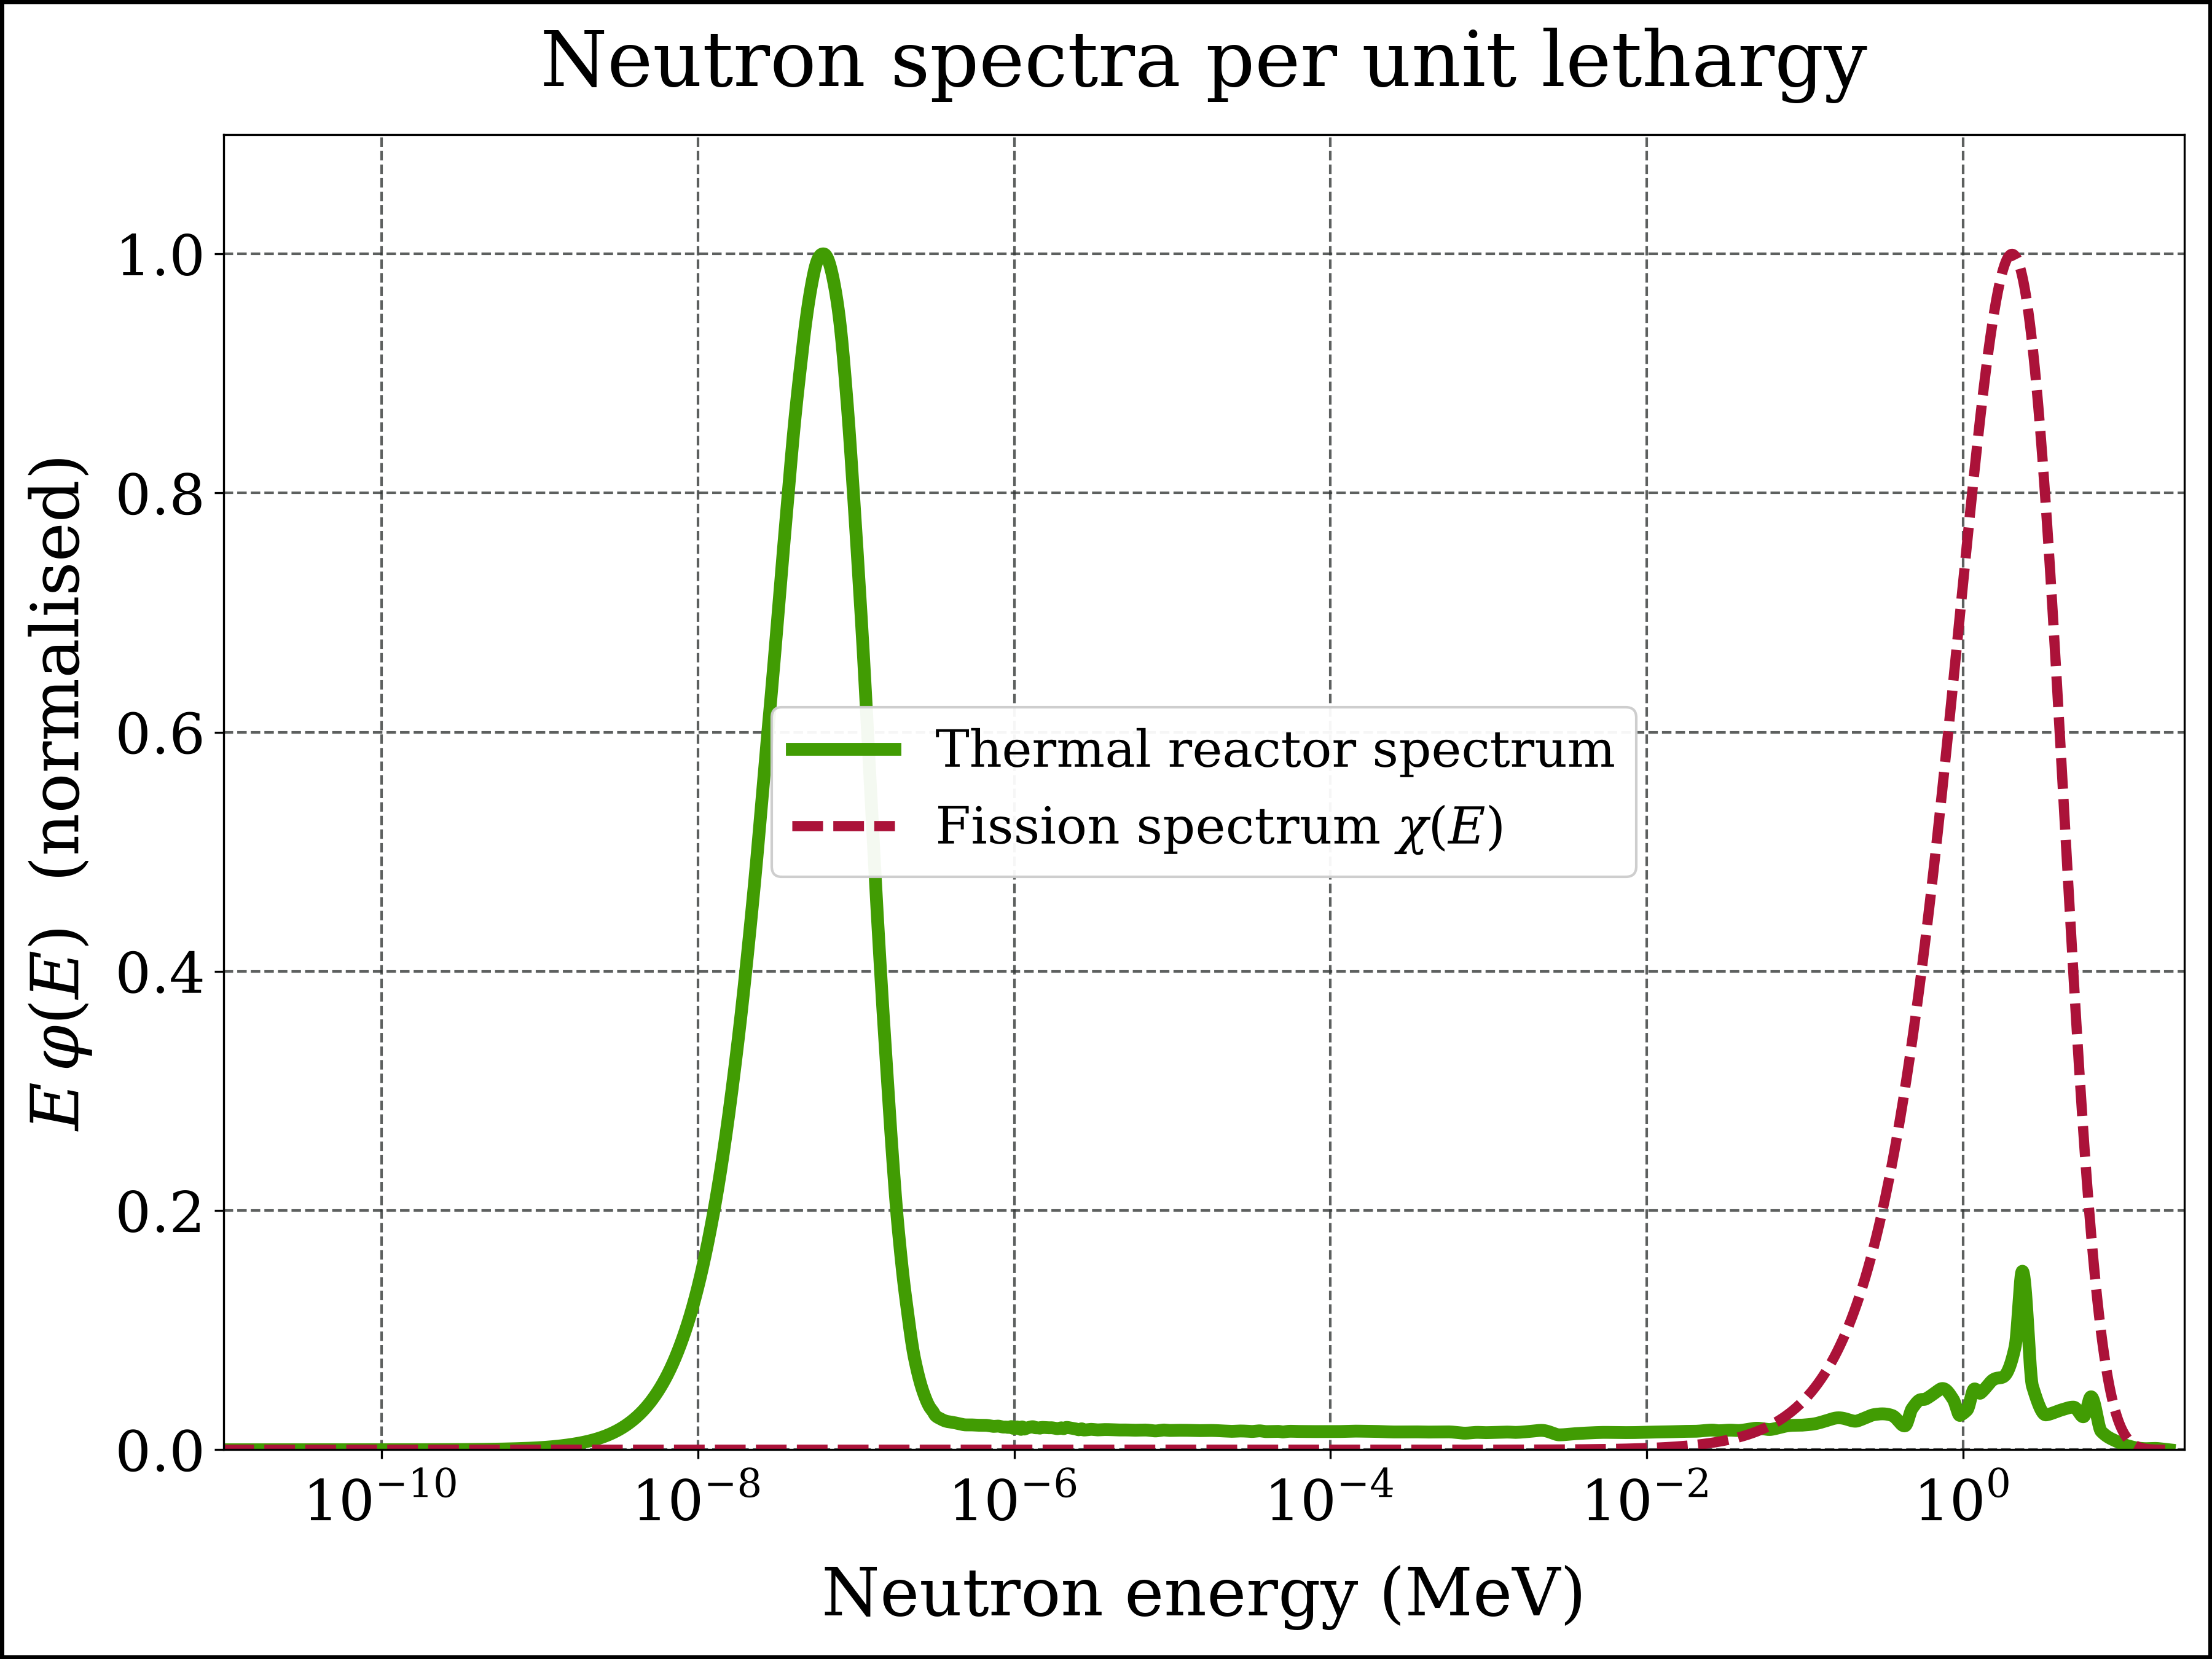

In [44]:
#| echo: true
#| label: fig-spectra-lethargy
#| fig-cap: 'Thermal reactor spectrum and fission spectrum per unit lethargy, each normalised to a maximum of 1'

fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
#
x = E_fine
y = E_fine * ϕ_n(E_fine) / np.max(E_fine * ϕ_n(E_fine))
axes.plot(x, y, label='Thermal reactor spectrum',
          color=color_n, linestyle=ls1, linewidth=lw1, marker=None)
#
x = E_fine
y = E_fine * χ(E_fine) / np.max(E_fine * χ(E_fine))
axes.plot(x, y, label=r'Fission spectrum $\chi(E)$',
          color=color_pu239, linestyle=ls2, linewidth=lw2, marker=None)
#
title       =  'Neutron spectra per unit lethargy'
xlabel      =  'Neutron energy (MeV)'
ylabel      =  r'$E\,\varphi(E)$  (normalised)'
xlims       =  [E_min, E_max*1.25]
ylims       =  [0, 1.1]
xscale      =  'log'
yscale      =  'linear'
ncol_legend =  1
file_name   =  'spectra_per_lethargy'
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

In [45]:
eta_chi     = {}   # <η> in the fission spectrum           (eq-eta-rr with φ = χ)
alpha_chi   = {}   # <α> = capture rate / fission rate
sigma_f_chi = {}   # fission cross section averaged over the fission spectrum (b)
print('Nuclide   <η>                    <α>                    <σ_f> (b)')
for name, (ν, σ_f, σ_γ, η) in nuclides.items():
    points     = breakpoints_of(ν, σ_f, σ_γ)
    production = integral(lambda E: ν(E) * σ_f(E) * χ(E), points)
    fission    = integral(lambda E: σ_f(E) * χ(E), points)
    capture    = integral(lambda E: σ_γ(E) * χ(E), points)
    eta_chi[name]     = ratio(production, add(fission, capture))
    alpha_chi[name]   = ratio(capture, fission)
    sigma_f_chi[name] = ratio(fission, χ_total)
    print(f'{name:8}  {pm(eta_chi[name])}   {pm(alpha_chi[name])}   {pm(sigma_f_chi[name], 3)}')

Nuclide   <η>                    <α>                    <σ_f> (b)


U-232     3.2241 ± 4.3e-16   0.0601 ± 1.7e-18   2.058 ± 1.3e-16


U-233     2.6232 ± 2.5e-16   0.0318 ± 3.7e-18   1.895 ± 1.1e-16


U-234     2.4550 ± 4.1e-16   0.0918 ± 8.8e-18   1.201 ± 1.3e-16


U-235     2.4685 ± 2.5e-16   0.0788 ± 9.9e-18   1.223 ± 1.4e-16


...

U-238     2.2644 ± 3.3e-16   0.2340 ± 4.8e-17   0.309 ± 5.8e-17


Pu-238    3.0729 ± 4.4e-16   0.0503 ± 3.6e-18   1.961 ± 1.1e-16


Pu-239    3.0642 ± 5.0e-16   0.0353 ± 4.0e-18   1.799 ± 1.1e-16


Pu-240    2.9218 ± 3.2e-16   0.0670 ± 2.9e-18   1.372 ± 8.1e-17


Pu-241    3.0625 ± 3.1e-16   0.0448 ± 5.0e-18   1.628 ± 1.1e-16


## Summary {#sec-summary}

| Nuclide | $\langle\eta\rangle$, thermal reactor spectrum | $\langle\eta\rangle$, fission spectrum | $\langle\alpha\rangle$, fission spectrum |
|:--|--:|--:|--:|
| $^{232}\mathrm{U}$ | `{python} pm(eta_rr['U-232'], 4)` | `{python} pm(eta_chi['U-232'], 4)` | `{python} pm(alpha_chi['U-232'], 4)` |
| $^{233}\mathrm{U}$ | `{python} pm(eta_rr['U-233'], 4)` | `{python} pm(eta_chi['U-233'], 4)` | `{python} pm(alpha_chi['U-233'], 4)` |
| $^{234}\mathrm{U}$ | `{python} pm(eta_rr['U-234'], 4)` | `{python} pm(eta_chi['U-234'], 4)` | `{python} pm(alpha_chi['U-234'], 4)` |
| $^{235}\mathrm{U}$ | `{python} pm(eta_rr['U-235'], 4)` | `{python} pm(eta_chi['U-235'], 4)` | `{python} pm(alpha_chi['U-235'], 4)` |
| $^{236}\mathrm{U}$ | `{python} pm(eta_rr['U-236'], 4)` | `{python} pm(eta_chi['U-236'], 4)` | `{python} pm(alpha_chi['U-236'], 4)` |
| $^{238}\mathrm{U}$ | `{python} pm(eta_rr['U-238'], 4)` | `{python} pm(eta_chi['U-238'], 4)` | `{python} pm(alpha_chi['U-238'], 4)` |
| $^{238}\mathrm{Pu}$ | `{python} pm(eta_rr['Pu-238'], 4)` | `{python} pm(eta_chi['Pu-238'], 4)` | `{python} pm(alpha_chi['Pu-238'], 4)` |
| $^{239}\mathrm{Pu}$ | `{python} pm(eta_rr['Pu-239'], 4)` | `{python} pm(eta_chi['Pu-239'], 4)` | `{python} pm(alpha_chi['Pu-239'], 4)` |
| $^{240}\mathrm{Pu}$ | `{python} pm(eta_rr['Pu-240'], 4)` | `{python} pm(eta_chi['Pu-240'], 4)` | `{python} pm(alpha_chi['Pu-240'], 4)` |
| $^{241}\mathrm{Pu}$ | `{python} pm(eta_rr['Pu-241'], 4)` | `{python} pm(eta_chi['Pu-241'], 4)` | `{python} pm(alpha_chi['Pu-241'], 4)` |

: Spectrum-averaged neutron reproduction factors (ratio of reaction rates, @eq-eta-rr) and capture-to-fission ratios, with their 1σ numerical errors. {#tbl-eta}

**Thermal spectrum.** The selected spectrum is strongly thermalised: a fraction
`{python} pm(thermal_fraction, 3)` of the fluence rate lies below 0.625 eV and only
`{python} pm(fast_fraction, 3)` above 0.1 MeV. $^{233}\mathrm{U}$ has the highest
$\langle\eta\rangle$ (`{python} pm(eta_rr['U-233'])`) and is the only fuel with a
useful margin above 2 (@eq-breeding). $^{235}\mathrm{U}$
(`{python} pm(eta_rr['U-235'])`) and $^{239}\mathrm{Pu}$
(`{python} pm(eta_rr['Pu-239'])`) can sustain a chain reaction but cannot breed in a
thermal spectrum. Note that $^{239}\mathrm{Pu}$ ends up *below* $^{235}\mathrm{U}$ here,
although its value at 0.0253 eV is higher (@sec-thermal-point): the spectrum reaches
into its 0.3 eV resonance, where $\eta$ dips to about 1.7 (@sec-eta-temperature). For
the even-$N$ nuclides the flux-weighted mean overstates $\eta$ many times over - for
$^{238}\mathrm{U}$ `{python} pm(eta_phi['U-238'])` instead of
`{python} pm(eta_rr['U-238'])` - exactly as anticipated in @sec-averaging.

**Fission spectrum.** In the fast spectrum $\alpha$ is small for all fissile nuclides
and $\eta$ of $^{239}\mathrm{Pu}$ climbs to `{python} pm(eta_chi['Pu-239'])`, well above
$^{235}\mathrm{U}$ (`{python} pm(eta_chi['U-235'])`): a fast plutonium reactor has about
one spare neutron per absorption for breeding and to cover losses. $^{238}\mathrm{Pu}$
reaches `{python} pm(eta_chi['Pu-238'])`, the highest value of all plutonium isotopes
(@sec-pu238).

**A warning about the even-$N$ nuclides.** In the fission spectrum
$^{238}\mathrm{U}$ (`{python} pm(eta_chi['U-238'])`) and $^{240}\mathrm{Pu}$
(`{python} pm(eta_chi['Pu-240'])`) also show $\langle\eta\rangle>2$ - yet a sphere of
$^{238}\mathrm{U}$ can never be made critical, and $^{240}\mathrm{Pu}$ needs about
40 kg. $\eta$ counts the neutrons that are *absorbed*; it says nothing about the
neutrons that are *scattered*. In a fast system the decisive competition is between
fission on the one hand and inelastic scattering, capture and leakage on the other.
Inelastic collisions quickly push neutrons below the fission threshold of
$^{238}\mathrm{U}$ (about 1 MeV), after which they can no longer cause fission. This is
the key to @sec-pu238.

# The four-factor formula in practice {#sec-k-inf}

## $\eta$ of thermal neutrons

In the four-factor formula $\eta$ is the reproduction factor of **thermal** neutrons:
absorptions in the resonance region are accounted for by $p$, fissions by fast
neutrons by $\varepsilon$. It is obtained from @eq-eta-rr by restricting both
integrals to the thermal group, $E < 0.625$ eV - here simply the first five decade
segments, the last of which ends at 0.625 eV.

In [46]:
eta_th   = {}   # η of thermal neutrons: the η of the four-factor formula
rates_th = {}   # thermal-group (production, absorption) rates per atom
print('Nuclide   thermal η')
for name, (ν, σ_f, σ_γ, η) in nuclides.items():
    points     = breakpoints_of(ν, σ_f, σ_γ, ϕ_n)
    production = integral(lambda E: ν(E) * σ_f(E) * ϕ_n(E), points, thermal_decades)
    absorption = integral(lambda E: (σ_f(E) + σ_γ(E)) * ϕ_n(E), points, thermal_decades)
    rates_th[name] = (production, absorption)
    eta_th[name]   = ratio(production, absorption)
    print(f'{name:8}  {pm(eta_th[name])}')

Nuclide   thermal η
U-232     1.5866 ± 2.9e-16
U-233     2.2907 ± 2.3e-16
U-234     0.0016 ± 3.4e-20


U-235     2.0793 ± 2.0e-16
U-236     0.0001 ± 1.2e-20
U-238     0.0000 ± 2.2e-21
Pu-238    0.0845 ± 1.1e-17


Pu-239    2.0049 ± 6.1e-17
Pu-240    0.0007 ± 1.3e-19
Pu-241    2.1938 ± 4.4e-17


For the fissile nuclides the thermal $\eta$ hardly differs from the whole-spectrum
value in @tbl-eta, because almost all their absorptions are thermal
(@sec-where-absorbed). For $^{238}\mathrm{U}$, $^{240}\mathrm{Pu}$ and $^{238}\mathrm{Pu}$
it is far below 1: thermal neutrons absorbed in them are captured.

## Low-enriched uranium fuel {#sec-leu}

With @eq-eta-mixture the thermal $\eta$ of uranium fuel follows from the thermal-group
production and absorption rates of $^{235}\mathrm{U}$ and $^{238}\mathrm{U}$. The
enrichment $e$ is the $^{235}\mathrm{U}$ atom fraction; for uranium it differs from the
weight fraction by only about 1 %.

In [47]:
def eta_thermal_uranium(e):
    """Thermal η of uranium with U-235 atom fraction e  (eq-eta-mixture)."""
    (P_5, σP_5), (A_5, σA_5) = rates_th['U-235']
    (P_8, σP_8), (A_8, σA_8) = rates_th['U-238']
    r = (1 - e) / e                                       # N(U-238) / N(U-235)
    production = (P_5 + r * P_8, np.hypot(σP_5, r * σP_8))
    absorption = (A_5 + r * A_8, np.hypot(σA_5, r * σA_8))
    return ratio(production, absorption)

print('U-235 atom fraction        thermal η')
for e, label in [(0.00711, 'natural'), (0.03, ''), (0.04, ''), (0.05, ''),
                 (0.20, 'HALEU limit'), (0.93, 'HEU')]:
    print(f'   {e:7.2%}  {label:12}   {pm(eta_thermal_uranium(e))}')

U-235 atom fraction        thermal η
     0.71%  natural        1.3244 ± 1.4e-16
     3.00%                 1.8369 ± 1.8e-16
     4.00%                 1.8938 ± 1.8e-16
     5.00%                 1.9296 ± 1.9e-16
    20.00%  HALEU limit    2.0459 ± 2.0e-16
    93.00%  HEU            2.0786 ± 2.0e-16


Natural uranium reaches only $\eta=$ `{python} pm(eta_thermal_uranium(0.00711))`,
uranium with 4 % $^{235}\mathrm{U}$ `{python} pm(eta_thermal_uranium(0.04))`. The gain
from enrichment flattens out: above about 20 % the $^{238}\mathrm{U}$ absorptions hardly
matter any more.

## Worked example: $k_\infty$ and reactivity {#sec-k-example}

Take a fresh PWR fuel lattice with 4 % enriched uranium. The thermal $\eta$ comes from
the data above. For the other three factors we use illustrative teaching values - in
practice they depend on the lattice design and are calculated with a lattice code:
$\varepsilon = 1.03$, $p = 0.75$ and $f = 0.92$ (no soluble boron).

In [48]:
# Illustrative teaching values for a fresh PWR fuel lattice at operating
# temperature, without soluble boron (not the data of a specific plant):
ε = 1.03                                    # fast fission factor
p = 0.75                                    # resonance escape probability
f = 0.92                                    # thermal utilisation
η, σ_η = eta_thermal_uranium(0.04)          # thermal η of 4 % enriched uranium (JEFF-4.0)

k_inf   = η * f * p * ε                     # four-factor formula (eq-four-factor)
σ_k_inf = k_inf * σ_η / η                   # only η carries a (numerical) error here
ρ       = (k_inf - 1) / k_inf               # reactivity (eq-reactivity)
print(f'η   = {pm((η, σ_η))}')
print(f'k∞  = η f p ε = {pm((k_inf, σ_k_inf))}')
print(f'ρ   = (k∞ - 1) / k∞ = {ρ:.4f} = {ρ * 1E5:,.0f} pcm')
print()

# Thermal utilisation for which the lattice is exactly critical (k∞ = 1):
f_critical = 1 / (η * p * ε)
print(f'k∞ = 1 requires f = {f_critical:.4f}')

# Rule of thumb: at criticality a 1 % change of f is worth about 1000 pcm
k_1pct   = η * (1.01 * f_critical) * p * ε
Δρ_1pct  = (k_1pct - 1) / k_1pct
print(f'Raising f by 1 % from the critical value changes ρ by {Δρ_1pct * 1E5:,.0f} pcm')

η   = 1.8938 ± 1.8e-16
k∞  = η f p ε = 1.3459 ± 1.3e-16
ρ   = (k∞ - 1) / k∞ = 0.2570 = 25,701 pcm

k∞ = 1 requires f = 0.6836
Raising f by 1 % from the critical value changes ρ by 990 pcm


The fresh lattice has $k_\infty=$ `{python} pm((k_inf, σ_k_inf))`, an excess reactivity
of about `{python} f"{ρ * 1E5:,.0f}"` pcm. To operate at $k=1$ this excess must be
held down. Without leakage, the thermal utilisation would have to be reduced to
$f=$ `{python} f"{f_critical:.3f}"` - in a PWR mainly with soluble boron in the
coolant (@tbl-operator). In a real core leakage ($P_\mathrm{FNL}$, $P_\mathrm{TNL}$),
xenon, samarium and burnable absorbers take part of the excess; the rest is
compensated by boron, which is gradually diluted as the fuel burns up. Near
criticality a 1 % change of $f$ is worth `{python} f"{Δρ_1pct * 1E5:,.0f}"` pcm - the
rule of thumb of @sec-reactivity.

## $\eta$ and the moderator temperature {#sec-eta-temperature}

Thermal neutrons are in approximate equilibrium with the moderator; their energy
distribution is close to a Maxwell-Boltzmann spectrum

$$
\varphi_\mathrm{M}(E) = \frac{E}{(k_\mathrm{B}T)^2}\, e^{-E/k_\mathrm{B}T},
$$ {#eq-maxwellian}

with $k_\mathrm{B}T = 0.0253$ eV at 20 °C and 0.0494 eV at 300 °C. As the moderator
heats up, the thermal neutrons become faster. How $\eta$ responds depends on the
nuclide:

In [49]:
k_B = 8.617333E-11                       # Boltzmann constant, MeV/K

def maxwellian(E, T_C):
    """Maxwell-Boltzmann neutron fluence-rate spectrum per unit energy at the
    temperature T_C (°C), normalised to 1  (eq-maxwellian); E in MeV."""
    kT = k_B * (T_C + 273.15)
    return E / kT**2 * np.exp(-E / kT)

T_moderator_C   = np.arange(20, 401, 20)              # moderator temperatures, °C
maxwell_decades = decade_segments(E_min, 1.0E-05)     # up to 10 eV (> 100 kT): the whole Maxwellian

eta_maxwell = {}   # thermal η versus temperature
eta_20C     = {}   # (value, 1σ) at  20 °C
eta_300C    = {}   # (value, 1σ) at 300 °C
for name in ['U-233', 'U-235', 'Pu-239', 'Pu-241']:
    ν, σ_f, σ_γ, η = nuclides[name]
    points = breakpoints_of(ν, σ_f, σ_γ)
    values = []
    for T in T_moderator_C:
        production = integral(lambda E: ν(E) * σ_f(E) * maxwellian(E, T), points, maxwell_decades)
        absorption = integral(lambda E: (σ_f(E) + σ_γ(E)) * maxwellian(E, T), points, maxwell_decades)
        η_T, σ_η_T = ratio(production, absorption)
        values.append(η_T)
        if T == 20:
            eta_20C[name] = (η_T, σ_η_T)
        if T == 300:
            eta_300C[name] = (η_T, σ_η_T)
    eta_maxwell[name] = np.array(values)
    print(f'{name:8}  20 °C: {pm(eta_20C[name])}    300 °C: {pm(eta_300C[name])}')

U-233     20 °C: 2.2955 ± 2.6e-16    300 °C: 2.2777 ± 3.7e-16


U-235     20 °C: 2.0790 ± 2.0e-16    300 °C: 2.0750 ± 4.1e-16


Pu-239    20 °C: 2.0481 ± 2.4e-16    300 °C: 1.8940 ± 1.9e-16


Pu-241    20 °C: 2.1832 ± 2.0e-16    300 °C: 2.1975 ± 2.7e-16


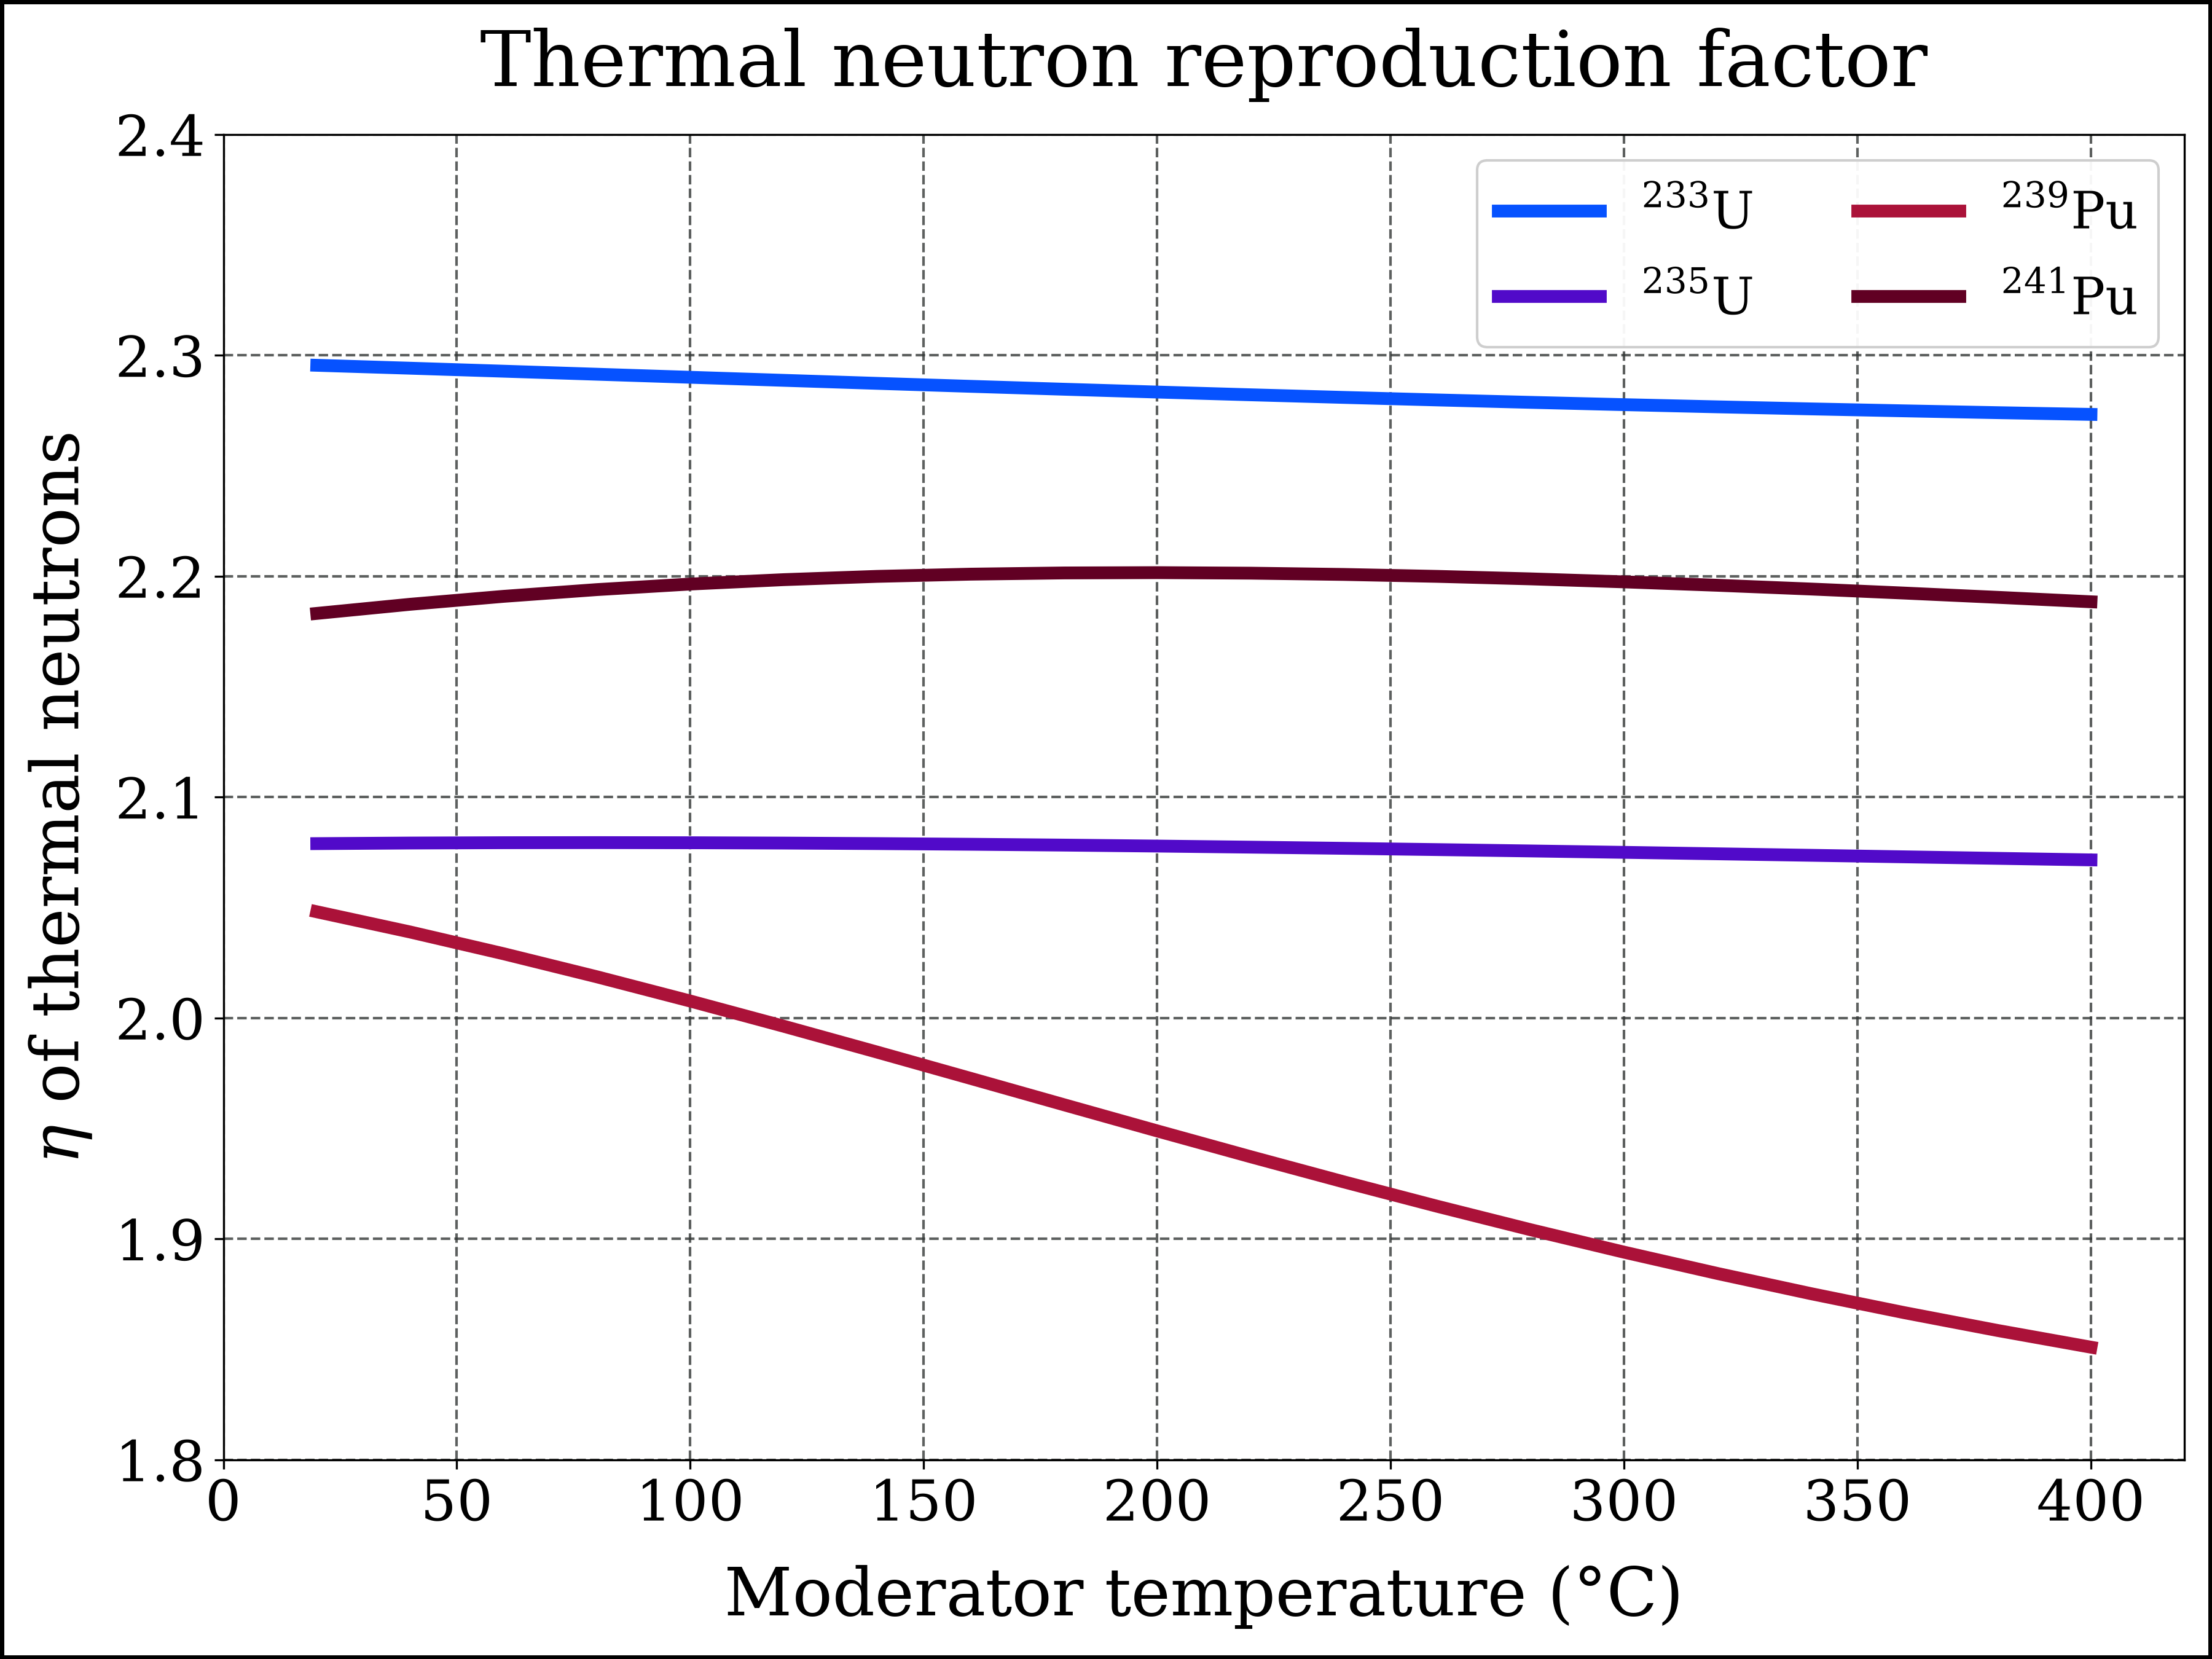

In [50]:
#| echo: true
#| label: fig-eta-thermal-temperature
#| fig-cap: 'Reproduction factor of thermal neutrons (Maxwellian spectrum) versus moderator temperature'

fig, axes = plt.subplots(nrows=1, ncols=1, sharex=True, sharey=True)
#
x = T_moderator_C
y = eta_maxwell['U-233']
axes.plot(x, y, label=r'$\mathrm{^{233}U}$',
          color=color_u233, linestyle=ls1, linewidth=lw1, marker=None)
#
y = eta_maxwell['U-235']
axes.plot(x, y, label=r'$\mathrm{^{235}U}$',
          color=color_u235, linestyle=ls1, linewidth=lw1, marker=None)
#
y = eta_maxwell['Pu-239']
axes.plot(x, y, label=r'$\mathrm{^{239}Pu}$',
          color=color_pu239, linestyle=ls1, linewidth=lw1, marker=None)
#
y = eta_maxwell['Pu-241']
axes.plot(x, y, label=r'$\mathrm{^{241}Pu}$',
          color=color_pu241, linestyle=ls1, linewidth=lw1, marker=None)
#
title       =  'Thermal neutron reproduction factor'
xlabel      =  'Moderator temperature (°C)'
ylabel      =  r'$\eta$ of thermal neutrons'
xlims       =  [0, 420]
ylims       =  [1.8, 2.4]
xscale      =  'linear'
yscale      =  'linear'
ncol_legend =  2
file_name   =  'eta_thermal_vs_moderator_temperature'
add_to_plot(fig, axes, title, xlabel, ylabel, xlims, ylims, xscale, yscale, ncol_legend, file_name)

@fig-eta-thermal-temperature shows the result:

* $^{235}\mathrm{U}$: $\eta$ is almost independent of temperature
  (`{python} pm(eta_20C['U-235'])` at 20 °C, `{python} pm(eta_300C['U-235'])` at 300 °C).
* $^{239}\mathrm{Pu}$: $\eta$ falls markedly, from `{python} pm(eta_20C['Pu-239'])` to
  `{python} pm(eta_300C['Pu-239'])`, because the warmer neutrons overlap more and more
  with its capture-rich 0.3 eV resonance.
* $^{241}\mathrm{Pu}$ changes little, and $^{233}\mathrm{U}$ decreases slowly.

**Operational consequence.** As plutonium builds up during burnup - or in a core
with MOX fuel - heating the moderator lowers $\eta$ of the fuel. This adds a negative
contribution to the moderator temperature coefficient, which therefore becomes more
negative towards the end of a cycle and in plutonium-bearing cores.

> In a real core the thermal spectrum is somewhat "hardened" by absorption - the
> effective neutron temperature is higher than the moderator temperature - so the
> curves are indicative rather than exact.

# The secret of plutonium-238 {#sec-pu238}

At first sight $^{238}\mathrm{Pu}$ is a poor nuclear fuel. For thermal neutrons the
JEFF-4.0 data give a fission cross section of only
`{python} f"{σ_nf_pu238(E_th):.1f}"` b - compared with
`{python} f"{σ_nf_pu239(E_th):.0f}"` b for $^{239}\mathrm{Pu}$ - and a capture cross
section of `{python} f"{σ_nγ_pu238(E_th):.0f}"` b. (Mughabghab's *Atlas of Neutron
Resonances* lists 17.9 ± 0.4 b and 540 ± 7 b.) With
$\bar{\nu}=$ `{python} f"{yield_fn_pu238(E_th):.2f}"`, its thermal reproduction factor
is only $\eta=$ `{python} f"{nrf_pu238(E_th):.3f}"`, and averaged over the thermal
group `{python} pm(eta_th['Pu-238'])`. In a thermal reactor $^{238}\mathrm{Pu}$ is a
neutron absorber, not a fuel.

Yet a bare sphere of $^{238}\mathrm{Pu}$ metal (density about 19.8 g/cm³) is
calculated to become critical at only 9 - 10 kg - as little as $^{239}\mathrm{Pu}$, and
far less than $^{235}\mathrm{U}$:

| Nuclide (bare metal sphere) | Critical mass (kg) | Sphere diameter (cm) |
|:--|--:|--:|
| $^{238}\mathrm{Pu}$ | 9.04 - 10.07 | 9.5 - 9.9 |
| $^{239}\mathrm{Pu}$ | 10 | 9.9 |
| $^{241}\mathrm{Pu}$ | 12 | 10.5 |
| $^{233}\mathrm{U}$ | 15 | 11 |
| $^{240}\mathrm{Pu}$ | 40 | 15 |
| $^{235}\mathrm{U}$ | 52 | 17 |
| $^{238}\mathrm{U}$ | not critical at any mass | - |

: Bare-sphere critical masses of metallic actinides (compiled values; see References). {#tbl-critical-mass}

The next cell compares $^{238}\mathrm{Pu}$ with its neighbours at three energies:
thermal, 30 keV (neutrons slowed down by inelastic collisions) and 1 MeV (fission
neutrons).

In [51]:
# Point values of the interpolated JEFF-4.0 data (no integration -> no numerical error)
print('Energy      Nuclide     σ_f (b)      σ_γ (b)       ν̄        η')
for E, label in [(E_th, '0.0253 eV'), (3.0E-02, '30 keV'), (1.0, '1 MeV')]:
    for name in ['Pu-238', 'Pu-239', 'Pu-240', 'U-238']:
        ν, σ_f, σ_γ, η = nuclides[name]
        print(f'{label:10}  {name:8} {σ_f(E):11.5f} {σ_γ(E):12.5f} {ν(E):8.3f} {η(E):8.3f}')
    print()

Energy      Nuclide     σ_f (b)      σ_γ (b)       ν̄        η
0.0253 eV   Pu-238      15.96592    534.94047    2.910    0.084
0.0253 eV   Pu-239     750.70543    271.43241    2.873    2.110
0.0253 eV   Pu-240       0.07460    285.59773    2.783    0.001
0.0253 eV   U-238        0.00002      2.68884    2.390    0.000

30 keV      Pu-238       0.74680      0.62876    2.911    1.580
30 keV      Pu-239       1.69868      0.46156    2.852    2.242
30 keV      Pu-240       0.10154      0.68243    2.787    0.361
30 keV      U-238        0.00007      0.43850    2.394    0.000

1 MeV       Pu-238       2.04004      0.12973    3.055    2.872
1 MeV       Pu-239       1.75080      0.06825    3.020    2.906
1 MeV       Pu-240       1.53001      0.12245    2.921    2.704
1 MeV       U-238        0.01593      0.12490    2.510    0.284



How can a nuclide with such a poor thermal fission cross section be as "good" as
$^{239}\mathrm{Pu}$? The secret has three parts.

1. **No moderator - no thermal neutrons.** In a bare metal sphere the neutrons never
   reach thermal energies. They are born with the fission spectrum (mean energy
   `{python} pm(χ_mean, 2)` MeV, @fig-spectra-lethargy) and are slowed down only by
   inelastic collisions, to some tens or hundreds of keV, before they cause fission,
   are captured or leak out. The "mediocre" thermal fission cross section - and the
   large thermal capture cross section - simply never come into play. The thermal
   value is the wrong yardstick.

2. **The largest fast-fission cross section of all plutonium isotopes.** Averaged
   over the fission spectrum, the JEFF-4.0 data give
   $\langle\sigma_\mathrm{f}\rangle =$ `{python} pm(sigma_f_chi['Pu-238'], 3)` b for
   $^{238}\mathrm{Pu}$, against `{python} pm(sigma_f_chi['Pu-239'], 3)` b for
   $^{239}\mathrm{Pu}$, `{python} pm(sigma_f_chi['Pu-241'], 3)` b for $^{241}\mathrm{Pu}$
   and `{python} pm(sigma_f_chi['Pu-240'], 3)` b for $^{240}\mathrm{Pu}$ (the same ranking
   as the ENDF/B-VII.1 values of Pritychenko and Mughabghab). Capture takes only a
   small share ($\langle\alpha\rangle=$ `{python} pm(alpha_chi['Pu-238'], 3)`), and
   $\bar{\nu}$ is high, so its fast $\eta$ (`{python} pm(eta_chi['Pu-238'])`) is the
   highest of all plutonium isotopes (@tbl-eta, @fig-nrf-pu238-pu239-line).

3. **Practically no fission threshold.** $^{238}\mathrm{Pu}$ has an even number of
   neutrons, but its compound nucleus $^{239}\mathrm{Pu}^*$ is formed with
   $S_\mathrm{n}=5.65$ MeV (@tbl-sn), only a fraction of an MeV below the fission
   barrier of about 6 MeV - much closer than $^{241}\mathrm{Pu}^*$ (5.24 MeV) or
   $^{239}\mathrm{U}^*$ (4.81 MeV). Fission by tunnelling through the top of the barrier
   is therefore strong even at low neutron energies (*sub-threshold fission*). At
   30 keV the fission cross section of $^{238}\mathrm{Pu}$ is still
   `{python} f"{σ_nf_pu238(0.03):.2f}"` b - larger than its capture cross section
   (`{python} f"{σ_nγ_pu238(0.03):.2f}"` b) - whereas $^{240}\mathrm{Pu}$ fissions with
   only `{python} f"{σ_nf_pu240(0.03):.3f}"` b against
   `{python} f"{σ_nγ_pu240(0.03):.2f}"` b capture, and $^{238}\mathrm{U}$ practically not
   at all (`{python} f"{σ_nf_u238(0.03):.1e}"` b).

The third point is the real secret. As shown in @sec-summary, a high $\eta$ in the
fission spectrum is not enough: $^{238}\mathrm{U}$ and $^{240}\mathrm{Pu}$ have it too.
What a fast chain reaction needs is that neutrons which have been **scattered down**
can still cause fission. In $^{238}\mathrm{U}$ they fall below the threshold and are
lost; in $^{240}\mathrm{Pu}$ that happens below a few hundred keV; in
$^{238}\mathrm{Pu}$ fission keeps competing successfully with capture all the way
down to the keV range. Fast $\eta$, fast fission cross section and the absence of a
threshold together make $^{238}\mathrm{Pu}$ behave like a fissile nuclide in an
unmoderated system.

Why only *theoretically*? $^{238}\mathrm{Pu}$ decays by α emission with a half-life of
87.7 years and produces about 0.57 W of heat per gram. A 9.5 kg sphere would
generate some 5.4 kW of decay heat - it would glow and could not be handled without
active cooling. That same heat makes $^{238}\mathrm{Pu}$ the fuel of choice for
radioisotope thermoelectric generators on deep-space missions.

# Conclusions {#sec-conclusions}

* The neutron reproduction factor $\eta=\bar{\nu}/(1+\alpha)$ is the fuel-dependent
  factor of the four-factor formula. It sets an upper limit $k_\infty\le\eta\,\varepsilon$,
  and breeding requires $\eta>2+L$.
* In the four-factor formula $\eta$ is the **thermal** $\eta$. For uranium with 4 %
  $^{235}\mathrm{U}$ the JEFF-4.0 data give `{python} pm(eta_thermal_uranium(0.04))`,
  for natural uranium only `{python} pm(eta_thermal_uranium(0.00711))`.
* Operators act on $k$ mainly through $f$ (boron, control rods). Temperature feedback
  acts through $p$ (Doppler effect), through the moderator density, and through the
  thermal spectrum: $\eta$ of $^{239}\mathrm{Pu}$ falls markedly with moderator
  temperature, which makes the moderator temperature coefficient of plutonium-bearing
  cores more negative.
* Spectrum averages of $\eta$ must be ratios of reaction rates (@eq-eta-rr). A
  flux-weighted mean of $\eta(E)$ is a different quantity and grossly overstates $\eta$
  of the even-$N$ nuclides in a thermal spectrum.
* Splitting every integral into decades and integrating the tabulated data exactly
  (Gauss-Legendre) makes the numerical error negligible; the real uncertainty of the
  results lies in the nuclear data.
* $^{233}\mathrm{U}$ has the highest $\eta$ in a thermal spectrum
  (`{python} pm(eta_rr['U-233'])`) and is the principal candidate fuel for a thermal
  breeder (thorium / $^{233}\mathrm{U}$ cycle).
* $^{239}\mathrm{Pu}$ is the principal fuel of fast breeder reactors: in a fast
  spectrum its $\eta$ rises to `{python} pm(eta_chi['Pu-239'])`.
* $\eta$ alone does not decide whether a fast system can go critical. Fission must
  also out-compete inelastic down-scattering below the fission threshold - which is
  why $^{238}\mathrm{Pu}$, poor for thermal neutrons but excellent for fast neutrons
  and almost without a fission threshold, has a critical mass as small as that of
  $^{239}\mathrm{Pu}$.

## Additional facts

* A major issue with $^{233}\mathrm{U}$ fuel is the high dose rate around fuel
  assemblies. It is caused by the inevitable contaminant $^{232}\mathrm{U}$, whose
  decay chain contains $^{208}\mathrm{Tl}$, which emits a hard 2.6 MeV γ-ray.
* The delayed-neutron fractions of $^{233}\mathrm{U}$ (about 0.0026) and
  $^{239}\mathrm{Pu}$ (about 0.0021) are much smaller than that of $^{235}\mathrm{U}$
  (about 0.0065). The reactivity range between delayed and prompt criticality is
  correspondingly narrower, which makes reactor control more demanding.

# References {.unnumbered}

1. J. R. Lamarsh, A. J. Baratta, *Introduction to Nuclear Engineering*, 3rd ed.,
   Prentice Hall (2001) - neutron life cycle, four- and six-factor formulae, reactivity,
   conversion and breeding, Watt fission spectrum.
2. J. J. Duderstadt, L. J. Hamilton, *Nuclear Reactor Analysis*, Wiley (1976) -
   spectrum averaging of cross sections, one-group diffusion theory.
3. OECD Nuclear Energy Agency, *JEFF-4.0 - Joint Evaluated Fission and Fusion
   nuclear data library* (2025) - source of the cross sections and fission-neutron
   yields used in this notebook, $^{238}\mathrm{Pu}$ included.
4. S. F. Mughabghab, *Atlas of Neutron Resonances*, 5th ed., Elsevier (2006) -
   thermal cross sections of $^{238}\mathrm{Pu}$ for comparison.
5. B. Pritychenko, S. F. Mughabghab, *Neutron Thermal Cross Sections, Westcott
   Factors, Resonance Integrals, Maxwellian Averaged Cross Sections and Astrophysical
   Reaction Rates Calculated from Major Evaluated Data Libraries*, BNL report,
   arXiv:1208.2879 (2012) - fission-spectrum-averaged fission cross sections of the
   plutonium isotopes for comparison.
6. Wikipedia, *Critical mass* (table of bare-sphere critical masses) and
   *Plutonium-238*, accessed 6 October 2026.